## Analysis Environment and Configuration

In [3]:
# ============================================================
# Cell 01 - Analysis Environment, Protocol, Paths, and Plotting
# ============================================================

# ------------------------------------------------------------
# Imports and display configuration
# ------------------------------------------------------------
import hashlib
import json
import os
import platform
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import optimize, stats
from IPython.display import Markdown, display

# Suppress numerical optimization warnings that are not relevant to
# the downstream analysis output.
warnings.filterwarnings("ignore", category=optimize.OptimizeWarning)

# Configure pandas output for readable inspection of analysis tables.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


# ------------------------------------------------------------
# Resolve shared project-code directory
# ------------------------------------------------------------

def resolve_code_dir() -> Path:
    """Locate the directory containing the shared pipeline and protocol modules."""
    # Prefer an explicitly configured project-code directory.
    env_dir = os.environ.get("THESIS_CODE_DIR")
    if env_dir:
        path = Path(env_dir).expanduser().resolve()

        # Require both shared modules before accepting the directory.
        for name in ("data_pipeline.py", "experiment_protocol.py"):
            if not (path / name).exists():
                raise FileNotFoundError(
                    f"THESIS_CODE_DIR does not contain {name}: {path}"
                )
        return path

    # Otherwise search the current working directory and Kaggle inputs.
    candidates = []

    cwd = Path.cwd().resolve()
    if (
        (cwd / "data_pipeline.py").exists()
        and (cwd / "experiment_protocol.py").exists()
    ):
        candidates.append(cwd)

    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for pipeline_file in kaggle_input.rglob("data_pipeline.py"):
            if (pipeline_file.parent / "experiment_protocol.py").exists():
                candidates.append(pipeline_file.parent.resolve())

    # Remove duplicate paths while preserving discovery order.
    candidates = list(dict.fromkeys(candidates))

    if len(candidates) == 1:
        return candidates[0]

    if not candidates:
        raise FileNotFoundError(
            "data_pipeline.py / experiment_protocol.py not found. "
            "Set THESIS_CODE_DIR."
        )

    raise RuntimeError(
        "Several code directories found; set THESIS_CODE_DIR:\n"
        + "\n".join(map(str, candidates))
    )


CODE_DIR = resolve_code_dir()

# Make the shared project modules importable from the notebook.
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))


# ------------------------------------------------------------
# Load centralized experimental protocol
# ------------------------------------------------------------

from experiment_protocol import (  # noqa: E402
    CLASSIFICATION_THRESHOLD,
    CV_SEED,
    EXPECTED_DATASETS,
    HPO_SEED,
    HPO_TRAINING_SIZES,
    MODEL_SEED,
    PRIMARY_METRICS,
    PROTOCOL_VERSION,
    SECONDARY_METRICS,
    SUBSET_SEEDS,
    TABPFN_MODEL_VERSION,
    TEST_SEED,
    TEST_SIZE,
    TRADITIONAL_MODELS,
    TRAINING_SIZES,
    expected_baseline_runs,
    expected_hpo_runs,
    expected_tabpfn_runs,
)


# ------------------------------------------------------------
# Result-file discovery
# ------------------------------------------------------------

# Candidate filenames for the three finalized experiment outputs.
FILE_CANDIDATES = {
    "tabpfn": ("tabpfn_v3_results_final.csv",),
    "default": (
        "traditional_ml_default_results.csv",
        "traditional_ml_default_v2_results.csv",
    ),
    "hpo": ("traditional_ml_hpo_results_final.csv",),
}


def locate_result_file(names) -> Path:
    """Locate exactly one result file from configured and standard search paths."""
    roots = []

    # Allow the result directory to be configured externally.
    env = os.environ.get("THESIS_RESULTS_DIR")
    if env:
        roots.append(Path(env).expanduser())

    # Search common local/Kaggle output locations.
    roots += [
        Path("/kaggle/working"),
        Path.cwd(),
        Path.cwd() / "results",
    ]

    hits = [
        r / n
        for r in roots
        for n in names
        if (r / n).is_file()
    ]

    # If not found locally, search Kaggle input datasets recursively.
    if not hits and Path("/kaggle/input").exists():
        hits = [
            p
            for n in names
            for p in Path("/kaggle/input").rglob(n)
        ]

    # Normalize and deduplicate discovered paths.
    hits = list(dict.fromkeys(p.resolve() for p in hits))

    if len(hits) == 1:
        return hits[0]

    if not hits:
        raise FileNotFoundError(
            f"None of {names} found. Set THESIS_RESULTS_DIR."
        )

    raise RuntimeError(
        f"Ambiguous result file {names}; set THESIS_RESULTS_DIR:\n"
        + "\n".join(map(str, hits))
    )


# Resolve one unambiguous source file for each experiment condition.
RESULT_PATHS = {
    key: locate_result_file(names)
    for key, names in FILE_CANDIDATES.items()
}


# ------------------------------------------------------------
# Analysis output directories
# ------------------------------------------------------------

# Use a writable output location; Kaggle input directories are read-only.
_out_root = os.environ.get("THESIS_ANALYSIS_DIR") or (
    "/kaggle/working"
    if Path("/kaggle/working").exists()
    else Path.cwd()
)

ANALYSIS_DIR = Path(_out_root) / "analysis_nb06"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TABLES_DIR = ANALYSIS_DIR / "tables"

# Create directories required for generated figures and tables.
for _d in (FIGURES_DIR, TABLES_DIR):
    _d.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Shared analysis configuration
# ------------------------------------------------------------

# Combine primary and secondary metrics into one canonical metric list.
ALL_METRICS = tuple(PRIMARY_METRICS) + tuple(SECONDARY_METRICS)

# Match the source-model identifier used in the TabPFN result table.
TABPFN_SOURCE_MODEL = f"tabpfn_{TABPFN_MODEL_VERSION.lower()}"

# Store protocol-defined training sizes and seed count for analysis.
SIZES_ALL = tuple(TRAINING_SIZES)
SIZES_HPO = tuple(HPO_TRAINING_SIZES)
N_SEEDS = len(SUBSET_SEEDS)

# Canonical four-model comparison used throughout Notebook 06.
MODELS4 = ("tabpfn", *TRADITIONAL_MODELS)


# ------------------------------------------------------------
# Plot theme and labels
# ------------------------------------------------------------

# Fixed model colours and markers ensure consistent visual encoding
# across all figures in the analysis notebook.
COLORS = {
    "tabpfn": "#D55E00",
    "logistic_regression": "#0072B2",
    "random_forest": "#009E73",
    "xgboost": "#CC79A7",
}

MARKERS = {
    "tabpfn": "o",
    "logistic_regression": "s",
    "random_forest": "^",
    "xgboost": "D",
}

MODEL_LABELS = {
    "tabpfn": "TabPFN-3",
    "logistic_regression": "Logistic Regression",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
}

DATASET_LABELS = {
    "diabetes": "Diabetes (BRFSS 2015)",
    "cardiovascular": "Cardiovascular",
}

METRIC_LABELS = {
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced accuracy",
    "precision": "Precision",
    "recall": "Recall (sensitivity)",
    "f1": "F1",
    "specificity": "Specificity",
    "predicted_positive_rate": "Predicted-positive rate",
}

# Diverging colour map for figures showing TabPFN-versus-baseline gaps.
GAP_CMAP = LinearSegmentedColormap.from_list(
    "gap",
    ["#2166AC", "#F7F7F7", "#D55E00"],
)

# Named training-size regimes used for grouped analysis and figures.
REGIMES = {
    "tiny (8–16)": (8, 16),
    "small (32–128)": (32, 128),
    "medium (256–1,024)": (256, 1024),
    "large (2,048–8,192)": (2048, 8192),
}


# ------------------------------------------------------------
# Matplotlib configuration
# ------------------------------------------------------------

# Apply one consistent publication-style plotting configuration.
mpl.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.frameon": False,
    "legend.fontsize": 9,
    "figure.constrained_layout.use": False,
    "axes.axisbelow": True,
})


# Keep a record of all figures exported by the notebook.
FIGURE_LOG: list[str] = []


def save_fig(fig, stem: str) -> None:
    """Save PNG and vector PDF versions, display the figure, and log its name."""
    fig.savefig(
        FIGURES_DIR / f"{stem}.png",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES_DIR / f"{stem}.pdf",
        bbox_inches="tight",
    )

    FIGURE_LOG.append(stem)

    # Display the figure during notebook execution, then release it.
    plt.show()
    plt.close(fig)


def size_axis(ax, sizes, rotate=45):
    """Configure a base-2 logarithmic training-size axis."""
    ax.set_xscale("log", base=2)

    # Explicit limits prevent excessive empty space after switching
    # from linear to logarithmic scaling.
    ax.set_xlim(
        sizes[0] / 1.3,
        sizes[-1] * 1.3,
    )

    ax.set_xticks(list(sizes))
    ax.set_xticklabels(
        [f"{n:,}" for n in sizes],
        rotation=rotate,
        ha="right" if rotate else "center",
    )

    # Training sizes are discrete protocol values, so minor ticks are removed.
    ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())

    # Only label the x-axis on the bottom row of multi-panel figures.
    try:
        last_row = ax.get_subplotspec().is_last_row()
    except Exception:
        last_row = True

    if last_row:
        ax.set_xlabel("Training-set size n (log₂ scale)")


def side_cbar(fig, ax_ref, im, label, pad=0.012, width=0.012):
    """Place a colourbar in a separate axis beside a reference plot."""
    pos = ax_ref.get_position()
    cax = fig.add_axes([
        pos.x1 + pad,
        pos.y0,
        width,
        pos.height,
    ])
    fig.colorbar(im, cax=cax, label=label)
    return cax


def cell_grid(ax, n_rows, n_cols):
    """Add white separators between heat-map cells."""
    for k in range(1, n_cols):
        ax.axvline(
            k - 0.5,
            color="white",
            lw=1.2,
        )

    for k in range(1, n_rows):
        ax.axhline(
            k - 0.5,
            color="white",
            lw=1.2,
        )


def model_handles(models=MODELS4):
    """Create consistent legend handles for the selected models."""
    return [
        Line2D(
            [0],
            [0],
            color=COLORS[m],
            marker=MARKERS[m],
            lw=2,
            ms=5,
            label=MODEL_LABELS[m],
        )
        for m in models
    ]


def regime_of(n: int) -> str:
    """Return the named training-size regime containing n."""
    for name, (lo, hi) in REGIMES.items():
        if lo <= n <= hi:
            return name
    return "other"


# ------------------------------------------------------------
# Initialization summary
# ------------------------------------------------------------

print("=" * 72)
print("NOTEBOOK 06 — ANALYSIS INITIALISED")
print("=" * 72)

print(
    f"Protocol:          {PROTOCOL_VERSION}   | "
    f"TabPFN model: {TABPFN_MODEL_VERSION}"
)

print(f"Code dir:          {CODE_DIR}")

for k, v in RESULT_PATHS.items():
    print(f"Result [{k:>7}]:  {v}")

print(f"Output dir:        {ANALYSIS_DIR}")
print(f"Datasets:          {EXPECTED_DATASETS}")
print(f"Training sizes:    {SIZES_ALL}")
print(f"HPO sizes:         {SIZES_HPO}")
print(f"Subset seeds:      {SUBSET_SEEDS}")

NOTEBOOK 06 — ANALYSIS INITIALISED
Protocol:          low_data_tabpfn_v1   | TabPFN model: V3
Code dir:          /kaggle/input/datasets/nicolausdeemese/iu-thesis-nicolas/files
Result [ tabpfn]:  /kaggle/input/datasets/nicolausdeemese/iu-thesis-results/results/tabpfn/tabpfn_v3_results_final.csv
Result [default]:  /kaggle/input/datasets/nicolausdeemese/iu-thesis-results/results/traditional_ml_default/traditional_ml_default_results.csv
Result [    hpo]:  /kaggle/input/datasets/nicolausdeemese/iu-thesis-results/results/traditional_ml_hpo/traditional_ml_hpo_results_final.csv
Output dir:        /kaggle/working/analysis_nb06
Datasets:          ('diabetes', 'cardiovascular')
Training sizes:    (8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192)
HPO sizes:         (32, 64, 128, 256, 512, 1024, 2048, 4096, 8192)
Subset seeds:      (42, 123, 456, 789, 1011)


## Load and Validate Final Result Table

In [4]:
# ============================================================
# Cell 02 - Load and Validate Final Result Tables
# ============================================================

# ------------------------------------------------------------
# Required columns and validation configuration
# ------------------------------------------------------------

# Columns that uniquely identify one experimental result.
KEY = ["dataset", "model", "training_size", "subset_seed"]

# Common columns required by all three result tables.
BASE_REQUIRED = [
    *KEY,
    "protocol_version",
    "model_seed",
    "classification_threshold",
    *ALL_METRICS,
]

# Additional columns required for the HPO result table.
HPO_REQUIRED = [
    *BASE_REQUIRED,
    "cv_seed",
    "hpo_seed",
    "best_cv_score",
]

# Timing values are intentionally excluded because they are not
# directly comparable across separate execution notebooks.
TIMING_COLUMNS = [
    "training_time",
    "prediction_time",
    "hpo_time",
]


# ------------------------------------------------------------
# Result-table validation
# ------------------------------------------------------------

def validate_result_table(
    df,
    *,
    name,
    expected_rows,
    expected_models,
    expected_sizes,
    required,
):
    """Validate schema, experimental coverage, protocol metadata, and metric ranges."""

    # Confirm that all protocol-required columns are present.
    missing = set(required) - set(df.columns)
    assert not missing, (
        f"{name}: missing columns {sorted(missing)}"
    )

    # Confirm the expected number of completed experimental runs.
    assert len(df) == expected_rows, (
        f"{name}: expected {expected_rows} rows, found {len(df)}"
    )

    # Verify the complete expected dataset set.
    assert set(df["dataset"]) == set(EXPECTED_DATASETS), (
        f"{name}: dataset set mismatch"
    )

    # Training sizes, subset seeds, and model seeds must be integer-valued.
    for col in ("training_size", "subset_seed", "model_seed"):
        vals = pd.to_numeric(df[col], errors="coerce")

        assert (
            vals.notna().all()
            and np.isclose(vals, vals.round()).all()
        ), f"{name}: non-integer values in {col}"

    # Verify that every expected training size is represented.
    assert set(df["training_size"].astype(int)) == set(expected_sizes), (
        f"{name}: training-size set mismatch"
    )

    # Verify the complete predefined subset-seed set.
    assert set(df["subset_seed"].astype(int)) == set(SUBSET_SEEDS), (
        f"{name}: subset-seed set mismatch"
    )

    # Verify that only the protocol-defined models are present.
    assert set(df["model"]) == set(expected_models), (
        f"{name}: model set mismatch "
        f"({sorted(set(df['model']))})"
    )

    # Each dataset × model × training size × subset seed combination
    # must occur exactly once.
    dup = df.duplicated(subset=KEY).sum()
    assert dup == 0, (
        f"{name}: {dup} duplicate experimental keys"
    )

    # Confirm that results were generated under the same protocol version.
    assert (df["protocol_version"] == PROTOCOL_VERSION).all(), (
        f"{name}: protocol_version mismatch"
    )

    # Confirm the fixed model seed used by the experiment protocol.
    assert (df["model_seed"].astype(int) == MODEL_SEED).all(), (
        f"{name}: model_seed mismatch"
    )

    # Confirm the classification threshold used for threshold-based metrics.
    assert np.isclose(
        df["classification_threshold"].astype(float),
        CLASSIFICATION_THRESHOLD,
    ).all(), f"{name}: threshold mismatch"

    # HPO-specific validation: CV seed, HPO seed, and best CV score.
    if "cv_seed" in required:
        assert (
            (df["cv_seed"].astype(int) == CV_SEED).all()
            and (df["hpo_seed"].astype(int) == HPO_SEED).all()
        ), f"{name}: cv/hpo seed mismatch"

        assert df["best_cv_score"].astype(float).between(0, 1).all(), (
            f"{name}: best_cv_score outside [0, 1]"
        )

    # All stored evaluation metrics must be finite and lie within [0, 1].
    for metric in ALL_METRICS:
        v = df[metric].astype(float)

        assert (
            np.isfinite(v).all()
            and v.between(0, 1).all()
        ), f"{name}: invalid values in {metric}"


# ------------------------------------------------------------
# Load finalized result tables
# ------------------------------------------------------------

# Read each experiment condition from its resolved result file.
raw_results = {
    k: pd.read_csv(p)
    for k, p in RESULT_PATHS.items()
}


# ------------------------------------------------------------
# Validate each experiment condition
# ------------------------------------------------------------

# TabPFN results cover all protocol-defined training sizes.
validate_result_table(
    raw_results["tabpfn"],
    name="TabPFN-3",
    expected_rows=expected_tabpfn_runs(),
    expected_models={TABPFN_SOURCE_MODEL},
    expected_sizes=SIZES_ALL,
    required=BASE_REQUIRED,
)

# Traditional default configurations cover all training sizes.
validate_result_table(
    raw_results["default"],
    name="Traditional — default",
    expected_rows=expected_baseline_runs(),
    expected_models=set(TRADITIONAL_MODELS),
    expected_sizes=SIZES_ALL,
    required=BASE_REQUIRED,
)

# Traditional HPO results cover only the protocol-defined HPO sizes.
validate_result_table(
    raw_results["hpo"],
    name="Traditional — HPO",
    expected_rows=expected_hpo_runs(),
    expected_models=set(TRADITIONAL_MODELS),
    expected_sizes=SIZES_HPO,
    required=HPO_REQUIRED,
)


# ------------------------------------------------------------
# Standardize analysis-ready columns
# ------------------------------------------------------------

for df in raw_results.values():

    # Remove execution-time columns because timings came from
    # separate experiment notebooks and are not directly comparable.
    df.drop(
        columns=[
            c for c in TIMING_COLUMNS
            if c in df.columns
        ],
        inplace=True,
    )

    # Normalize key columns to integer types for reliable grouping,
    # merging, and comparison in downstream analysis.
    df["training_size"] = df["training_size"].astype(int)
    df["subset_seed"] = df["subset_seed"].astype(int)


# ------------------------------------------------------------
# Validation summary
# ------------------------------------------------------------

print(
    "✓ All three result tables validated "
    "(rows, keys, seeds, protocol metadata, metric ranges)."
)

print("✓ Timing columns dropped by design.")

# Provide a compact overview of the validated result-table coverage.
display(
    pd.DataFrame({
        k: {
            "rows": len(v),
            "columns": v.shape[1],
            "sizes": v.training_size.nunique(),
            "models": v.model.nunique(),
            "seeds": v.subset_seed.nunique(),
        }
        for k, v in raw_results.items()
    }).T
)

✓ All three result tables validated (rows, keys, seeds, protocol metadata, metric ranges).
✓ Timing columns dropped by design.


,rows,columns,sizes,models,seeds
tabpfn,110,14,11,1,5
default,330,14,11,3,5
hpo,270,18,9,3,5


## Build Canonical Results Table and Derived Metrics

In [5]:
# ============================================================
# Cell 03 - Canonical Results Table and Derived Metrics
# ============================================================

# ------------------------------------------------------------
# Standardize experiment conditions
# ------------------------------------------------------------

# Add explicit condition labels to distinguish TabPFN, default,
# and HPO traditional-model results in the combined table.
tabpfn_rows = raw_results["tabpfn"].assign(
    model="tabpfn",
    condition="tabpfn",
)

default_rows = raw_results["default"].assign(
    condition="default",
)

hpo_rows = raw_results["hpo"].assign(
    condition="hpo",
)


# ------------------------------------------------------------
# Build canonical seed-level results table
# ------------------------------------------------------------

# Columns retained for the common downstream analysis table.
CORE = [
    "dataset",
    "training_size",
    "subset_seed",
    "condition",
    "model",
    *ALL_METRICS,
]

# Combine all three experiment conditions into one long-format table.
seed_results = (
    pd.concat(
        [
            tabpfn_rows[CORE],
            default_rows[CORE],
            hpo_rows[CORE],
        ],
        ignore_index=True,
    )
    .sort_values(
        [
            "dataset",
            "training_size",
            "subset_seed",
            "condition",
            "model",
        ]
    )
    .reset_index(drop=True)
)

# Verify the expected total number of seed-level experimental results.
assert len(seed_results) == (
    expected_tabpfn_runs()
    + expected_baseline_runs()
    + expected_hpo_runs()
)

# Ensure each dataset × size × seed × condition × model combination
# occurs only once.
assert not seed_results.duplicated(
    [
        "dataset",
        "training_size",
        "subset_seed",
        "condition",
        "model",
    ]
).any()


# ------------------------------------------------------------
# Preserve HPO-specific metadata
# ------------------------------------------------------------

# Keep HPO validation scores and selected hyperparameters separately
# because they are not common evaluation metrics.
hpo_meta = hpo_rows[
    [
        *KEY,
        "best_cv_score",
        *(
            ["best_params"]
            if "best_params" in hpo_rows
            else []
        ),
    ]
].copy()

# Add the corresponding test ROC-AUC for convenient HPO-specific analysis.
hpo_meta = hpo_meta.merge(
    hpo_rows[
        [*KEY, "roc_auc"]
    ],
    on=KEY,
)


# ------------------------------------------------------------
# Recover fixed test-set prevalence
# ------------------------------------------------------------

# Fallback values from the validated NB02 experiment summary.
# The manifest is preferred when it is available.
PREVALENCE_FALLBACK = {
    "diabetes": 0.1529,
    "cardiovascular": 0.4948,
}


def load_prevalence():
    """Load test prevalence from the experiment manifest, with a validated fallback."""
    roots = []

    # Allow the prepared-data directory to be configured externally.
    for env in ("THESIS_PREPARED_DATA_DIR",):
        if os.environ.get(env):
            roots.append(
                Path(os.environ[env]).expanduser()
            )

    # Search standard locations for the prepared experiment manifest.
    roots += [
        CODE_DIR / "data" / "processed",
        Path.cwd() / "data" / "processed",
    ]

    manifests = [
        r / "experiment_manifest.json"
        for r in roots
        if (r / "experiment_manifest.json").is_file()
    ]

    # Fall back to recursive Kaggle input search when necessary.
    if not manifests and Path("/kaggle/input").exists():
        manifests = list(
            Path("/kaggle/input").rglob(
                "experiment_manifest.json"
            )
        )

    # Normalize and deduplicate discovered manifest paths.
    manifests = list(
        dict.fromkeys(
            p.resolve()
            for p in manifests
        )
    )

    if len(manifests) == 1:
        # Use the final recorded target prevalence for each dataset.
        manifest = json.loads(
            manifests[0].read_text(
                encoding="utf-8"
            )
        )

        prev = {
            name: float(
                meta["cleaning_log"][-1]["target_prevalence"]
            )
            for name, meta in manifest["datasets"].items()
        }

        return (
            prev,
            f"manifest: {manifests[0]}",
        )

    # Use the previously validated NB02 prevalence values when the
    # manifest is unavailable or not uniquely identifiable.
    return (
        dict(PREVALENCE_FALLBACK),
        "fallback constants (NB02 output)",
    )


PREVALENCE, PREVALENCE_SOURCE = load_prevalence()


# ------------------------------------------------------------
# Derive operating-point metrics without model refitting
# ------------------------------------------------------------

# Map each seed-level result to the prevalence of its fixed test dataset.
p_ = seed_results["dataset"].map(PREVALENCE)

# From balanced accuracy = (recall + specificity) / 2:
# specificity can be reconstructed from the stored recall and BA.
seed_results["specificity"] = (
    2 * seed_results["balanced_accuracy"]
    - seed_results["recall"]
)

# Reconstruct the predicted-positive rate from sensitivity,
# specificity, and the fixed test-set prevalence.
seed_results["predicted_positive_rate"] = (
    seed_results["recall"] * p_
    + (1 - seed_results["specificity"]) * (1 - p_)
)

# Independently reconstruct accuracy from the same quantities.
# This serves as an internal consistency check on the stored metrics.
acc_check = (
    seed_results["recall"] * p_
    + seed_results["specificity"] * (1 - p_)
    - seed_results["accuracy"]
).abs()


# ------------------------------------------------------------
# Validate prevalence and derived metrics
# ------------------------------------------------------------

print(
    f"Prevalence source: {PREVALENCE_SOURCE}"
)

print(
    "Test prevalence:  ",
    {
        k: round(v, 4)
        for k, v in PREVALENCE.items()
    },
)

print(
    "Max |accuracy − (recall·p + specificity·(1−p))| = "
    f"{acc_check.max():.2e}  "
    "(identity check on stored metrics)"
)

# A small tolerance allows for rounding in the stored metrics.
assert acc_check.max() < 5e-3, (
    "Stored metrics are inconsistent with the assumed test prevalence "
    "— wrong file or prevalence."
)

# Specificity should theoretically lie in [0, 1]; the small tolerance
# accommodates floating-point/rounding effects at the boundaries.
assert seed_results["specificity"].between(
    -1e-9,
    1 + 1e-9,
).all()


# Register the newly derived metrics for downstream analysis.
DERIVED_METRICS = (
    "specificity",
    "predicted_positive_rate",
)

display(seed_results.head(8))

Prevalence source: manifest: /kaggle/input/datasets/nicolausdeemese/iu-thesis-nicolas/files/data/processed/experiment_manifest.json
Test prevalence:   {'diabetes': 0.1529, 'cardiovascular': 0.4948}
Max |accuracy − (recall·p + specificity·(1−p))| = 9.38e-06  (identity check on stored metrics)


,dataset,training_size,subset_seed,condition,model,roc_auc,pr_auc,accuracy,balanced_accuracy,precision,recall,f1,specificity,predicted_positive_rate
0,cardiovascular,8,42,default,logistic_regression,0.3080,0.3778,0.3594,0.3588,0.3356,0.3009,0.3173,0.4167,0.4436
1,cardiovascular,8,42,default,random_forest,0.3298,0.3932,0.3900,0.3908,0.3997,0.4642,0.4296,0.3173,0.5746
2,cardiovascular,8,42,default,xgboost,0.3985,0.4535,0.3979,0.3985,0.4030,0.4502,0.4253,0.3467,0.5528
3,cardiovascular,8,42,tabpfn,tabpfn,0.3303,0.3899,0.3817,0.3821,0.3852,0.4189,0.4013,0.3453,0.5380
4,cardiovascular,8,123,default,logistic_regression,0.6989,0.7060,0.6665,0.6654,0.7042,0.5620,0.6251,0.7688,0.3949
5,cardiovascular,8,123,default,random_forest,0.6950,0.6685,0.6259,0.6244,0.6677,0.4856,0.5622,0.7633,0.3598
6,cardiovascular,8,123,default,xgboost,0.5711,0.5357,0.5714,0.5711,0.5697,0.5468,0.5580,0.5954,0.4750
7,cardiovascular,8,123,tabpfn,tabpfn,0.6667,0.6616,0.6209,0.6193,0.6664,0.4680,0.5499,0.7705,0.3475


## Paired Differences and Statistical Summaries

In [6]:
# ============================================================
# Cell 04 - Statistical Helpers and Paired-Difference Table
# ============================================================

def summarize_delta(df, by, col="delta"):
    """Compute summary statistics for paired differences."""
    
    # Classify each paired difference as a win, loss, or tie.
    d = df.assign(
        _pos=(df[col] > 0).astype(int),
        _neg=(df[col] < 0).astype(int),
        _tie=(df[col] == 0).astype(int),
    )

    # Aggregate paired differences within the requested grouping.
    out = d.groupby(list(by), observed=True).agg(
        n=(col, "count"),
        mean=(col, "mean"),
        sd=(col, "std"),
        wins=("_pos", "sum"),
        losses=("_neg", "sum"),
        ties=("_tie", "sum"),
    ).reset_index()

    # Compute the standard error and t-based 95% confidence interval.
    out["se"] = out["sd"] / np.sqrt(out["n"])
    tcrit = stats.t.ppf(0.975, (out["n"] - 1).clip(lower=1))
    out["ci_lo"] = out["mean"] - tcrit * out["se"]
    out["ci_hi"] = out["mean"] + tcrit * out["se"]

    # Standardised paired effect size: mean difference / SD of differences.
    out["dz"] = np.where(
        out["sd"] > 0,
        out["mean"] / out["sd"],
        np.nan,
    )

    # Proportion of paired observations where TabPFN exceeds the comparator.
    out["win_rate"] = out["wins"] / out["n"]

    return out


# Keys used to preserve pairing across models and metrics.
PAIR_KEYS = ["dataset", "training_size", "subset_seed"]

# Metrics evaluated in the paired comparisons.
PAIR_METRICS = [*ALL_METRICS, *DERIVED_METRICS]


def build_pairs(condition: str) -> pd.DataFrame:
    """Build a long table of paired TabPFN − conventional differences."""

    # Select TabPFN results and prefix metric columns to avoid name collisions.
    left = seed_results[
        seed_results["condition"] == "tabpfn"
    ][PAIR_KEYS + PAIR_METRICS].add_prefix("t_")

    # Restore the original pairing-key names after prefixing.
    left = left.rename(columns={f"t_{k}": k for k in PAIR_KEYS})

    # Select the requested conventional-model condition.
    right = seed_results[
        seed_results["condition"] == condition
    ][PAIR_KEYS + ["model"] + PAIR_METRICS]

    # Prefix conventional metrics and identify the conventional model.
    right = (
        right.rename(columns={m: f"o_{m}" for m in PAIR_METRICS})
             .rename(columns={"model": "trad_model"})
    )

    # Match TabPFN and conventional results by dataset, size, and subset seed.
    merged = left.merge(
        right,
        on=PAIR_KEYS,
        how="inner",
        validate="one_to_many",
    )

    # Convert the wide paired table into one row per metric.
    pieces = []
    for m in PAIR_METRICS:
        pieces.append(pd.DataFrame({
            **{k: merged[k] for k in PAIR_KEYS},
            "comparison": condition,
            "trad_model": merged["trad_model"],
            "metric": m,
            "tabpfn": merged[f"t_{m}"],
            "trad": merged[f"o_{m}"],
            "delta": merged[f"t_{m}"] - merged[f"o_{m}"],
        }))

    return pd.concat(pieces, ignore_index=True)


# Build paired comparisons for default and HPO conventional models.
pairs_default = build_pairs("default")
pairs_hpo = build_pairs("hpo")

# Verify complete Cartesian coverage of expected paired runs.
assert len(pairs_default) == expected_baseline_runs() * len(PAIR_METRICS)
assert len(pairs_hpo) == expected_hpo_runs() * len(PAIR_METRICS)

# Combine both comparison regimes into one analysis table.
pairs = pd.concat([pairs_default, pairs_hpo], ignore_index=True)

# All paired metrics must have valid numerical differences.
assert pairs["delta"].notna().all()


# ------------------------------------------------------------
# Per-condition analysis panels
# ------------------------------------------------------------
# Restrict TabPFN to the training sizes available in each condition.
PANEL = {
    "default": seed_results[
        seed_results["condition"].isin(["tabpfn", "default"])
    ].copy(),

    "hpo": seed_results[
        (seed_results["condition"] == "hpo")
        | (
            (seed_results["condition"] == "tabpfn")
            & seed_results["training_size"].isin(SIZES_HPO)
        )
    ].copy(),
}

# Confirm that each panel contains every expected dataset, size,
# subset seed, and model combination.
for cond, panel in PANEL.items():
    sizes = SIZES_ALL if cond == "default" else SIZES_HPO

    assert len(panel) == (
        len(EXPECTED_DATASETS)
        * len(sizes)
        * N_SEEDS
        * len(MODELS4)
    )


def cell_stats(panel, metric):
    """Summarise a metric across the five subset seeds."""
    
    # Compute central tendency and seed-level variability
    # for each dataset, model, and training size.
    return (
        panel.groupby(
            ["dataset", "model", "training_size"],
            observed=True,
        )[metric]
        .agg(
            mean="mean",
            sd="std",
            min="min",
            max="max",
            n="count",
        )
        .reset_index()
    )


print(
    f"✓ Paired-difference table: {len(pairs):,} rows "
    f"({pairs.metric.nunique()} metrics × "
    f"{expected_baseline_runs()} default pairs + "
    f"{expected_hpo_runs()} HPO pairs)."
)

print(
    "✓ Sign convention everywhere: "
    "Δ = TabPFN-3 − conventional  "
    "(positive = TabPFN-3 better)."
)

✓ Paired-difference table: 5,400 rows (9 metrics × 330 default pairs + 270 HPO pairs).
✓ Sign convention everywhere: Δ = TabPFN-3 − conventional  (positive = TabPFN-3 better).


## 1 · Design diagnostics

This section examines the experimental design itself before any model comparison is made. It has two purposes.

**1.1 Headline results.** For each dataset and training size, the mean ROC-AUC and its standard deviation across the five subset seeds are reported for TabPFN-3 and the three conventional models at default hyperparameters. These are the reference values for the sections that follow.

**1.2 Sources of variation.** All models are trained on identical training subsets and evaluated on the same fixed test set. ROC-AUC therefore varies for two reasons: the model used, and the particular subset drawn for a given seed. To gauge their relative size, the total sum of squares of ROC-AUC is decomposed, separately for each dataset and training size, into three components:

- *subset*: variation between subset seeds that is shared by all models;
- *model*: variation between models that is shared across all seeds;
- *interaction (residual)*: the remainder, i.e. seed-specific differences between models.

With one observation per seed–model combination, the interaction and residual terms cannot be separated. The decomposition is therefore descriptive; no significance tests are performed, which is consistent with the use of only five subset seeds throughout this notebook.

**Why this matters for the analysis.** If the subset component is large, the spread of unpaired means and standard deviations mostly reflects how informative the drawn subset was, not how well a model learns. Comparisons between models are then more reliably made on paired differences (TabPFN-3 minus a conventional model, per seed), which cancel the shared subset effect. Sections 2–4 use paired differences for this reason. Figures 1 and 2 show the subset-level difficulty and the resulting variance shares.


Diabetes (BRFSS 2015) — ROC-AUC, mean ± SD over 5 subset seeds (default configurations)


model,TabPFN-3,Logistic Regression,Random Forest,XGBoost,best on seed-mean
training_size,,,,,
8,0.697 ± 0.039,0.701 ± 0.055,0.710 ± 0.035,0.596 ± 0.063,Random Forest
16,0.666 ± 0.148,0.678 ± 0.125,0.670 ± 0.146,0.656 ± 0.121,Logistic Regression
32,0.745 ± 0.045,0.731 ± 0.028,0.751 ± 0.032,0.721 ± 0.032,Random Forest
64,0.770 ± 0.022,0.732 ± 0.035,0.758 ± 0.006,0.730 ± 0.015,TabPFN-3
128,0.778 ± 0.009,0.765 ± 0.012,0.766 ± 0.012,0.742 ± 0.013,TabPFN-3
256,0.796 ± 0.005,0.782 ± 0.016,0.777 ± 0.006,0.740 ± 0.014,TabPFN-3
512,0.806 ± 0.002,0.797 ± 0.005,0.782 ± 0.003,0.753 ± 0.008,TabPFN-3
1024,0.811 ± 0.001,0.804 ± 0.003,0.788 ± 0.003,0.758 ± 0.007,TabPFN-3
2048,0.814 ± 0.000,0.807 ± 0.001,0.792 ± 0.003,0.767 ± 0.005,TabPFN-3



Cardiovascular — ROC-AUC, mean ± SD over 5 subset seeds (default configurations)


model,TabPFN-3,Logistic Regression,Random Forest,XGBoost,best on seed-mean
training_size,,,,,
8,0.594 ± 0.157,0.614 ± 0.176,0.620 ± 0.168,0.553 ± 0.087,Random Forest
16,0.715 ± 0.021,0.697 ± 0.020,0.706 ± 0.018,0.694 ± 0.031,TabPFN-3
32,0.740 ± 0.039,0.693 ± 0.029,0.736 ± 0.023,0.690 ± 0.042,TabPFN-3
64,0.743 ± 0.032,0.689 ± 0.041,0.710 ± 0.037,0.689 ± 0.043,TabPFN-3
128,0.773 ± 0.006,0.761 ± 0.009,0.728 ± 0.021,0.688 ± 0.031,TabPFN-3
256,0.792 ± 0.004,0.785 ± 0.005,0.760 ± 0.007,0.725 ± 0.010,TabPFN-3
512,0.792 ± 0.004,0.784 ± 0.004,0.761 ± 0.004,0.726 ± 0.009,TabPFN-3
1024,0.801 ± 0.001,0.792 ± 0.001,0.773 ± 0.003,0.746 ± 0.004,TabPFN-3
2048,0.802 ± 0.001,0.793 ± 0.001,0.774 ± 0.005,0.755 ± 0.006,TabPFN-3



Subsets on which the model-average ROC-AUC is below 0.55:


,dataset,training_size,subset_seed,mean_over_models,worst_model,best_model
0,cardiovascular,8,42,0.3416,0.3080,0.3985
63,diabetes,16,789,0.4346,0.4033,0.4731


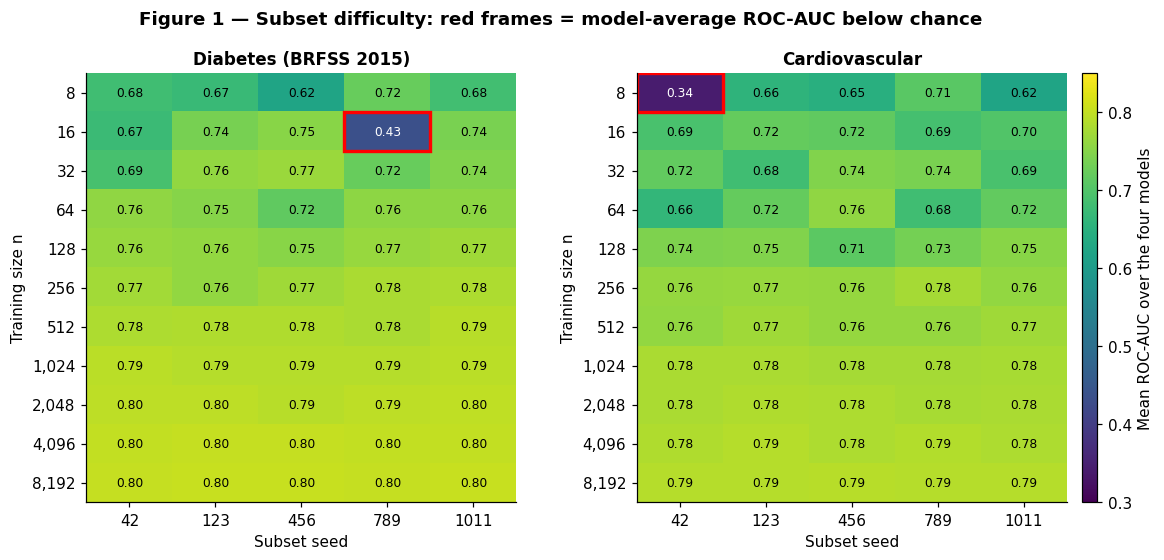

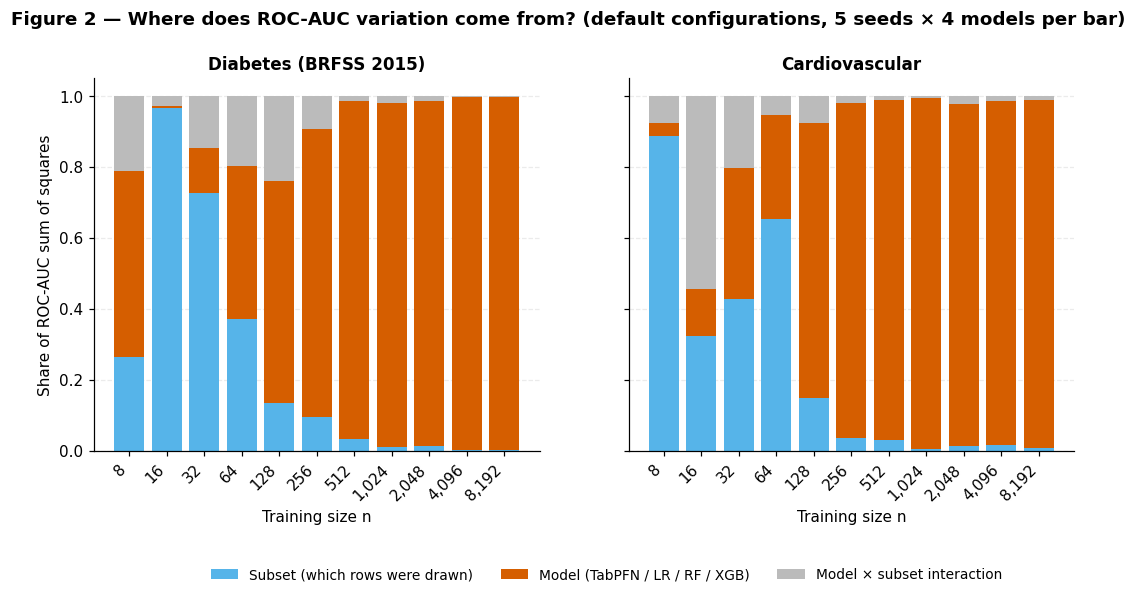

In [7]:
# ============================================================
# Cell 05 - Headline Table, Adversarial Subsets, Variance Decomposition
# ============================================================

# ------------------------------------------------------------
# Headline ROC-AUC table
# ------------------------------------------------------------
# Summarise ROC-AUC across the five subset seeds for each
# dataset, model, and training size.
st_default = cell_stats(PANEL["default"], "roc_auc")

# Format the seed-level summary as mean ± SD.
st_default["cell"] = (
    st_default["mean"].map("{:.3f}".format)
    + " ± "
    + st_default["sd"].map("{:.3f}".format)
)

# Arrange models as columns for a publication-style headline table.
headline = st_default.pivot(
    index=["dataset", "training_size"],
    columns="model",
    values="cell",
)[list(MODELS4)]

# Identify the model with the highest mean ROC-AUC at each
# dataset × training-size cell.
best_idx = (
    st_default.loc[
        st_default.groupby(["dataset", "training_size"])["mean"].idxmax()
    ]
    .set_index(["dataset", "training_size"])["model"]
)

headline["best on seed-mean"] = best_idx.map(MODEL_LABELS)
headline = headline.rename(columns=MODEL_LABELS)

# Save the headline table for downstream reporting.
headline.to_csv(TABLES_DIR / "headline_roc_auc_default.csv")

# LaTeX export is optional because recent pandas versions
# may require Jinja2 for DataFrame.to_latex().
try:
    (
        TABLES_DIR / "headline_roc_auc_default.tex"
    ).write_text(
        headline.to_latex(escape=True),
        encoding="utf-8",
    )
except Exception as exc:
    print("LaTeX export skipped:", type(exc).__name__)

# Display the headline table separately for each dataset.
for ds in EXPECTED_DATASETS:
    print(
        f"\n{DATASET_LABELS[ds]} — ROC-AUC, mean ± SD over "
        f"{N_SEEDS} subset seeds (default configurations)"
    )
    display(headline.loc[ds])


# ------------------------------------------------------------
# Subset-level difficulty
# ------------------------------------------------------------
# Compute the mean ROC-AUC across all four models for each
# dataset × training-size × subset-seed combination.
difficulty = (
    PANEL["default"]
    .groupby(
        ["dataset", "training_size", "subset_seed"],
        observed=True,
    )["roc_auc"]
    .agg(
        mean_over_models="mean",
        worst_model="min",
        best_model="max",
    )
    .reset_index()
)

# Flag subsets with a low model-average ROC-AUC.
adversarial = (
    difficulty[difficulty["mean_over_models"] < 0.55]
    .sort_values("mean_over_models")
)

print(
    "\nSubsets on which the model-average ROC-AUC is below 0.55:"
)
display(
    adversarial
    if len(adversarial)
    else pd.DataFrame({"note": ["none"]})
)


# ------------------------------------------------------------
# Two-way variance decomposition: subset × model
# ------------------------------------------------------------
def variance_shares(mat):
    """Return subset, model, and interaction/residual shares of total SS."""
    
    # mat has shape: subset seeds × models.
    grand = mat.mean()

    # Total variation around the grand mean.
    ss_total = ((mat - grand) ** 2).sum()

    # Variation explained by differences between subset seeds.
    ss_subset = (
        mat.shape[1]
        * ((mat.mean(axis=1) - grand) ** 2).sum()
    )

    # Variation explained by differences between models.
    ss_model = (
        mat.shape[0]
        * ((mat.mean(axis=0) - grand) ** 2).sum()
    )

    # Remaining variation represents model × subset interaction
    # plus any residual component in this balanced two-way layout.
    ss_res = max(ss_total - ss_subset - ss_model, 0.0)

    if ss_total == 0:
        return (np.nan, np.nan, np.nan)

    return (
        ss_subset / ss_total,
        ss_model / ss_total,
        ss_res / ss_total,
    )


# Compute variance components separately for each dataset and size.
rows = []

for (ds, n), g in PANEL["default"].groupby(
    ["dataset", "training_size"],
    observed=True,
):
    # Construct a balanced subset-seed × model ROC-AUC matrix.
    mat = (
        g.pivot(
            index="subset_seed",
            columns="model",
            values="roc_auc",
        )[list(MODELS4)]
        .to_numpy()
    )

    s, m, r = variance_shares(mat)

    rows.append({
        "dataset": ds,
        "training_size": n,
        "subset_share": s,
        "model_share": m,
        "interaction_share": r,
    })

var_decomp = pd.DataFrame(rows)

# Save variance components for later reporting.
var_decomp.to_csv(
    TABLES_DIR / "variance_decomposition.csv",
    index=False,
)


# ------------------------------------------------------------
# Figure 1 - Subset difficulty heat maps
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 5.2),
    gridspec_kw={"wspace": 0.28},
)
fig.subplots_adjust(right=0.9, top=0.86)

for ax, ds in zip(axes, EXPECTED_DATASETS):

    # Arrange model-averaged ROC-AUC by training size and subset seed.
    mat = (
        difficulty[difficulty.dataset == ds]
        .pivot(
            index="training_size",
            columns="subset_seed",
            values="mean_over_models",
        )
        .loc[list(SIZES_ALL), list(SUBSET_SEEDS)]
    )

    im = ax.imshow(
        mat.to_numpy(),
        aspect="auto",
        cmap="viridis",
        vmin=0.3,
        vmax=0.85,
    )

    ax.set_xticks(range(N_SEEDS))
    ax.set_xticklabels(SUBSET_SEEDS)

    ax.set_yticks(range(len(SIZES_ALL)))
    ax.set_yticklabels([f"{n:,}" for n in SIZES_ALL])

    ax.grid(False)

    # Annotate each cell and highlight model-average ROC-AUC < 0.50.
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.iat[i, j]

            ax.text(
                j,
                i,
                f"{v:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if v < 0.62 else "black",
            )

            if v < 0.5:
                ax.add_patch(
                    plt.Rectangle(
                        (j - 0.5, i - 0.5),
                        1,
                        1,
                        fill=False,
                        ec="red",
                        lw=2.2,
                    )
                )

    ax.set_title(DATASET_LABELS[ds])
    ax.set_xlabel("Subset seed")
    ax.set_ylabel("Training size n")

side_cbar(
    fig,
    axes[1],
    im,
    "Mean ROC-AUC over the four models",
)

fig.suptitle(
    "Figure 1 — Subset difficulty: red frames = "
    "model-average ROC-AUC below chance",
    y=0.97,
    fontweight="bold",
)

save_fig(fig, "fig01_subset_difficulty")


# ------------------------------------------------------------
# Figure 2 - Variance decomposition
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 4.4),
    sharey=True,
)

for ax, ds in zip(axes, EXPECTED_DATASETS):

    v = (
        var_decomp[var_decomp.dataset == ds]
        .sort_values("training_size")
    )

    x = np.arange(len(v))

    # Stack the three sources of ROC-AUC variation.
    ax.bar(
        x,
        v["subset_share"],
        color="#56B4E9",
        label="Subset (which rows were drawn)",
    )

    ax.bar(
        x,
        v["model_share"],
        bottom=v["subset_share"],
        color="#D55E00",
        label="Model (TabPFN / LR / RF / XGB)",
    )

    ax.bar(
        x,
        v["interaction_share"],
        bottom=v["subset_share"] + v["model_share"],
        color="#BBBBBB",
        label="Model × subset interaction",
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{n:,}" for n in v["training_size"]],
        rotation=45,
        ha="right",
    )

    ax.set_title(DATASET_LABELS[ds])
    ax.set_xlabel("Training size n")
    ax.grid(False, axis="x")

axes[0].set_ylabel("Share of ROC-AUC sum of squares")

axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(-0.05, -0.28),
    ncol=3,
)

fig.suptitle(
    "Figure 2 — Where does ROC-AUC variation come from? "
    "(default configurations, 5 seeds × 4 models per bar)",
    y=1.02,
    fontweight="bold",
)

save_fig(fig, "fig02_variance_decomposition")

**Reading Figures 1–2.** Figure 1 shows the mean ROC-AUC over the four models for each subset; red frames mark subsets on which the model average falls below chance. In this run this occurs for two subsets (cardiovascular, n = 8, seed 42; diabetes, n = 16, seed 789), and all four models are below 0.5 on both.

In Figure 2, blue is the share of variance due to the subset draw, orange the share due to the model, and grey the model × subset interaction (residual). At the smallest training sizes the subset share is large but irregular (cardiovascular: about 89 % at n = 8, 32 % at n = 16, 65 % at n = 64; diabetes: about 26 % at n = 8, 97 % at n = 16, 73 % at n = 32). At n = 8 on diabetes the model share (53 %) is larger than the subset share, mainly because default XGBoost scores about ten points below the other models. From n = 256 onward the subset share is at most about 10 % in every bar and differences between models account for most of the variation. These are shares of a total that is itself small at large n, where all models score within a few points of each other, so they show which source dominates, not how large the differences are.

Consequently, comparisons at n ≤ 64 should be interpreted with caution, and Section 2 relies on paired differences (TabPFN-3 minus each conventional model, per seed) rather than on overlapping mean ± SD bands.

## 2 · RQ1 - TabPFN-3 vs conventional models at default hyper-parameters

Sections: 2.1 learning curves · 2.2 paired gap curves · 2.3 gap heat-maps (mean Δ and seed wins) · 2.4 regime summary and
ranks · 2.5 data-efficiency (how many labelled rows does a conventional model need to match TabPFN-3?) · 2.6 secondary metrics ·
2.7 operating-point (threshold 0.5 under balanced training).

#### 2.1 learning curves

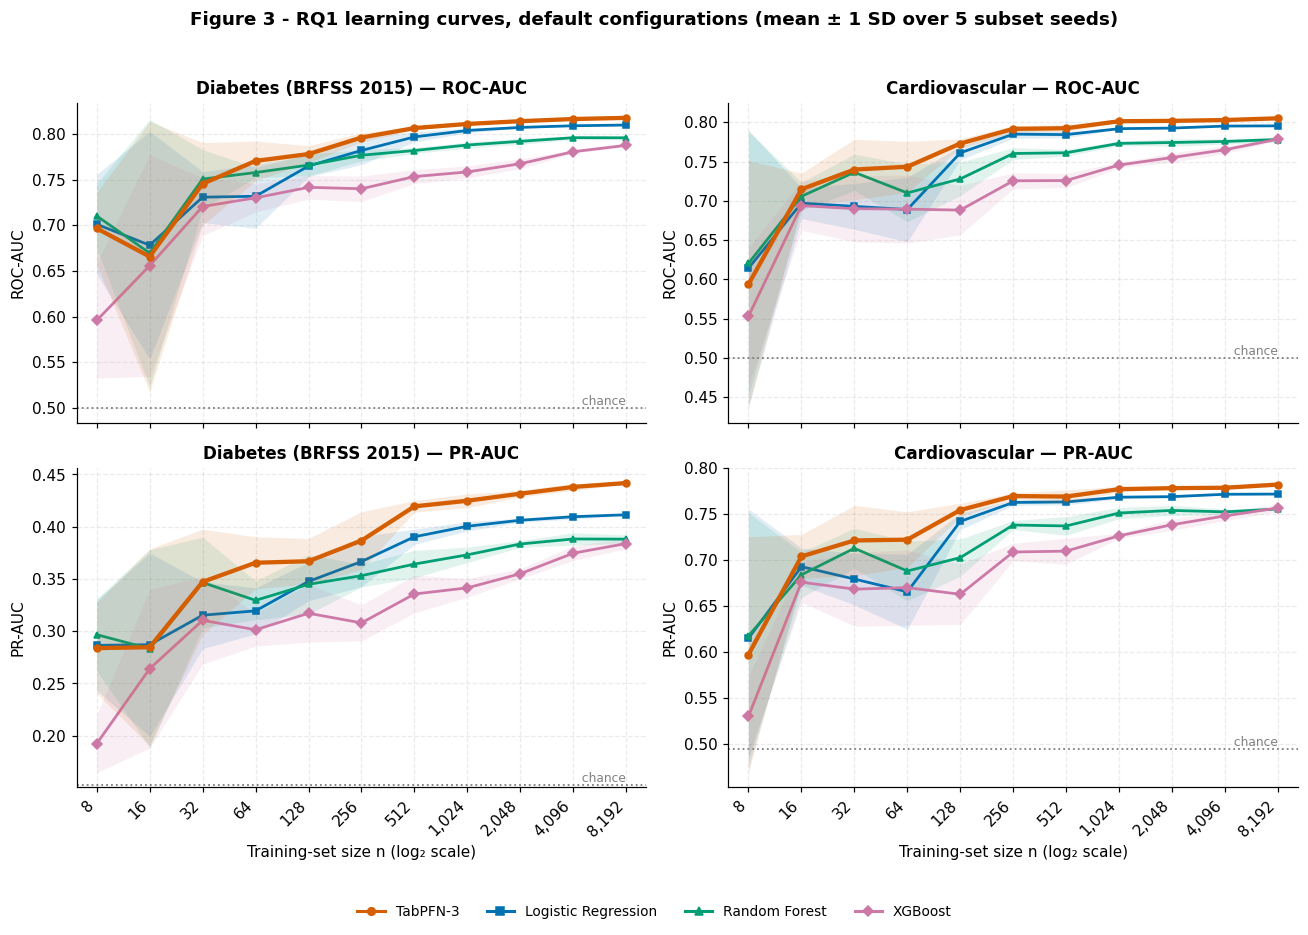

In [8]:
# ============================================================
# Cell 06 - RQ1 Learning Curves
# ============================================================

def fig_learning_curves(cond, sizes, title, stem):
    """Plot primary metrics across training sizes for each dataset."""

    panel = PANEL[cond]

    # Create one row per primary metric and one column per dataset.
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(12, 8.2),
        sharex=True,
    )

    for r, metric in enumerate(PRIMARY_METRICS):
        # Compute mean and SD across subset seeds.
        st = cell_stats(panel, metric)

        for c, ds in enumerate(EXPECTED_DATASETS):
            ax = axes[r, c]

            for model in MODELS4:
                # Select the current dataset and model across training sizes.
                g = (
                    st[
                        (st.dataset == ds)
                        & (st.model == model)
                    ]
                    .sort_values("training_size")
                )

                # Emphasise TabPFN-3 visually while keeping conventional
                # models comparable on the same axes.
                lw, z = (
                    (2.8, 5)
                    if model == "tabpfn"
                    else (1.8, 3)
                )

                # Plot mean performance across subset seeds.
                ax.plot(
                    g.training_size,
                    g["mean"],
                    color=COLORS[model],
                    marker=MARKERS[model],
                    ms=4.5,
                    lw=lw,
                    zorder=z,
                )

                # Show ±1 SD across the five subset seeds.
                ax.fill_between(
                    g.training_size,
                    g["mean"] - g["sd"],
                    g["mean"] + g["sd"],
                    color=COLORS[model],
                    alpha=0.12,
                    lw=0,
                    zorder=z - 1,
                )

            # ROC-AUC chance is 0.5; PR-AUC baseline equals
            # the positive-class prevalence for the dataset.
            chance = (
                0.5
                if metric == "roc_auc"
                else PREVALENCE[ds]
            )

            ax.axhline(
                chance,
                color="grey",
                ls=":",
                lw=1.2,
            )

            ax.text(
                sizes[-1],
                chance,
                " chance",
                va="bottom",
                ha="right",
                color="grey",
                fontsize=8,
            )

            ax.set_title(
                f"{DATASET_LABELS[ds]} — {METRIC_LABELS[metric]}"
            )
            ax.set_ylabel(METRIC_LABELS[metric])

            # Apply the common training-size axis configuration.
            size_axis(ax, sizes)

    # Use a single shared legend for all four models.
    fig.legend(
        handles=model_handles(),
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, -0.02),
    )

    fig.suptitle(
        title,
        fontweight="bold",
        y=1.0,
    )

    fig.tight_layout(
        rect=[0, 0.04, 1, 0.98]
    )

    save_fig(fig, stem)


# Generate RQ1 learning curves for all training sizes
# using the default model configurations.
fig_learning_curves(
    "default",
    SIZES_ALL,
    "Figure 3 - RQ1 learning curves, default configurations "
    "(mean ± 1 SD over 5 subset seeds)",
    "fig03_rq1_learning_curves",
)

#### 2.2 paired gap curves

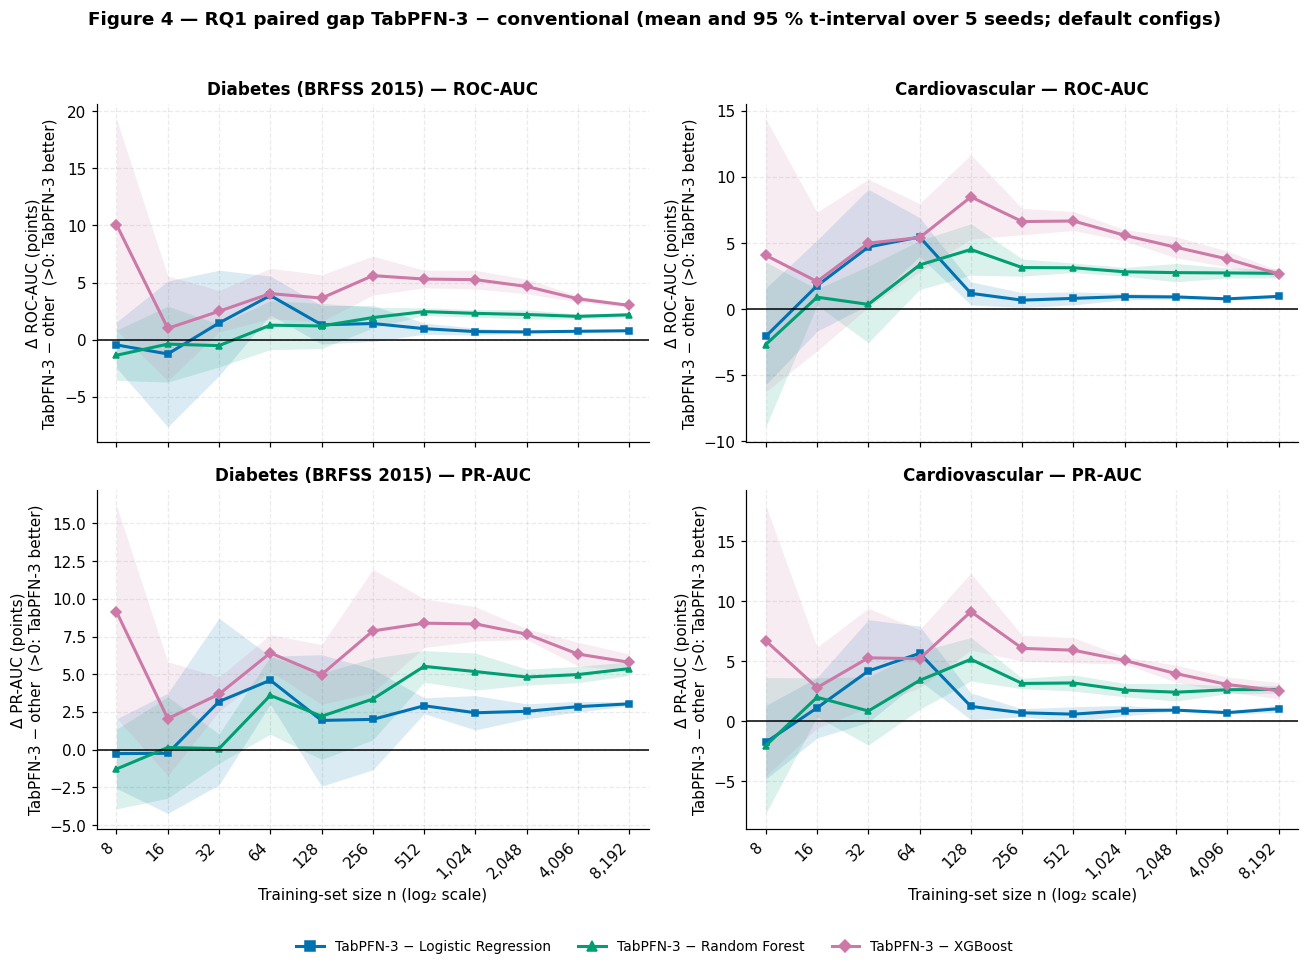

In [9]:
# ============================================================
# Cell 07 - RQ1 Paired Gap Curves with 95% CIs
# ============================================================

# Compute paired TabPFN − conventional summaries for each metric,
# dataset, conventional model, and training size.
gap_default = {
    m: summarize_delta(
        pairs_default[pairs_default.metric == m],
        ["dataset", "trad_model", "training_size"],
    )
    for m in PAIR_METRICS
}

# Save the primary and secondary metric gap tables for reporting.
for m in ALL_METRICS:
    gap_default[m].to_csv(
        TABLES_DIR / f"rq1_gap_{m}.csv",
        index=False,
    )


def fig_gap_curves(
    gap_tables,
    sizes,
    title,
    stem,
    metrics=PRIMARY_METRICS,
):
    """Plot paired TabPFN − conventional gaps with 95% confidence intervals."""

    # Create one row per metric and one column per dataset.
    fig, axes = plt.subplots(
        len(metrics),
        2,
        figsize=(12, 4.3 * len(metrics)),
        sharex=True,
    )

    # Keep axes consistently 2-dimensional when only one metric is plotted.
    axes = np.atleast_2d(axes)

    for r, metric in enumerate(metrics):
        for c, ds in enumerate(EXPECTED_DATASETS):
            ax = axes[r, c]

            for model in TRADITIONAL_MODELS:
                # Select the current dataset and conventional comparator.
                g = gap_tables[metric]
                g = (
                    g[
                        (g.dataset == ds)
                        & (g.trad_model == model)
                    ]
                    .sort_values("training_size")
                )

                # Plot the mean paired difference in percentage points.
                ax.plot(
                    g.training_size,
                    g["mean"] * 100,
                    color=COLORS[model],
                    marker=MARKERS[model],
                    ms=4.5,
                    lw=2,
                )

                # Show the corresponding 95% t-based confidence interval.
                ax.fill_between(
                    g.training_size,
                    g.ci_lo * 100,
                    g.ci_hi * 100,
                    color=COLORS[model],
                    alpha=0.14,
                    lw=0,
                )

            # Zero represents equal performance between TabPFN-3
            # and the conventional comparator.
            ax.axhline(
                0,
                color="black",
                lw=1,
            )

            ax.set_title(
                f"{DATASET_LABELS[ds]} — {METRIC_LABELS[metric]}"
            )

            ax.set_ylabel(
                f"Δ {METRIC_LABELS[metric]} (points)\n"
                "TabPFN-3 − other  (>0: TabPFN-3 better)"
            )

            # Apply the common training-size axis formatting.
            size_axis(ax, sizes)

    # Construct a shared legend identifying each paired comparison.
    handles = [
        Line2D(
            [0],
            [0],
            color=COLORS[m],
            marker=MARKERS[m],
            lw=2,
            label=f"TabPFN-3 − {MODEL_LABELS[m]}",
        )
        for m in TRADITIONAL_MODELS
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, -0.01),
    )

    fig.suptitle(
        title,
        fontweight="bold",
        y=1.0,
    )

    fig.tight_layout(
        rect=[0, 0.04, 1, 0.98]
    )

    save_fig(fig, stem)


# Generate RQ1 paired gap curves for all training sizes
# under the default conventional-model configurations.
fig_gap_curves(
    gap_default,
    SIZES_ALL,
    "Figure 4 — RQ1 paired gap TabPFN-3 − conventional "
    "(mean and 95 % t-interval over 5 seeds; default configs)",
    "fig04_rq1_gap_curves",
)

#### 2.3 gap heat-maps (mean Δ and seed wins)

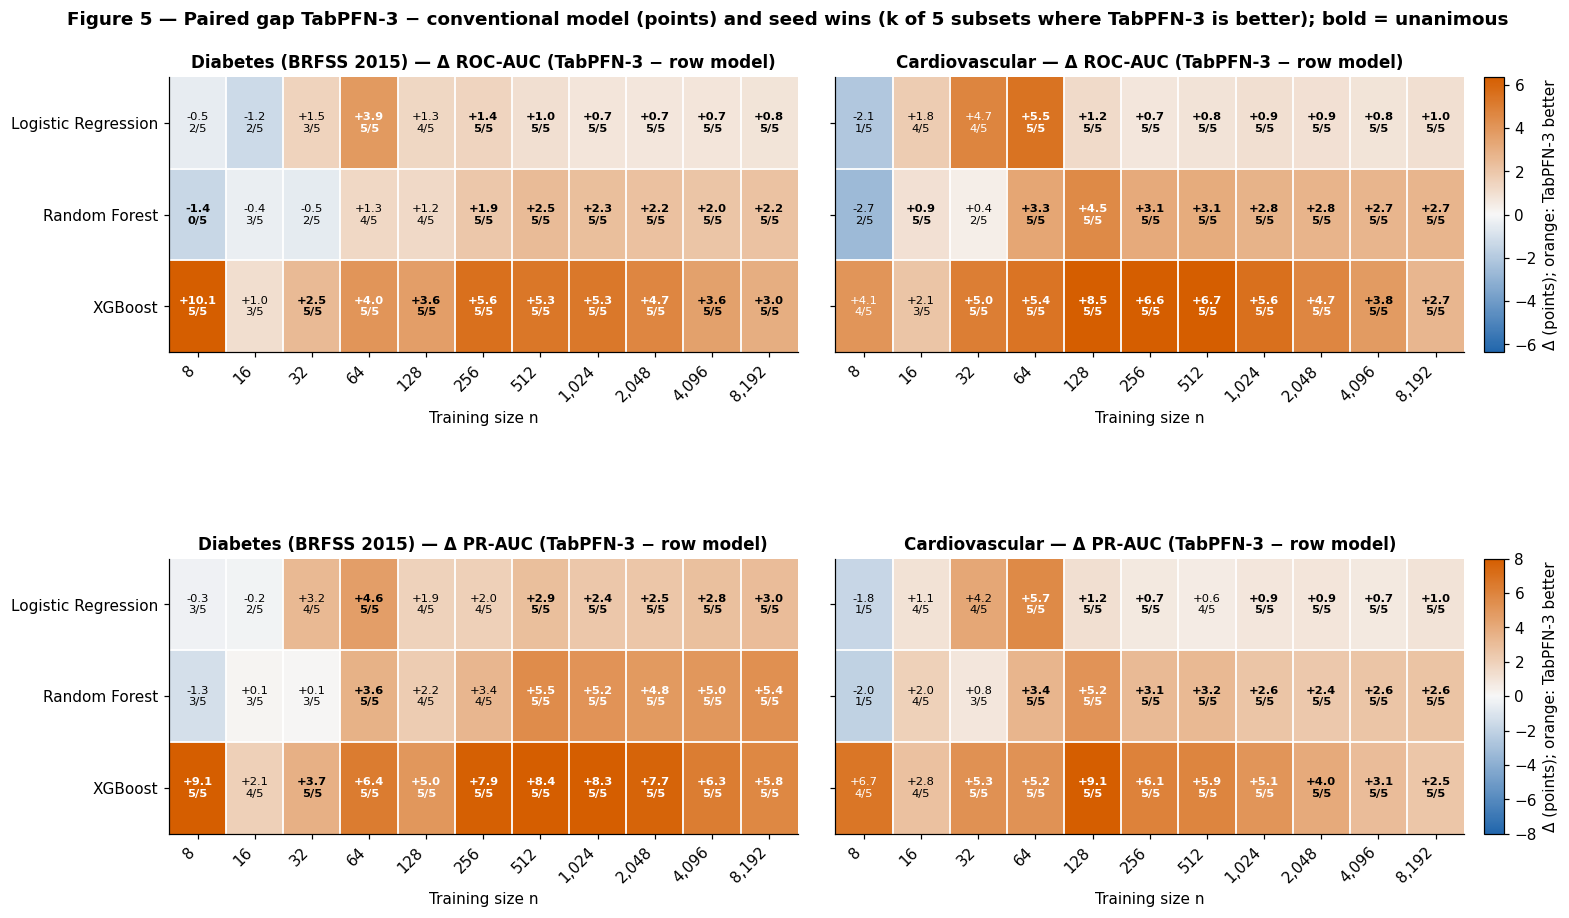

In [10]:
# ============================================================
# Cell 08 - RQ1 Gap Heat Maps: Mean Δ and Seed Wins
# ============================================================

def gap_heatmap(
    ax,
    gtab,
    ds,
    sizes,
    vmax,
    models=TRADITIONAL_MODELS,
):
    """Plot mean paired gaps and seed-win counts for one dataset."""

    # Restrict the gap table to the selected dataset.
    g = gtab[gtab.dataset == ds]

    # Arrange mean gaps and seed wins as model × training-size matrices.
    mean = (
        g.pivot(
            index="trad_model",
            columns="training_size",
            values="mean",
        )
        .loc[list(models), list(sizes)]
    )

    wins = (
        g.pivot(
            index="trad_model",
            columns="training_size",
            values="wins",
        )
        .loc[list(models), list(sizes)]
    )

    # Use a diverging scale centred at zero so positive and negative
    # TabPFN-3 gaps are visually distinguished.
    im = ax.imshow(
        mean.to_numpy() * 100,
        cmap=GAP_CMAP,
        norm=TwoSlopeNorm(
            vcenter=0,
            vmin=-vmax * 100,
            vmax=vmax * 100,
        ),
        aspect="auto",
    )

    ax.grid(False)

    # Training sizes form the horizontal axis.
    ax.set_xticks(range(len(sizes)))
    ax.set_xticklabels(
        [f"{n:,}" for n in sizes],
        rotation=45,
        ha="right",
    )

    # Conventional models form the vertical axis.
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels(
        [MODEL_LABELS[m] for m in models]
    )

    # Annotate each cell with mean gap and number of winning seeds.
    for i in range(len(models)):
        for j in range(len(sizes)):
            v = mean.iat[i, j] * 100
            w = int(wins.iat[i, j])

            # Use white text when the cell is far from the neutral midpoint.
            strong = abs(v) > 0.6 * vmax * 100

            ax.text(
                j,
                i,
                f"{v:+.1f}\n{w}/{N_SEEDS}",
                ha="center",
                va="center",
                fontsize=7.5,
                color="white" if strong else "black",
                fontweight=(
                    "bold"
                    if w in (0, N_SEEDS)
                    else "normal"
                ),
            )

    return im


# Create one panel for each primary metric × dataset combination.
fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 8.6),
    gridspec_kw={
        "hspace": 0.75,
        "wspace": 0.06,
    },
)

fig.subplots_adjust(
    right=0.91,
    top=0.9,
    bottom=0.1,
)

for r, metric in enumerate(PRIMARY_METRICS):

    # Set the colour scale from the 95th percentile of absolute
    # observed mean gaps, while enforcing a practical minimum/maximum.
    vmax = float(
        np.clip(
            gap_default[metric]["mean"].abs().quantile(0.95),
            0.02,
            0.08,
        )
    )

    for c, ds in enumerate(EXPECTED_DATASETS):

        im = gap_heatmap(
            axes[r, c],
            gap_default[metric],
            ds,
            SIZES_ALL,
            vmax,
        )

        # Add cell boundaries to make individual comparisons explicit.
        cell_grid(
            axes[r, c],
            3,
            len(SIZES_ALL),
        )

        axes[r, c].set_title(
            f"{DATASET_LABELS[ds]} — "
            f"Δ {METRIC_LABELS[metric]} "
            "(TabPFN-3 − row model)"
        )

        axes[r, c].set_xlabel("Training size n")

        # Avoid repeating model labels on the right-hand panels.
        if c == 1:
            axes[r, c].set_yticklabels([])

    # Add a shared colour scale to the right side of each metric row.
    side_cbar(
        fig,
        axes[r, 1],
        im,
        "Δ (points); orange: TabPFN-3 better",
    )

fig.suptitle(
    "Figure 5 — Paired gap TabPFN-3 − conventional model "
    "(points) and seed wins (k of 5 subsets where TabPFN-3 is better); "
    "bold = unanimous",
    fontweight="bold",
    y=0.97,
)

save_fig(
    fig,
    "fig05_rq1_gap_heatmaps",
)

#### 2.4 regime summary and ranks


RQ1 regime summary — Δ ROC-AUC (TabPFN-3 − conventional); mean_delta in ROC/PR-AUC units


,dataset,trad_model,regime,sizes,mean_delta,min_delta,max_delta,sizes_tabpfn_ahead,sizes_unanimous,seed_wins,seed_n,seed_win_rate
0,cardiovascular,logistic_regression,tiny (8–16),2,-0.0015,-0.0206,0.0177,1,0,5,10,0.5000
1,cardiovascular,logistic_regression,small (32–128),3,0.0378,0.0119,0.0545,3,2,14,15,0.9333
2,cardiovascular,logistic_regression,"medium (256–1,024)",3,0.0081,0.0067,0.0095,3,3,15,15,1.0000
3,cardiovascular,logistic_regression,"large (2,048–8,192)",3,0.0088,0.0077,0.0096,3,3,15,15,1.0000
4,cardiovascular,random_forest,tiny (8–16),2,-0.0089,-0.0268,0.0090,1,1,7,10,0.7000
5,cardiovascular,random_forest,small (32–128),3,0.0273,0.0036,0.0450,3,2,12,15,0.8000
6,cardiovascular,random_forest,"medium (256–1,024)",3,0.0303,0.0282,0.0314,3,3,15,15,1.0000
7,cardiovascular,random_forest,"large (2,048–8,192)",3,0.0273,0.0270,0.0275,3,3,15,15,1.0000
8,cardiovascular,xgboost,tiny (8–16),2,0.0307,0.0208,0.0406,2,0,7,10,0.7000
9,cardiovascular,xgboost,small (32–128),3,0.0629,0.0498,0.0848,3,3,15,15,1.0000



RQ1 regime summary — Δ PR-AUC (TabPFN-3 − conventional); mean_delta in ROC/PR-AUC units


,dataset,trad_model,regime,sizes,mean_delta,min_delta,max_delta,sizes_tabpfn_ahead,sizes_unanimous,seed_wins,seed_n,seed_win_rate
0,cardiovascular,logistic_regression,tiny (8–16),2,-0.0033,-0.0177,0.0111,1,0,5,10,0.5000
1,cardiovascular,logistic_regression,small (32–128),3,0.0369,0.0123,0.0566,3,2,14,15,0.9333
2,cardiovascular,logistic_regression,"medium (256–1,024)",3,0.0072,0.0058,0.0087,3,2,14,15,0.9333
3,cardiovascular,logistic_regression,"large (2,048–8,192)",3,0.0089,0.0071,0.0104,3,3,15,15,1.0000
4,cardiovascular,random_forest,tiny (8–16),2,-0.0002,-0.0204,0.0199,1,0,5,10,0.5000
5,cardiovascular,random_forest,small (32–128),3,0.0314,0.0085,0.0516,3,2,13,15,0.8667
6,cardiovascular,random_forest,"medium (256–1,024)",3,0.0297,0.0259,0.0319,3,3,15,15,1.0000
7,cardiovascular,random_forest,"large (2,048–8,192)",3,0.0256,0.0241,0.0265,3,3,15,15,1.0000
8,cardiovascular,xgboost,tiny (8–16),2,0.0475,0.0280,0.0671,2,0,8,10,0.8000
9,cardiovascular,xgboost,small (32–128),3,0.0655,0.0521,0.0914,3,3,15,15,1.0000



Mean rank by regime (1 = best of 4; ROC-AUC; averaged over sizes and seeds)


model                               TabPFN-3  Logistic Regression  Random Forest  XGBoost
dataset        regime                                                                    
cardiovascular tiny (8–16)            2.1000               2.5000         2.4000   3.0000
               small (32–128)         1.2667               2.9333         2.2000   3.6000
               medium (256–1,024)     1.0000               2.0000         3.0000   4.0000
               large (2,048–8,192)    1.0000               2.0000         3.2000   3.8000
diabetes       tiny (8–16)            2.5000               2.0000         2.1000   3.4000
               small (32–128)         1.5333               2.8000         2.0000   3.6667
               medium (256–1,024)     1.0000               2.0667         2.9333   4.0000
               large (2,048–8,192)    1.0000               2.0000         3.0000   4.0000

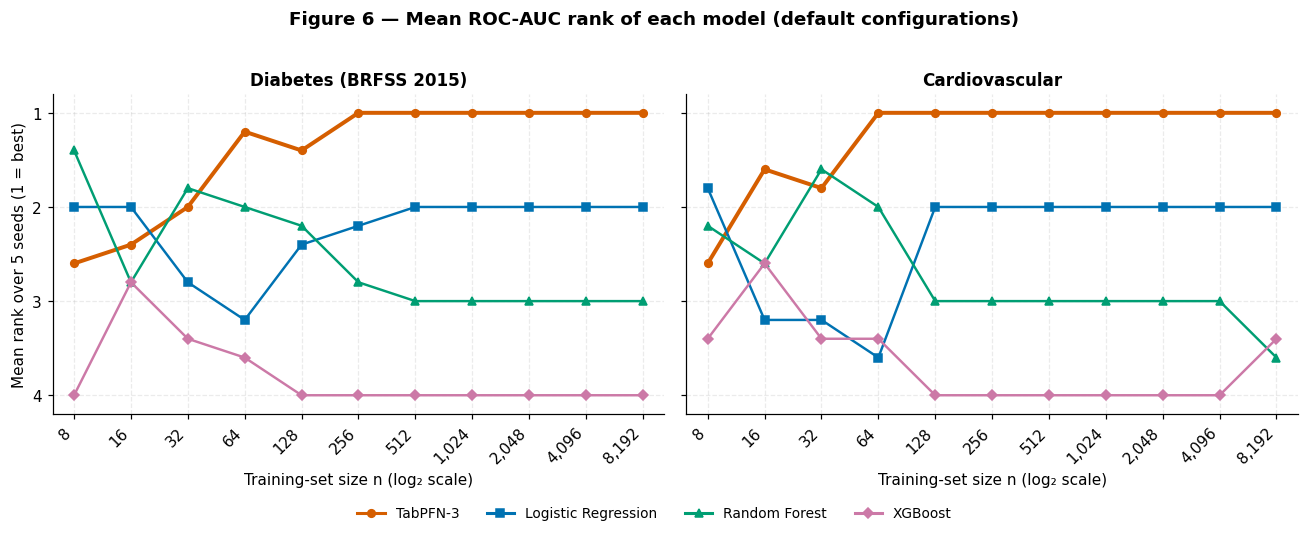

In [11]:
# ============================================================
# Cell 09 - RQ1 Regime Summary and Mean Model Ranks
# ============================================================

# Preserve the predefined ordering of training-data regimes.
REGIME_ORDER = list(REGIMES)


def regime_summary(pairs_df, metric, gap_tab=None):
    """Aggregate paired TabPFN − conventional gaps by training regime."""

    # Reuse precomputed per-size gap summaries when available;
    # otherwise calculate them directly from the paired seed-level data.
    per_size = (
        gap_tab
        if gap_tab is not None
        else summarize_delta(
            pairs_df[pairs_df.metric == metric],
            ["dataset", "trad_model", "training_size"],
        )
    )

    per_size = per_size.copy()

    # Assign each training size to its predefined data-efficiency regime.
    per_size["regime"] = pd.Categorical(
        per_size["training_size"].map(regime_of),
        categories=REGIME_ORDER,
        ordered=True,
    )

    # Aggregate gap magnitude, direction, and seed-level wins within each regime.
    out = (
        per_size
        .groupby(
            ["dataset", "trad_model", "regime"],
            observed=True,
        )
        .agg(
            sizes=("training_size", "count"),
            mean_delta=("mean", "mean"),
            min_delta=("mean", "min"),
            max_delta=("mean", "max"),
            sizes_tabpfn_ahead=(
                "mean",
                lambda s: int((s > 0).sum()),
            ),
            sizes_unanimous=(
                "wins",
                lambda s: int((s == N_SEEDS).sum()),
            ),
            seed_wins=("wins", "sum"),
            seed_n=("n", "sum"),
        )
        .reset_index()
    )

    # Convert accumulated seed wins into an overall seed-level win rate.
    out["seed_win_rate"] = (
        out["seed_wins"] / out["seed_n"]
    )

    return out


# Generate regime summaries for both primary metrics.
rq1_regime = {
    m: regime_summary(
        pairs_default,
        m,
        gap_default[m],
    )
    for m in PRIMARY_METRICS
}

# Save and display the regime-level summaries.
for m, t in rq1_regime.items():
    t.to_csv(
        TABLES_DIR / f"rq1_regime_{m}.csv",
        index=False,
    )

    print(
        f"\nRQ1 regime summary — Δ {METRIC_LABELS[m]} "
        "(TabPFN-3 − conventional); "
        "mean_delta in ROC/PR-AUC units"
    )

    display(t)


# ------------------------------------------------------------
# Mean model ranks
# ------------------------------------------------------------
# Rank all four models within every matched dataset × size × seed
# according to ROC-AUC. Lower rank indicates better performance.
ranked = PANEL["default"].copy()

ranked["rank"] = (
    ranked
    .groupby(
        ["dataset", "training_size", "subset_seed"],
        observed=True,
    )["roc_auc"]
    .rank(
        ascending=False,
        method="average",
    )
)

# Average ranks over the five subset seeds for each dataset × model × size.
rank_tab = (
    ranked
    .groupby(
        ["dataset", "model", "training_size"],
        observed=True,
    )["rank"]
    .mean()
    .reset_index()
)

# Save size-specific mean ranks for reporting.
rank_tab.to_csv(
    TABLES_DIR / "rq1_mean_rank.csv",
    index=False,
)

# Aggregate ranks by data-efficiency regime.
rank_reg = (
    ranked
    .assign(
        regime=ranked["training_size"].map(regime_of)
    )
    .groupby(
        ["dataset", "regime", "model"]
    )["rank"]
    .mean()
    .unstack("model")[list(MODELS4)]
)

rank_reg = rank_reg.rename(columns=MODEL_LABELS)

print(
    "\nMean rank by regime "
    "(1 = best of 4; ROC-AUC; averaged over sizes and seeds)"
)

display(
    rank_reg.reindex(
        REGIME_ORDER,
        level="regime",
    )
)


# ------------------------------------------------------------
# Figure 6 - Mean ROC-AUC rank curves
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.4),
    sharey=True,
)

for ax, ds in zip(axes, EXPECTED_DATASETS):

    for model in MODELS4:
        # Retrieve the mean rank of the current model across subset seeds.
        g = (
            rank_tab[
                (rank_tab.dataset == ds)
                & (rank_tab.model == model)
            ]
            .sort_values("training_size")
        )

        # Emphasise TabPFN-3 while retaining all four model trajectories.
        ax.plot(
            g.training_size,
            g["rank"],
            color=COLORS[model],
            marker=MARKERS[model],
            ms=5,
            lw=(
                2.6
                if model == "tabpfn"
                else 1.6
            ),
        )

    # Rank 1 is best, so invert the visual ordering of the y-axis.
    ax.set_ylim(4.2, 0.8)
    ax.set_yticks([1, 2, 3, 4])
    ax.set_title(DATASET_LABELS[ds])

    # Apply the common training-size axis formatting.
    size_axis(ax, SIZES_ALL)

axes[0].set_ylabel(
    "Mean rank over 5 seeds (1 = best)"
)

# Shared legend for all model trajectories.
fig.legend(
    handles=model_handles(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.06),
)

fig.suptitle(
    "Figure 6 — Mean ROC-AUC rank of each model "
    "(default configurations)",
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()

save_fig(
    fig,
    "fig06_rq1_mean_rank",
)

#### 2.5 data-efficiency (how many labelled rows does a conventional model need to match TabPFN-3?)

Equivalent training size: n at which the conventional model's mean ROC-AUC first reaches TabPFN-3's mean ROC-AUC at n = tabpfn_n


tabpfn_n                                     32     64     128     256     512     1024
condition dataset        trad_model                                                    
default   cardiovascular logistic_regression  102    106    181     999   1,676  >8,192
                         random_forest        142    157  1,012  >8,192  >8,192  >8,192
                         xgboost              836    948  6,150  >8,192  >8,192  >8,192
          diabetes       logistic_regression   85    161    218     497   1,762  >8,192
                         random_forest         29    172    303  >8,192  >8,192  >8,192
                         xgboost              322  2,409  3,571  >8,192  >8,192  >8,192
hpo       cardiovascular logistic_regression   76     81    129   1,501   1,911  >8,192
                         random_forest         99    110    212     648     694  >8,192
                         xgboost              115    125    212     836     877   5,581
          diabetes       logistic_regression  ≤32     39     56     408   1,594  >8,192
                         random_forest        ≤32     54    148     412   1,971   6,134
                         xgboost               68    255    338     873   2,248   3,363

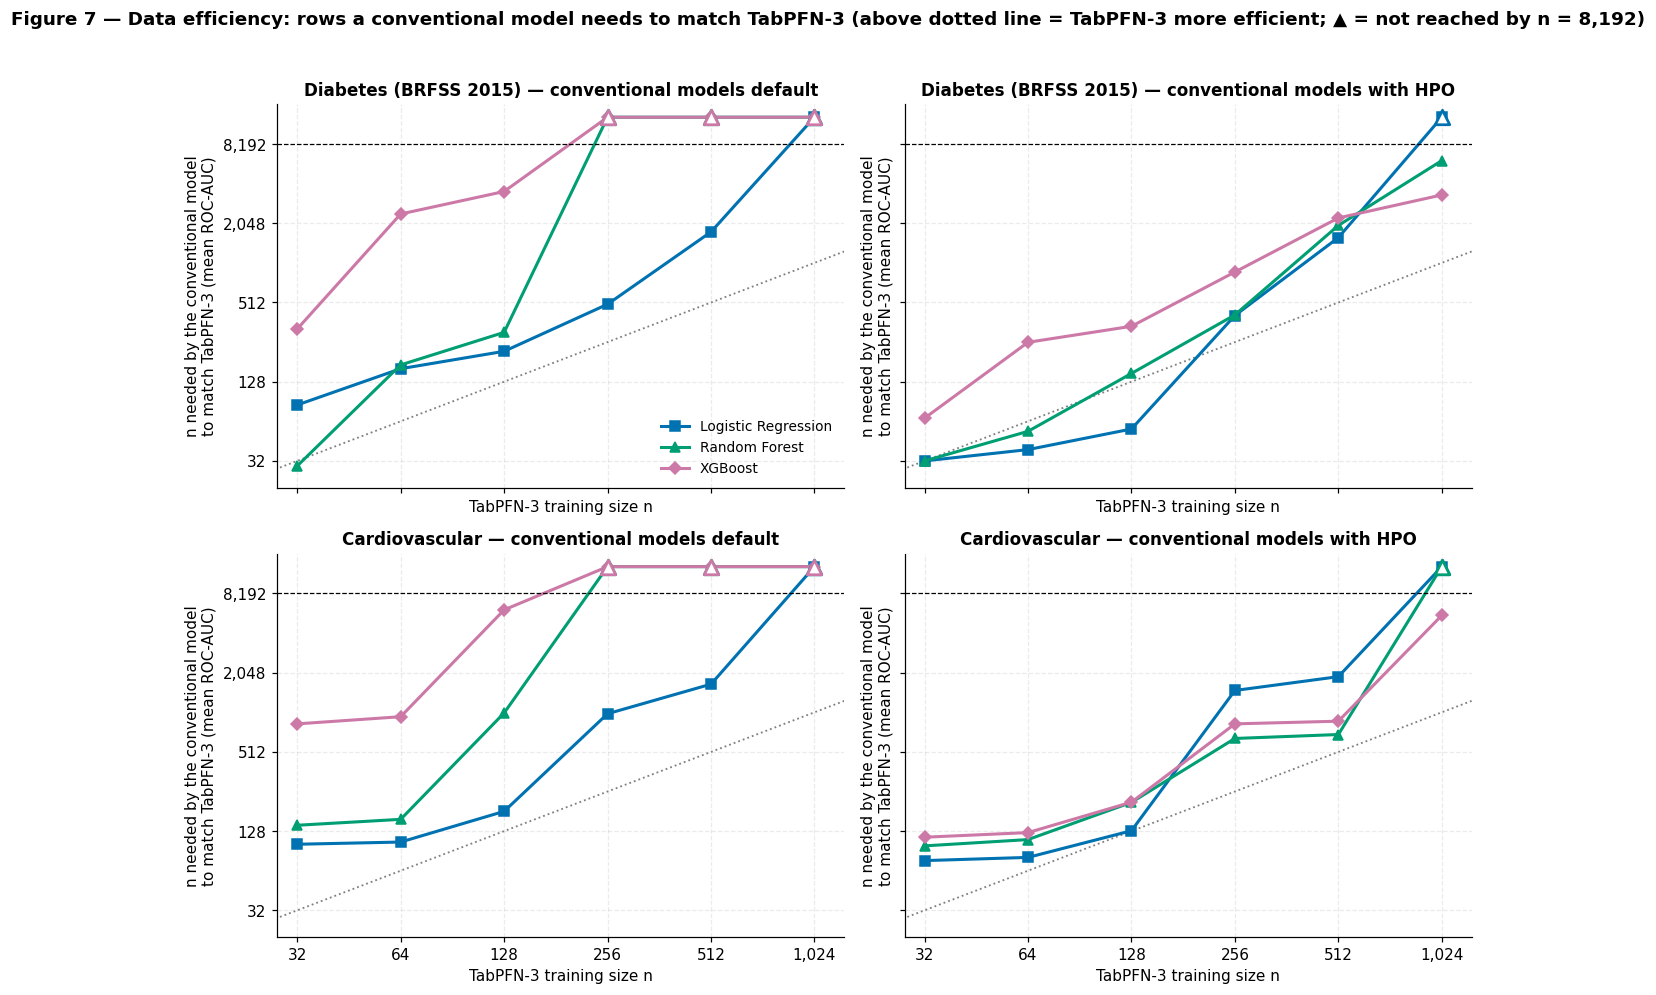

In [12]:
# ============================================================
# Cell 10 — 2.5 Data efficiency: equivalent training size
# ============================================================
def equivalent_n(sizes, values, target):
    """Smallest n at which a model's (monotone-envelope) mean curve reaches `target`, interpolated on log2(n).
    Returns (n_equivalent, status) with status '≤' (already matched at the smallest size), '=' (interpolated) or '>' (never reached)."""
    sizes = np.asarray(sizes, float)
    env = np.maximum.accumulate(np.asarray(values, float))
    if target <= env[0]:
        return sizes[0], "≤"
    reached = env >= target
    if not reached.any():
        return np.inf, ">"
    i = int(np.argmax(reached))
    x0, x1, y0, y1 = np.log2(sizes[i - 1]), np.log2(sizes[i]), env[i - 1], env[i]
    frac = (target - y0) / (y1 - y0) if y1 > y0 else 1.0
    return float(2 ** (x0 + frac * (x1 - x0))), "="


def data_efficiency_table(cond, metric="roc_auc", ref_sizes=(32, 64, 128, 256, 512, 1024)):
    st = cell_stats(PANEL[cond], metric)
    rows = []
    for ds in EXPECTED_DATASETS:
        tp = st[(st.dataset == ds) & (st.model == "tabpfn")].set_index("training_size")["mean"]
        for model in TRADITIONAL_MODELS:
            g = st[(st.dataset == ds) & (st.model == model)].sort_values("training_size")
            for ref in ref_sizes:
                if ref not in tp.index:
                    continue
                n_eq, status = equivalent_n(g.training_size, g["mean"], tp.loc[ref])
                rows.append({"condition": cond, "metric": metric, "dataset": ds, "trad_model": model, "tabpfn_n": ref,
                             "tabpfn_mean": tp.loc[ref], "equivalent_n": n_eq, "status": status,
                             "multiplier": n_eq / ref if np.isfinite(n_eq) else np.inf})
    return pd.DataFrame(rows)


efficiency = pd.concat([data_efficiency_table("default"), data_efficiency_table("hpo")], ignore_index=True)
efficiency.to_csv(TABLES_DIR / "data_efficiency.csv", index=False)

print("Equivalent training size: n at which the conventional model's mean ROC-AUC first reaches TabPFN-3's mean ROC-AUC at n = tabpfn_n")
def _fmt_eq(r):
    if r.status == ">":
        return f">{max(SIZES_ALL):,}"
    return ("≤" if r.status == "≤" else "") + f"{int(round(r.equivalent_n)):,}"


eff_show = efficiency.copy()
eff_show["cell"] = eff_show.apply(_fmt_eq, axis=1)
display(eff_show.pivot(index=["condition", "dataset", "trad_model"], columns="tabpfn_n", values="cell"))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
cap = max(SIZES_ALL) * 1.6
for r, ds in enumerate(EXPECTED_DATASETS):
    for c, cond in enumerate(("default", "hpo")):
        ax = axes[r, c]
        ax.plot([16, cap], [16, cap], color="grey", ls=":", lw=1.2)
        for model in TRADITIONAL_MODELS:
            g = efficiency[(efficiency.dataset == ds) & (efficiency.condition == cond) & (efficiency.trad_model == model)].sort_values("tabpfn_n")
            y = g.equivalent_n.replace(np.inf, cap)
            ax.plot(g.tabpfn_n, y, color=COLORS[model], marker=MARKERS[model], lw=2, ms=6, label=MODEL_LABELS[model])
            cens = g[g.status == ">"]
            ax.scatter(cens.tabpfn_n, [cap] * len(cens), marker="^", s=90, facecolor="white", edgecolor=COLORS[model], lw=1.8, zorder=6)
        ax.axhline(max(SIZES_ALL), color="black", lw=0.8, ls="--")
        ax.set_xscale("log", base=2); ax.set_yscale("log", base=2)
        ax.set_xticks([32, 64, 128, 256, 512, 1024]); ax.set_xticklabels(["32", "64", "128", "256", "512", "1,024"])
        ax.set_yticks([32, 128, 512, 2048, 8192]); ax.set_yticklabels(["32", "128", "512", "2,048", "8,192"])
        ax.xaxis.set_minor_locator(mpl.ticker.NullLocator()); ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
        ax.set_title(f"{DATASET_LABELS[ds]} — conventional models {'default' if cond == 'default' else 'with HPO'}")
        ax.set_xlabel("TabPFN-3 training size n"); ax.set_ylabel("n needed by the conventional model\nto match TabPFN-3 (mean ROC-AUC)")
        ax.set_xlim(28, 1250); ax.set_ylim(20, cap * 1.25)
axes[0, 0].legend(loc="lower right")
fig.suptitle("Figure 7 — Data efficiency: rows a conventional model needs to match TabPFN-3 (above dotted line = TabPFN-3 more efficient; ▲ = not reached by n = 8,192)",
             fontweight="bold", y=1.0)
fig.tight_layout(rect=[0, 0, 1, 0.98])
save_fig(fig, "fig07_data_efficiency")

**Reading Figure 7.** A point on the dotted diagonal means the conventional model needs as many rows as TabPFN-3; a point *k*× above it
means TabPFN-3 achieves the same mean ROC-AUC with *k*× fewer labelled rows. Hollow triangles mark cases where the conventional model
never reaches TabPFN-3's level anywhere in the studied range (censored at 8,192 rows). The equivalence uses a monotone envelope of the
seed-mean curve, so it is descriptive and slightly *favourable* to the conventional model wherever its curve is non-monotone.

#### 2.6 secondary metrics

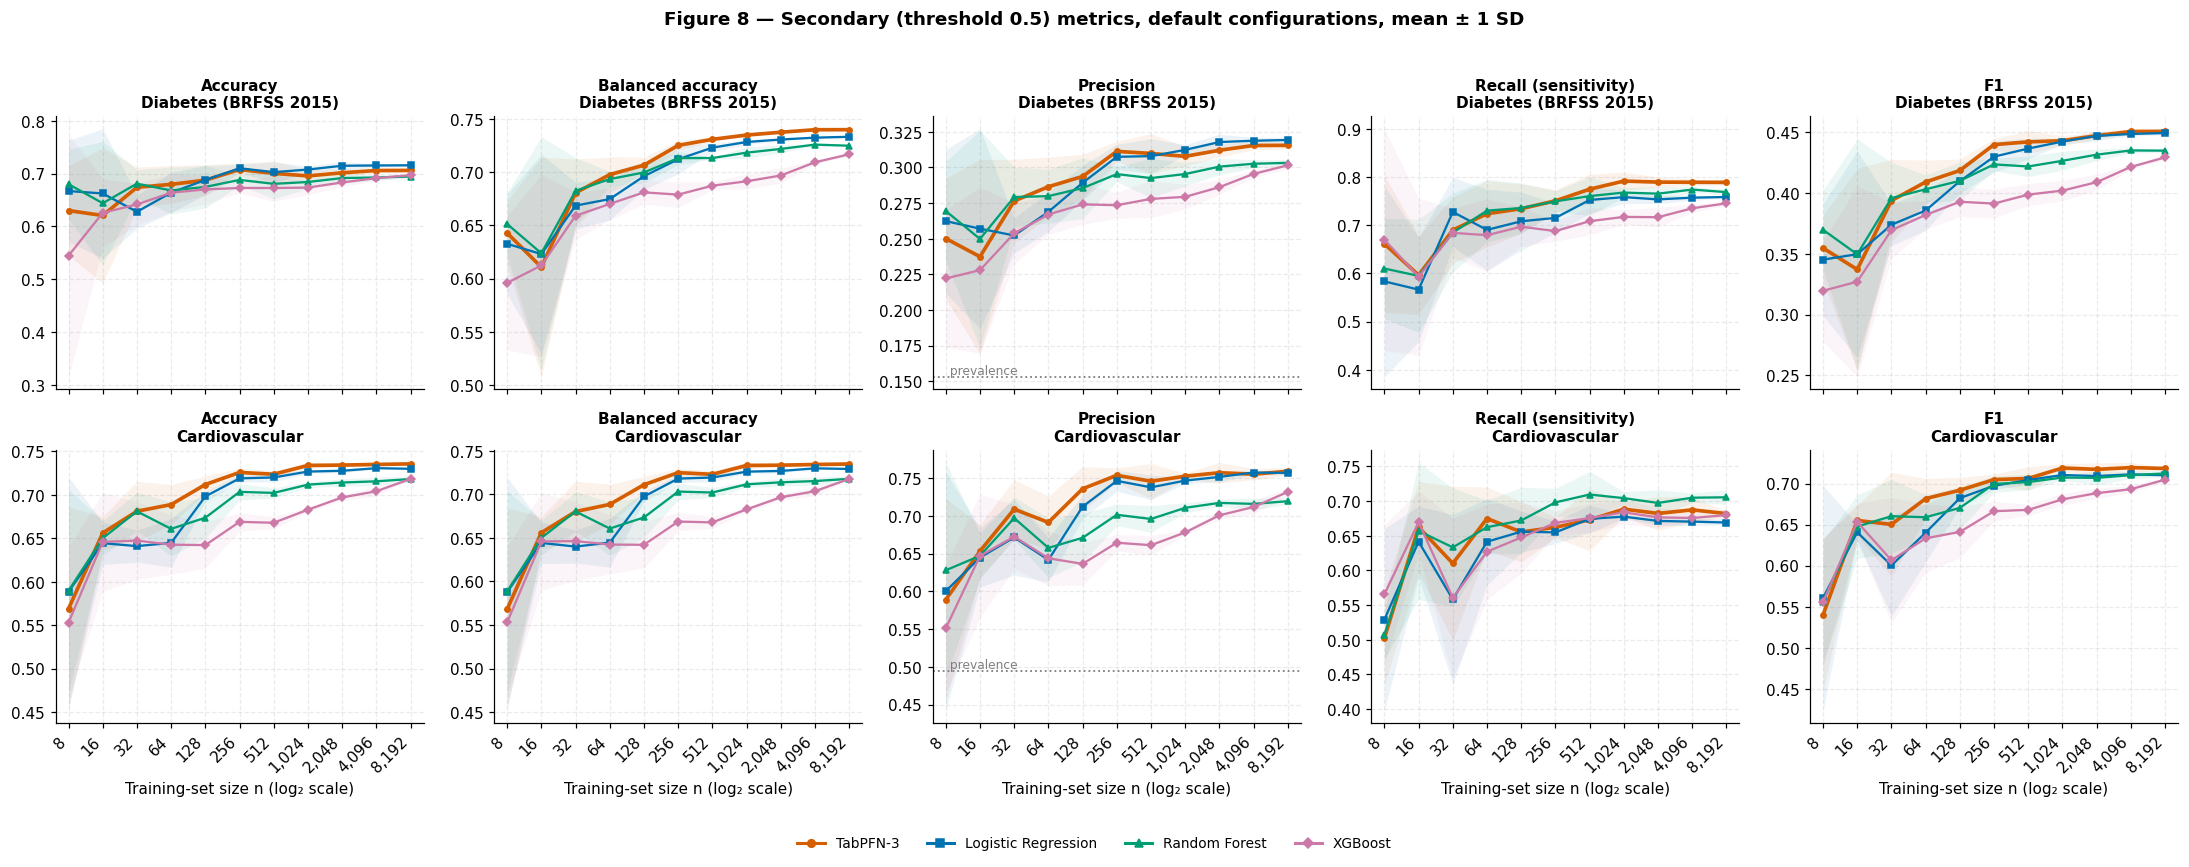

Secondary metrics — mean paired Δ by regime (TabPFN-3 − conventional):


metric                                                  accuracy  balanced_accuracy  precision  recall      f1
dataset        trad_model          regime                                                                     
cardiovascular logistic_regression tiny (8–16)           -0.0040            -0.0040    -0.0014 -0.0029 -0.0032
                                   small (32–128)         0.0326             0.0326     0.0369  0.0283  0.0337
                                   medium (256–1,024)     0.0059             0.0059     0.0071  0.0056  0.0060
                                   large (2,048–8,192)    0.0055             0.0056     0.0019  0.0135  0.0082
               random_forest       tiny (8–16)           -0.0073            -0.0073    -0.0164  0.0004 -0.0044
                                   small (32–128)         0.0221             0.0217     0.0368 -0.0091  0.0114
                                   medium (256–1,024)     0.0220             0.0214     0.0480 -0.0294  0.0071
                                   large (2,048–8,192)    0.0190             0.0186     0.0397 -0.0187  0.0086
               xgboost             tiny (8–16)            0.0131             0.0126     0.0222 -0.0351 -0.0069
                                   small (32–128)         0.0498             0.0497     0.0611  0.0351  0.0476
                                   medium (256–1,024)     0.0545             0.0539     0.0828 -0.0014  0.0383
                                   large (2,048–8,192)    0.0285             0.0282     0.0424  0.0065  0.0230
diabetes       logistic_regression tiny (8–16)           -0.0393            -0.0011    -0.0159  0.0540 -0.0015
                                   small (32–128)         0.0205             0.0151     0.0154  0.0073  0.0174
                                   medium (256–1,024)    -0.0056             0.0091     0.0004  0.0304  0.0054
                                   large (2,048–8,192)   -0.0109             0.0070    -0.0043  0.0327  0.0012
               random_forest       tiny (8–16)           -0.0366            -0.0108    -0.0159  0.0264 -0.0138
                                   small (32–128)         0.0058             0.0030     0.0040 -0.0009  0.0042
                                   medium (256–1,024)     0.0169             0.0154     0.0152  0.0131  0.0177
                                   large (2,048–8,192)    0.0115             0.0149     0.0122  0.0198  0.0157
               xgboost             tiny (8–16)            0.0402             0.0226     0.0187 -0.0027  0.0226
                                   small (32–128)         0.0219             0.0249     0.0206  0.0292  0.0257
                                   medium (256–1,024)     0.0282             0.0444     0.0327  0.0679  0.0443
                                   large (2,048–8,192)    0.0139             0.0315     0.0199  0.0568  0.0296

In [13]:
# ============================================================
# Cell 11 - RQ1 Secondary Metrics at Threshold 0.5
# ============================================================

# Secondary threshold-based metrics included in the figure.
SEC_PLOT = (
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
)


# ------------------------------------------------------------
# Figure 8 - Secondary classification metrics
# ------------------------------------------------------------
# Create one column per metric and one row per dataset.
fig, axes = plt.subplots(
    2,
    len(SEC_PLOT),
    figsize=(4.0 * len(SEC_PLOT), 7.6),
    sharex=True,
)

for c, metric in enumerate(SEC_PLOT):

    # Compute mean and SD across the five subset seeds.
    st = cell_stats(
        PANEL["default"],
        metric,
    )

    for r, ds in enumerate(EXPECTED_DATASETS):
        ax = axes[r, c]

        for model in MODELS4:
            # Select the current dataset and model across training sizes.
            g = (
                st[
                    (st.dataset == ds)
                    & (st.model == model)
                ]
                .sort_values("training_size")
            )

            # Plot mean performance across subset seeds.
            ax.plot(
                g.training_size,
                g["mean"],
                color=COLORS[model],
                marker=MARKERS[model],
                ms=3.5,
                lw=(
                    2.4
                    if model == "tabpfn"
                    else 1.5
                ),
            )

            # Show ±1 SD across the five subset seeds.
            ax.fill_between(
                g.training_size,
                g["mean"] - g["sd"],
                g["mean"] + g["sd"],
                color=COLORS[model],
                alpha=0.08,
                lw=0,
            )

        # Precision has prevalence as the positive-class baseline.
        if metric == "precision":
            ax.axhline(
                PREVALENCE[ds],
                color="grey",
                ls=":",
                lw=1.2,
            )

            ax.text(
                SIZES_ALL[0],
                PREVALENCE[ds],
                " prevalence",
                fontsize=8,
                color="grey",
                va="bottom",
            )

        ax.set_title(
            f"{METRIC_LABELS[metric]}\n"
            f"{DATASET_LABELS[ds]}",
            fontsize=10,
        )

        # Apply the common training-size axis formatting.
        size_axis(
            ax,
            SIZES_ALL,
        )


# Shared legend for all four models.
fig.legend(
    handles=model_handles(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.02),
)

fig.suptitle(
    "Figure 8 — Secondary (threshold 0.5) metrics, "
    "default configurations, mean ± 1 SD",
    fontweight="bold",
    y=1.0,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 0.98]
)

save_fig(
    fig,
    "fig08_rq1_secondary_metrics",
)


# ------------------------------------------------------------
# Secondary-metric paired gap summaries
# ------------------------------------------------------------
# Compute seed-matched TabPFN − conventional gaps for every
# secondary metric and training size.
sec_summary = pd.concat(
    [
        summarize_delta(
            pairs_default[pairs_default.metric == m],
            ["dataset", "trad_model", "training_size"],
        ).assign(metric=m)
        for m in SECONDARY_METRICS
    ],
    ignore_index=True,
)

# Save size-level paired gap summaries.
sec_summary.to_csv(
    TABLES_DIR / "rq1_secondary_gap_summary.csv",
    index=False,
)


# Aggregate secondary-metric gaps by predefined training regime.
sec_regime = pd.concat(
    [
        regime_summary(
            pairs_default,
            m,
        ).assign(metric=m)
        for m in SECONDARY_METRICS
    ],
    ignore_index=True,
)

# Save regime-level secondary-metric summaries.
sec_regime.to_csv(
    TABLES_DIR / "rq1_secondary_regime_summary.csv",
    index=False,
)

print(
    "Secondary metrics — mean paired Δ by regime "
    "(TabPFN-3 − conventional):"
)

# Present one column per secondary metric for compact comparison.
display(
    sec_regime.pivot_table(
        index=["dataset", "trad_model", "regime"],
        columns="metric",
        values="mean_delta",
        observed=True,
    )[list(SECONDARY_METRICS)]
)

#### 2.7 operating-point (threshold 0.5 under balanced training)

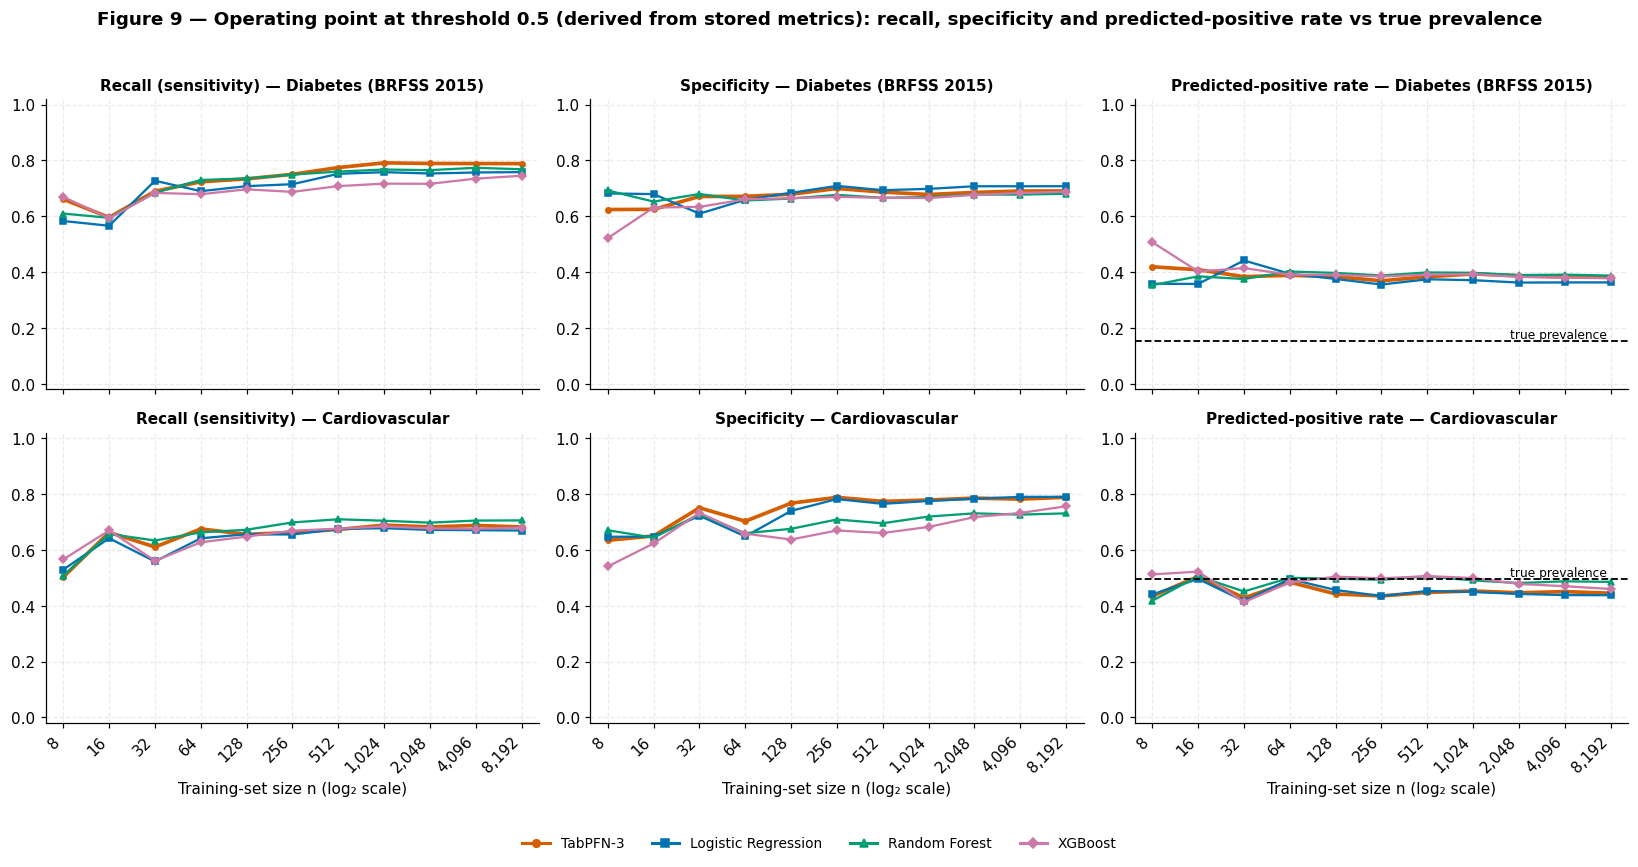

Operating point at n = 8,192 (mean over seeds):


recall  specificity  predicted_positive_rate  precision  true prevalence
dataset        model                                                                                        
cardiovascular Logistic Regression  0.6690       0.7895                   0.4374     0.7568           0.4948
               Random Forest        0.7053       0.7305                   0.4852     0.7194           0.4948
               TabPFN-3             0.6818       0.7880                   0.4444     0.7591           0.4948
               XGBoost              0.6797       0.7559                   0.4596     0.7318           0.4948
diabetes       Logistic Regression  0.7584       0.7079                   0.3634     0.3192           0.1529
               Random Forest        0.7686       0.6810                   0.3878     0.3032           0.1529
               TabPFN-3             0.7888       0.6909                   0.3825     0.3154           0.1529
               XGBoost              0.7453       0.6881                   0.3782     0.3014           0.1529

In [14]:
# ============================================================
# Cell 12 - Operating Point Under Balanced Training
# ============================================================

# Metrics describing the classifier's operating point at the fixed
# classification threshold of 0.5.
OP_METRICS = ("recall", "specificity", "predicted_positive_rate")

fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), sharex=True)

for c, metric in enumerate(OP_METRICS):
    # Compute mean and SD across the five subset seeds for each
    # dataset, model, and training size.
    st = cell_stats(PANEL["default"], metric)

    for r, ds in enumerate(EXPECTED_DATASETS):
        ax = axes[r, c]

        for model in MODELS4:
            g = st[
                (st.dataset == ds) &
                (st.model == model)
            ].sort_values("training_size")

            # Emphasize TabPFN-3 while keeping conventional models visually comparable.
            ax.plot(
                g.training_size,
                g["mean"],
                color=COLORS[model],
                marker=MARKERS[model],
                ms=3.5,
                lw=2.4 if model == "tabpfn" else 1.5,
            )

        # For predicted-positive rate, compare the model output rate
        # with the positive-class prevalence in the fixed test set.
        if metric == "predicted_positive_rate":
            ax.axhline(
                PREVALENCE[ds],
                color="black",
                ls="--",
                lw=1.2,
            )
            ax.text(
                SIZES_ALL[-1],
                PREVALENCE[ds],
                "true prevalence ",
                ha="right",
                va="bottom",
                fontsize=8,
            )

        ax.set_title(
            f"{METRIC_LABELS[metric]} — {DATASET_LABELS[ds]}",
            fontsize=10,
        )
        ax.set_ylim(-0.02, 1.02)
        size_axis(ax, SIZES_ALL)

# Use one shared legend for all six panels.
fig.legend(
    handles=model_handles(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.02),
)

fig.suptitle(
    "Figure 9 — Operating point at threshold 0.5 (derived from stored metrics): "
    "recall, specificity and predicted-positive rate vs true prevalence",
    fontweight="bold",
    y=1.0,
)

fig.tight_layout(rect=[0, 0.04, 1, 0.98])
save_fig(fig, "fig09_operating_point")


# ------------------------------------------------------------
# Operating-point summary at the largest training size
# ------------------------------------------------------------

# Average the threshold-based metrics over subset seeds at the
# largest evaluated training size for each dataset and model.
op_at_max = (
    PANEL["default"][PANEL["default"].training_size == max(SIZES_ALL)]
    .groupby(["dataset", "model"])[
        ["recall", "specificity", "predicted_positive_rate", "precision"]
    ]
    .mean()
    .rename(index=MODEL_LABELS, level="model")
)

# Add the corresponding positive-class prevalence for interpretation
# of predicted-positive rate and precision.
op_at_max["true prevalence"] = [
    PREVALENCE[d] for d, _ in op_at_max.index
]

print(f"Operating point at n = {max(SIZES_ALL):,} (mean over seeds):")
display(op_at_max)

**Why this matters for RQ1.** Precision, F1 and accuracy at a fixed 0.5 threshold depend on the class prevalence, and the training subsets are balanced while the test set keeps its natural prevalence.

*Diabetes (prevalence 15.3 %).* Every model predicts far more positives than there are: averaged over the four models, the predicted-positive rate is about 0.37–0.41 at all sizes (roughly 2.4–2.7 times the prevalence), and from n = 32 specificity is below recall on average. Precision therefore stays at about 0.22–0.32, i.e. roughly 1.5–2 times the prevalence, and accuracy (about 0.63–0.72 for n ≥ 32) lies well below the 0.85 that always predicting the majority class would achieve.

*Cardiovascular (prevalence 49.5 %).* Here the balanced training prior is close to the test prior and there is no over-prediction: the predicted-positive rate is slightly below the prevalence at 10 of 11 sizes (by at most 0.07), with specificity above recall.

These secondary metrics therefore reflect the mismatch between training and test prevalence at least as much as ranking quality, most clearly on diabetes. ROC-AUC and PR-AUC, which are threshold-free, remain the primary evidence, as specified in the exposé; secondary metrics are reported for completeness and should be read with this caveat.

In [15]:
# ============================================================
# Cell 13 - RQ1 Automatically Generated Findings
# ============================================================

# Format a metric difference as percentage points for readable reporting.
def fmt_pts(x):
    return f"{x * 100:+.1f} pts"


def rq1_findings():
    # Start the generated Markdown report; numerical findings are
    # computed directly from the analysis tables.
    lines = ["### RQ1 — computed findings (default configurations)"]

    # Main RQ1 comparison: paired ROC-AUC gaps under default configurations.
    g = gap_default["roc_auc"]

    for ds in EXPECTED_DATASETS:
        lines.append(f"\n**{DATASET_LABELS[ds]}**")

        for model in TRADITIONAL_MODELS:
            t = g[
                (g.dataset == ds) &
                (g.trad_model == model)
            ]

            # Number of training sizes where the mean paired gap is positive,
            # and number where TabPFN-3 wins all subset seeds.
            ahead = int((t["mean"] > 0).sum())
            unanimous = int((t["wins"] == N_SEEDS).sum())

            # Training size with the largest mean paired ROC-AUC gap.
            imax = t.loc[t["mean"].idxmax()]

            lines.append(
                f"- vs **{MODEL_LABELS[model]}**: "
                f"mean ROC-AUC Δ over sizes {fmt_pts(t['mean'].mean())}; "
                f"TabPFN-3 ahead on the seed-mean in "
                f"{ahead}/{len(t)} sizes and ahead in all {N_SEEDS} seeds in "
                f"{unanimous}/{len(t)} sizes; "
                f"largest gap {fmt_pts(imax['mean'])} at "
                f"n = {int(imax['training_size']):,}."
            )

        # Add regime-level summaries for this dataset.
        reg = rq1_regime["roc_auc"]
        reg = reg[reg.dataset == ds]

        for name in REGIME_ORDER:
            r = reg[reg.regime == name]

            if r.empty:
                continue

            # Build these strings separately to avoid nested f-string syntax.
            win_rates = ", ".join(
                f"{MODEL_LABELS[m]} "
                f"{r[r.trad_model == m].seed_win_rate.iat[0]:.0%}"
                for m in TRADITIONAL_MODELS
            )

            mean_deltas = ", ".join(
                f"{MODEL_LABELS[m]} "
                f"{fmt_pts(r[r.trad_model == m].mean_delta.iat[0])}"
                for m in TRADITIONAL_MODELS
            )

            lines.append(
                f"  - regime {name}: "
                f"seed-win rate {win_rates}; "
                f"mean Δ {mean_deltas}."
            )

    # Data-efficiency results for TabPFN-3 trained on 128 examples.
    eff = efficiency[
        (efficiency.condition == "default") &
        (efficiency.tabpfn_n == 128)
    ]

    lines.append(
        "\n**Data efficiency (default configs), TabPFN-3 at n = 128:**"
    )

    for ds in EXPECTED_DATASETS:
        parts = []

        for model in TRADITIONAL_MODELS:
            r = eff[
                (eff.dataset == ds) &
                (eff.trad_model == model)
            ].iloc[0]

            # Report the estimated equivalent training size, or the upper
            # bound when the required size exceeds the evaluated range.
            if r.status == ">":
                required_n = f"> {max(SIZES_ALL):,}"
            else:
                required_n = f"≈ {int(round(r.equivalent_n)):,}"

            parts.append(
                f"{MODEL_LABELS[model]} needs {required_n} rows"
            )

        lines.append(
            f"- {DATASET_LABELS[ds]}: " +
            "; ".join(parts) +
            "."
        )

    # Count individual default/TabPFN runs with ROC-AUC below 0.5.
    n_sub = int(
        (
            seed_results[
                seed_results.condition.isin(["tabpfn", "default"])
            ].roc_auc < 0.5
        ).sum()
    )

    lines.append(
        f"\n**Sub-chance runs:** {n_sub} of {len(PANEL['default'])} "
        f"default/TabPFN runs have ROC-AUC < 0.5; "
        f"{len(adversarial)} subset(s) are below 0.55 on the model-average "
        f"(Figure 1) — indicating difficult data draws across the evaluated models."
    )

    return "\n".join(lines)


# Generate the findings from the current analysis objects and render them as Markdown.
rq1_text = rq1_findings()
display(Markdown(rq1_text))

### RQ1 — computed findings (default configurations)

**Diabetes (BRFSS 2015)**
- vs **Logistic Regression**: mean ROC-AUC Δ over sizes +0.9 pts; TabPFN-3 ahead on the seed-mean in 9/11 sizes and ahead in all 5 seeds in 7/11 sizes; largest gap +3.9 pts at n = 64.
- vs **Random Forest**: mean ROC-AUC Δ over sizes +1.2 pts; TabPFN-3 ahead on the seed-mean in 8/11 sizes and ahead in all 5 seeds in 6/11 sizes; largest gap +2.5 pts at n = 512.
- vs **XGBoost**: mean ROC-AUC Δ over sizes +4.4 pts; TabPFN-3 ahead on the seed-mean in 11/11 sizes and ahead in all 5 seeds in 10/11 sizes; largest gap +10.1 pts at n = 8.
  - regime tiny (8–16): seed-win rate Logistic Regression 40%, Random Forest 30%, XGBoost 80%; mean Δ Logistic Regression -0.9 pts, Random Forest -0.9 pts, XGBoost +5.5 pts.
  - regime small (32–128): seed-win rate Logistic Regression 80%, Random Forest 67%, XGBoost 100%; mean Δ Logistic Regression +2.2 pts, Random Forest +0.7 pts, XGBoost +3.4 pts.
  - regime medium (256–1,024): seed-win rate Logistic Regression 100%, Random Forest 100%, XGBoost 100%; mean Δ Logistic Regression +1.0 pts, Random Forest +2.2 pts, XGBoost +5.4 pts.
  - regime large (2,048–8,192): seed-win rate Logistic Regression 100%, Random Forest 100%, XGBoost 100%; mean Δ Logistic Regression +0.7 pts, Random Forest +2.1 pts, XGBoost +3.7 pts.

**Cardiovascular**
- vs **Logistic Regression**: mean ROC-AUC Δ over sizes +1.5 pts; TabPFN-3 ahead on the seed-mean in 10/11 sizes and ahead in all 5 seeds in 8/11 sizes; largest gap +5.5 pts at n = 64.
- vs **Random Forest**: mean ROC-AUC Δ over sizes +2.2 pts; TabPFN-3 ahead on the seed-mean in 10/11 sizes and ahead in all 5 seeds in 9/11 sizes; largest gap +4.5 pts at n = 128.
- vs **XGBoost**: mean ROC-AUC Δ over sizes +5.0 pts; TabPFN-3 ahead on the seed-mean in 11/11 sizes and ahead in all 5 seeds in 9/11 sizes; largest gap +8.5 pts at n = 128.
  - regime tiny (8–16): seed-win rate Logistic Regression 50%, Random Forest 70%, XGBoost 70%; mean Δ Logistic Regression -0.1 pts, Random Forest -0.9 pts, XGBoost +3.1 pts.
  - regime small (32–128): seed-win rate Logistic Regression 93%, Random Forest 80%, XGBoost 100%; mean Δ Logistic Regression +3.8 pts, Random Forest +2.7 pts, XGBoost +6.3 pts.
  - regime medium (256–1,024): seed-win rate Logistic Regression 100%, Random Forest 100%, XGBoost 100%; mean Δ Logistic Regression +0.8 pts, Random Forest +3.0 pts, XGBoost +6.3 pts.
  - regime large (2,048–8,192): seed-win rate Logistic Regression 100%, Random Forest 100%, XGBoost 100%; mean Δ Logistic Regression +0.9 pts, Random Forest +2.7 pts, XGBoost +3.7 pts.

**Data efficiency (default configs), TabPFN-3 at n = 128:**
- Diabetes (BRFSS 2015): Logistic Regression needs ≈ 218 rows; Random Forest needs ≈ 303 rows; XGBoost needs ≈ 3,571 rows.
- Cardiovascular: Logistic Regression needs ≈ 181 rows; Random Forest needs ≈ 1,012 rows; XGBoost needs ≈ 6,150 rows.

**Sub-chance runs:** 8 of 440 default/TabPFN runs have ROC-AUC < 0.5; 2 subset(s) are below 0.55 on the model-average (Figure 1) — indicating difficult data draws across the evaluated models.

## 3 · RQ2 — Does hyper-parameter optimisation narrow or reverse the gap?

HPO (RandomizedSearchCV, 20 configurations, stratified 5-fold CV, ROC-AUC criterion) was run for the conventional models at
`n ≥ 32`; TabPFN-3 is carried forward **unchanged** as the comparator. RQ2 is therefore evaluated on the nine common sizes `32–8,192`.

### 3.1 Why the *signed* gap
For every seed, with the same TabPFN-3 run on both sides,

> (TabPFN − default) − (TabPFN − HPO) = **HPO − default**.

The change in TabPFN's signed advantage caused by HPO is *exactly* the within-model HPO gain — so a separate "gap narrowed" statistic
adds no information beyond the HPO effect, and an **absolute**-gap version can even mislabel a reversal as "narrowing" (the gap
shrinks in magnitude while the sign flips). This notebook therefore reports (i) the direct HPO effect, (ii) the signed advantage before/after
HPO, and (iii) a four-way outcome classification that keeps the sign.

In [16]:
# ============================================================
# Cell 14 - Direct HPO Effect and Algebraic Identity Check
# ============================================================

# Restrict the default results to the training sizes where HPO was performed.
default_common = seed_results[
    (seed_results.condition == "default") &
    seed_results.training_size.isin(SIZES_HPO)
]

# HPO results already contain only the HPO training sizes.
hpo_only = seed_results[seed_results.condition == "hpo"]

# Match default and HPO runs by dataset, training size, subset seed,
# and model. Each combination should occur exactly once in both tables.
direct = default_common.merge(
    hpo_only,
    on=PAIR_KEYS + ["model"],
    suffixes=("_def", "_hpo"),
    validate="one_to_one",
)
assert len(direct) == expected_hpo_runs()


# ------------------------------------------------------------
# Direct HPO effect per seed and metric
# ------------------------------------------------------------

# Construct a long-form table containing the direct HPO gain:
# HPO performance − default performance.
direct_long = pd.concat(
    [
        pd.DataFrame({
            **{k: direct[k] for k in PAIR_KEYS},
            "trad_model": direct["model"],
            "metric": m,
            "delta": direct[f"{m}_hpo"] - direct[f"{m}_def"],
        })
        for m in PAIR_METRICS
    ],
    ignore_index=True,
)


# ------------------------------------------------------------
# Algebraic identity check
# ------------------------------------------------------------

# For matched seed-level comparisons:
# (TabPFN − default) − (TabPFN − HPO) = HPO − default
#
# This verifies that the direct HPO effect is exactly consistent with
# the two paired-gap tables used elsewhere in the analysis.
chk = (
    pairs_default[pairs_default.training_size.isin(SIZES_HPO)]
    .merge(
        pairs_hpo,
        on=PAIR_KEYS + ["trad_model", "metric"],
        suffixes=("_def", "_hpo"),
    )
    .merge(
        direct_long,
        on=PAIR_KEYS + ["trad_model", "metric"],
    )
)

assert len(chk) == len(direct_long)

# Use a tight numerical tolerance because both sides are derived
# directly from the same stored metric values.
assert np.allclose(
    chk["delta_def"] - chk["delta_hpo"],
    chk["delta"],
    atol=1e-12,
)

print(
    "✓ Identity verified on all seed-level pairs: "
    "(TabPFN − default) − (TabPFN − HPO) = HPO − default."
)


# ------------------------------------------------------------
# Summarize and export HPO effects
# ------------------------------------------------------------

# Aggregate the direct HPO effect over the five matched subset seeds,
# including mean, SD, confidence interval, and seed-level win counts.
hpo_effect = {
    m: summarize_delta(
        direct_long[direct_long.metric == m],
        ["dataset", "trad_model", "training_size"],
    )
    for m in PAIR_METRICS
}

# Save summaries for all primary and secondary metrics.
for m in ALL_METRICS:
    hpo_effect[m].to_csv(
        TABLES_DIR / f"rq2_hpo_effect_{m}.csv",
        index=False,
    )


# ------------------------------------------------------------
# Display ROC-AUC HPO effect
# ------------------------------------------------------------

print(
    "\nDirect HPO effect on ROC-AUC "
    "(HPO − default), mean [95 % CI], seeds improved (k/5):"
)

tab = hpo_effect["roc_auc"].copy()

# Express the mean HPO gain and its 95 % CI in percentage-point units.
tab["HPO gain [95% CI]"] = tab.apply(
    lambda r: (
        f"{r['mean'] * 100:+.2f} "
        f"[{r.ci_lo * 100:+.2f}, {r.ci_hi * 100:+.2f}]"
    ),
    axis=1,
)

# Number of subset seeds where HPO improved ROC-AUC over default.
tab["improved"] = (
    tab["wins"].astype(int).astype(str) +
    f"/{N_SEEDS}"
)

# Present one row per dataset/model and one column per HPO training size.
display(
    tab.pivot(
        index=["dataset", "trad_model"],
        columns="training_size",
        values="HPO gain [95% CI]",
    )
)

✓ Identity verified on all seed-level pairs: (TabPFN − default) − (TabPFN − HPO) = HPO − default.

Direct HPO effect on ROC-AUC (HPO − default), mean [95 % CI], seeds improved (k/5):


training_size                                       32                    64                    128                   256                   512                   1024                  2048                  4096  \
dataset        trad_model                                                                                                                                                                                            
cardiovascular logistic_regression  +3.56 [-0.74, +7.86]  +2.99 [-0.04, +6.02]  +1.18 [+0.19, +2.16]  +0.09 [-0.38, +0.57]  +0.27 [-0.15, +0.70]  -0.15 [-0.43, +0.13]  +0.00 [-0.00, +0.01]  +0.00 [-0.00, +0.00]   
               random_forest        -1.06 [-4.77, +2.65]  +1.25 [-0.45, +2.95]  +2.03 [+0.64, +3.42]  +2.21 [+1.24, +3.17]  +2.78 [+1.96, +3.60]  +2.37 [+2.03, +2.71]  +2.36 [+1.78, +2.95]  +2.52 [+2.22, +2.82]   
               xgboost              +2.38 [-0.97, +5.74]  +1.73 [-0.48, +3.95]  +5.64 [+4.33, +6.95]  +5.79 [+4.94, +6.65]  +5.47 [+4.06, +6.88]  +4.94 [+4.46, +5.42]  +4.24 [+3.30, +5.18]  +3.51 [+2.88, +4.14]   
diabetes       logistic_regression  +3.56 [-0.51, +7.63]  +4.90 [+0.95, +8.84]  +1.44 [+0.78, +2.10]  +0.65 [-0.36, +1.65]  +0.31 [+0.06, +0.57]  +0.08 [-0.10, +0.25]  +0.03 [-0.02, +0.08]  +0.01 [-0.01, +0.02]   
               random_forest        +0.58 [-0.52, +1.67]  +1.75 [+0.99, +2.51]  +0.16 [-1.74, +2.05]  +1.15 [+0.52, +1.78]  +1.78 [+1.37, +2.19]  +1.38 [+1.08, +1.69]  +1.48 [+1.28, +1.68]  +1.38 [+1.13, +1.64]   
               xgboost              +0.88 [-1.25, +3.02]  +1.43 [-1.42, +4.28]  +1.65 [+1.05, +2.25]  +3.05 [+1.40, +4.71]  +3.58 [+2.69, +4.47]  +3.98 [+3.25, +4.71]  +3.80 [+3.37, +4.23]  +3.26 [+3.13, +3.39]   

training_size                                       8192  
dataset        trad_model                                 
cardiovascular logistic_regression  +0.00 [-0.00, +0.00]  
               random_forest        +2.32 [+1.94, +2.71]  
               xgboost              +2.43 [+2.20, +2.66]  
diabetes       logistic_regression  -0.00 [-0.01, +0.00]  
               random_forest        +1.60 [+1.48, +1.73]  
               xgboost              +2.77 [+2.63, +2.92]

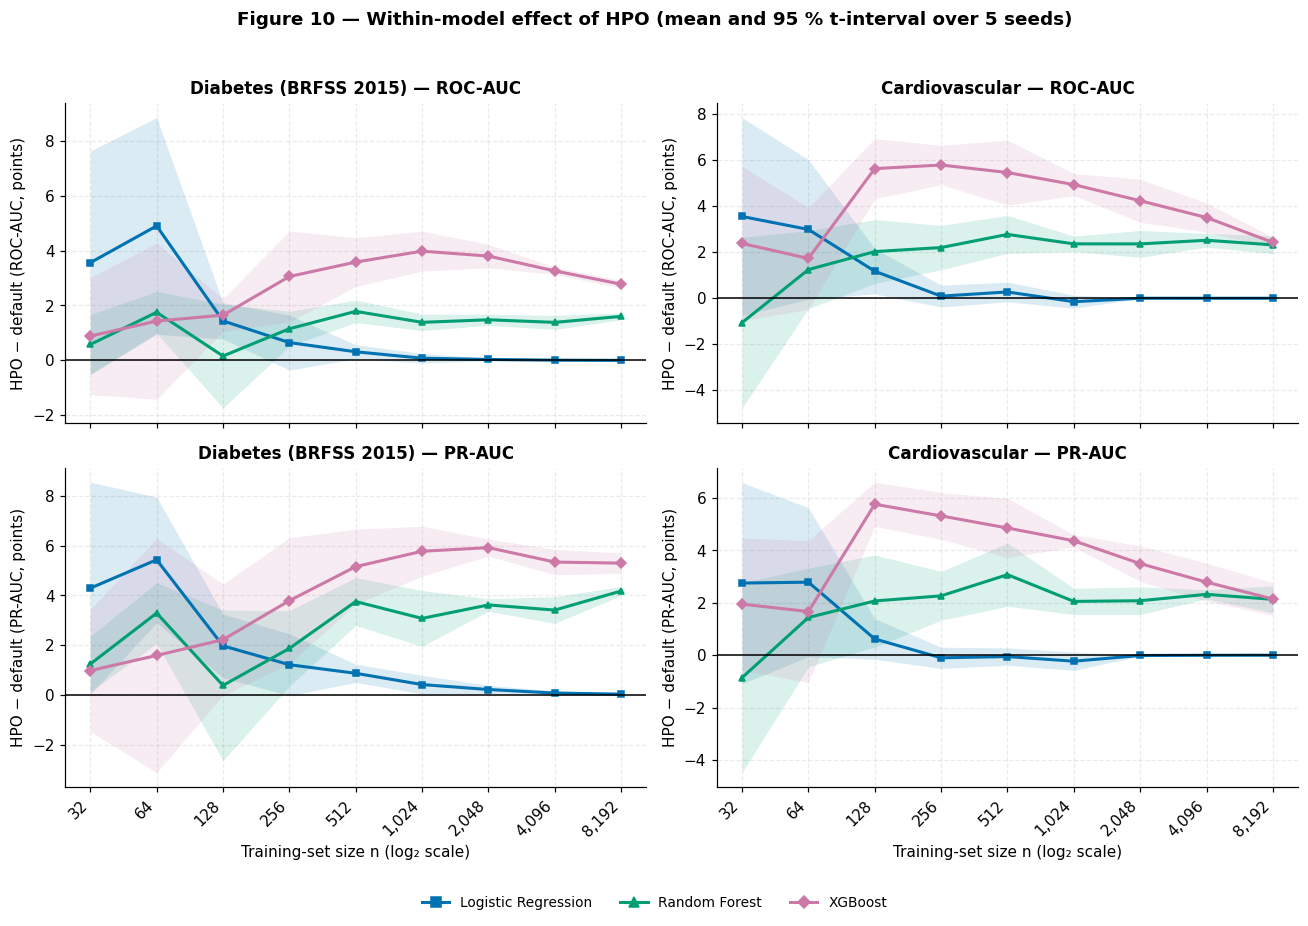

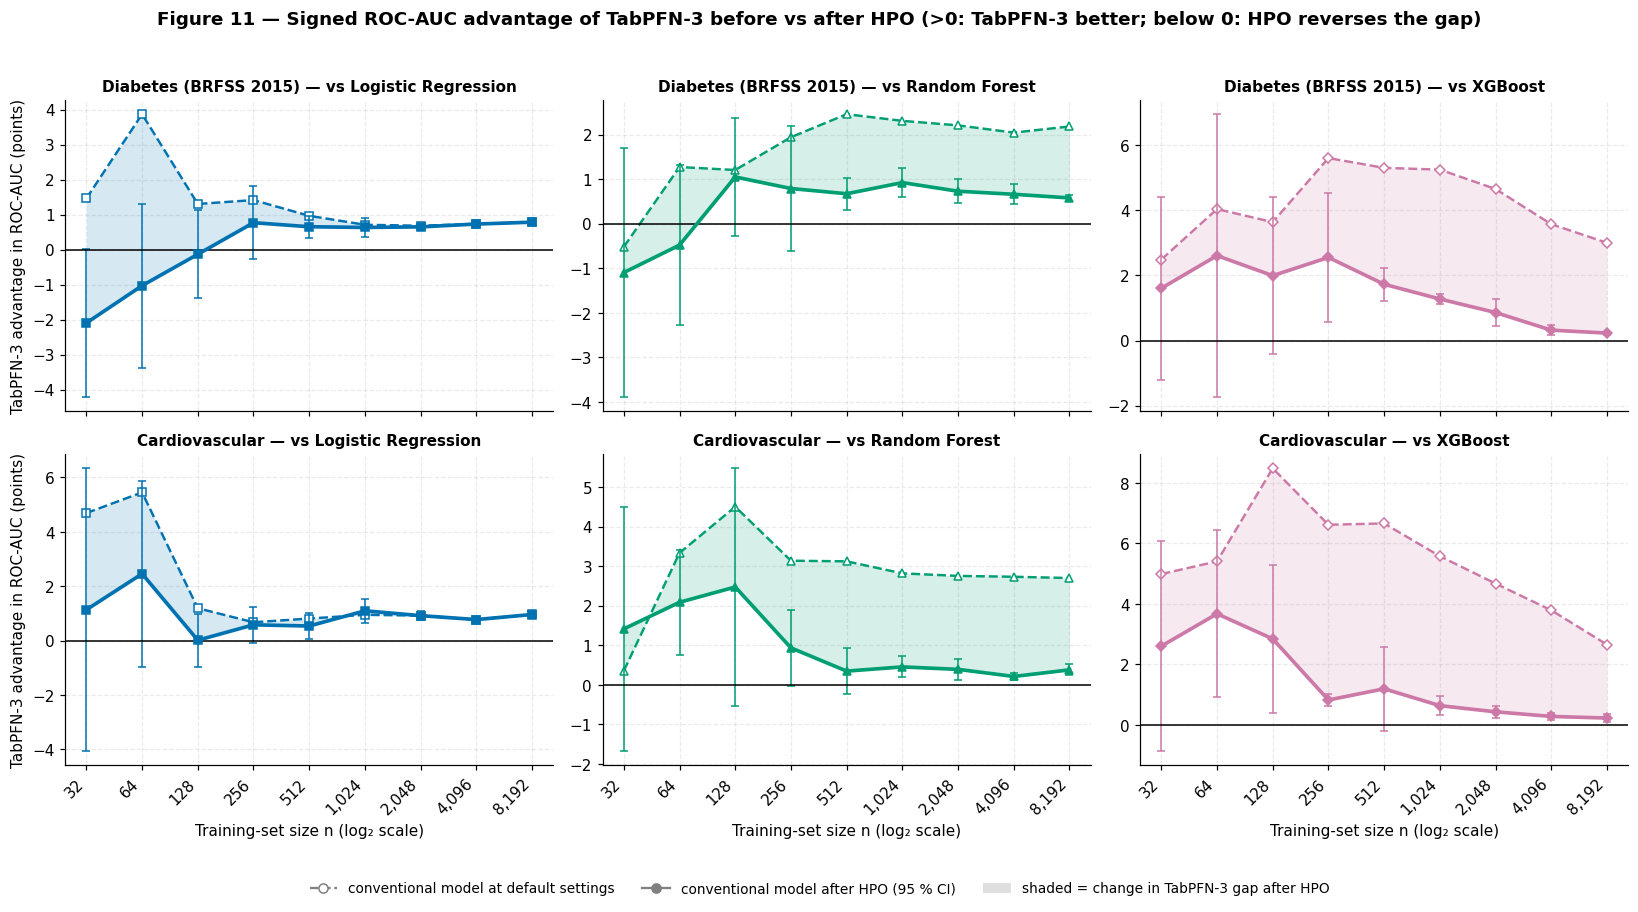

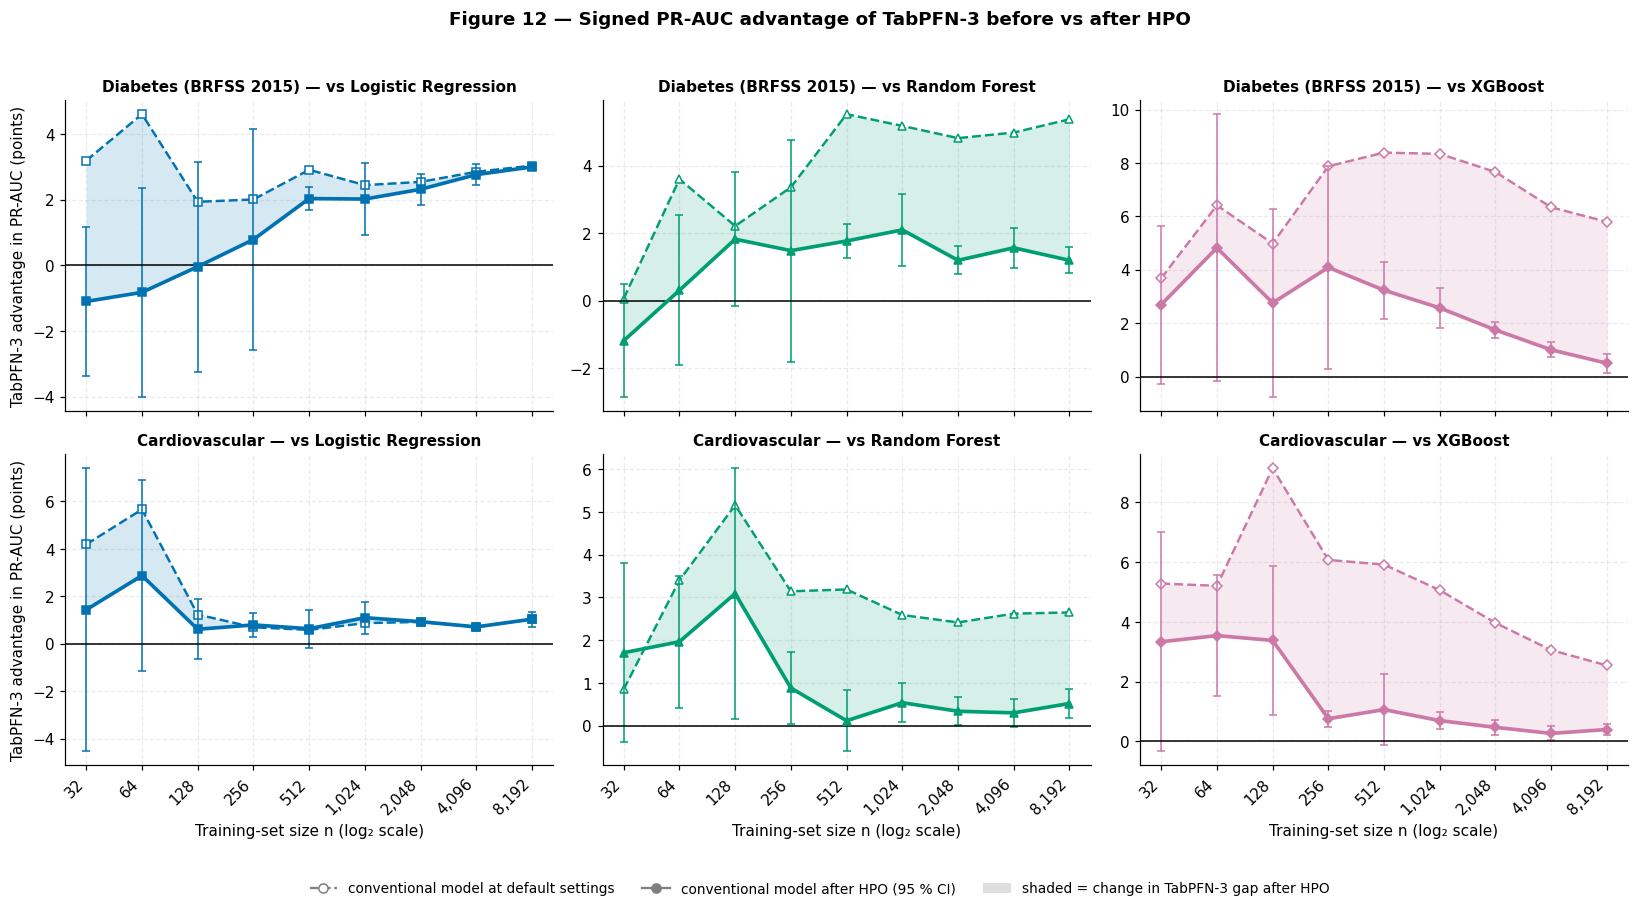

In [17]:
# ============================================================
# Cell 15 - RQ2 HPO Effect and TabPFN-3 Advantage Before vs. After HPO
# ============================================================

# ------------------------------------------------------------
# Figure 10 — Direct effect of HPO
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), sharex=True)

for r, metric in enumerate(PRIMARY_METRICS):
    for c, ds in enumerate(EXPECTED_DATASETS):
        ax = axes[r, c]

        for model in TRADITIONAL_MODELS:
            # Select the direct HPO effect for this dataset/model.
            g = hpo_effect[metric]
            g = g[
                (g.dataset == ds) &
                (g.trad_model == model)
            ].sort_values("training_size")

            # Plot mean HPO gain with its 95% t-based confidence interval.
            ax.plot(
                g.training_size,
                g["mean"] * 100,
                color=COLORS[model],
                marker=MARKERS[model],
                ms=4.5,
                lw=2,
            )
            ax.fill_between(
                g.training_size,
                g.ci_lo * 100,
                g.ci_hi * 100,
                color=COLORS[model],
                alpha=0.14,
                lw=0,
            )

        # Zero indicates no difference between HPO and default settings.
        ax.axhline(0, color="black", lw=1)

        ax.set_title(
            f"{DATASET_LABELS[ds]} — {METRIC_LABELS[metric]}"
        )
        ax.set_ylabel(
            f"HPO − default ({METRIC_LABELS[metric]}, points)"
        )
        size_axis(ax, SIZES_HPO)


# Legend contains only the conventional models because TabPFN-3
# is not directly tuned in this HPO comparison.
handles = [
    Line2D(
        [0],
        [0],
        color=COLORS[m],
        marker=MARKERS[m],
        lw=2,
        label=MODEL_LABELS[m],
    )
    for m in TRADITIONAL_MODELS
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.01),
)

fig.suptitle(
    "Figure 10 — Within-model effect of HPO "
    "(mean and 95 % t-interval over 5 seeds)",
    fontweight="bold",
    y=1.0,
)

fig.tight_layout(rect=[0, 0.04, 1, 0.98])
save_fig(fig, "fig10_rq2_hpo_effect")


# ------------------------------------------------------------
# Figures 11–12 — Signed TabPFN-3 advantage before vs. after HPO
# ------------------------------------------------------------

def fig_rq2_signed_gap(metric, stem, title):
    # Compute TabPFN-3 − conventional gaps under default settings
    # and after HPO at the common HPO training sizes.
    adv_d = summarize_delta(
        pairs_default[
            (pairs_default.metric == metric) &
            pairs_default.training_size.isin(SIZES_HPO)
        ],
        ["dataset", "trad_model", "training_size"],
    )

    adv_h = summarize_delta(
        pairs_hpo[pairs_hpo.metric == metric],
        ["dataset", "trad_model", "training_size"],
    )

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(15, 8),
        sharex=True,
    )

    for r, ds in enumerate(EXPECTED_DATASETS):
        for c, model in enumerate(TRADITIONAL_MODELS):
            ax = axes[r, c]

            d = adv_d[
                (adv_d.dataset == ds) &
                (adv_d.trad_model == model)
            ].sort_values("training_size")

            h = adv_h[
                (adv_h.dataset == ds) &
                (adv_h.trad_model == model)
            ].sort_values("training_size")

            # Shade the vertical difference between the default and
            # HPO gaps, representing the portion of the gap changed by HPO.
            ax.fill_between(
                d.training_size,
                d["mean"] * 100,
                h["mean"] * 100,
                color=COLORS[model],
                alpha=0.16,
                lw=0,
            )

            # Dashed line: TabPFN-3 gap against the conventional model
            # at its default configuration.
            ax.plot(
                d.training_size,
                d["mean"] * 100,
                color=COLORS[model],
                ls="--",
                marker=MARKERS[model],
                mfc="white",
                lw=1.6,
                ms=5,
            )

            # Solid/error-bar line: TabPFN-3 gap after conventional-model HPO.
            ax.errorbar(
                h.training_size,
                h["mean"] * 100,
                yerr=[
                    (h["mean"] - h.ci_lo) * 100,
                    (h.ci_hi - h["mean"]) * 100,
                ],
                color=COLORS[model],
                marker=MARKERS[model],
                lw=2.4,
                ms=5,
                capsize=2.5,
                elinewidth=1,
            )

            # Zero separates positive TabPFN-3 gaps from negative gaps.
            ax.axhline(0, color="black", lw=1)

            ax.set_title(
                f"{DATASET_LABELS[ds]} — vs {MODEL_LABELS[model]}",
                fontsize=10,
            )

            if c == 0:
                ax.set_ylabel(
                    f"TabPFN-3 advantage in "
                    f"{METRIC_LABELS[metric]} (points)"
                )

            size_axis(ax, SIZES_HPO)

    # Explain the two lines and the shaded change without implying
    # that either configuration is universally preferable.
    legend = [
        Line2D(
            [0],
            [0],
            color="grey",
            ls="--",
            marker="o",
            mfc="white",
            label="conventional model at default settings",
        ),
        Line2D(
            [0],
            [0],
            color="grey",
            marker="o",
            label="conventional model after HPO (95 % CI)",
        ),
        Patch(
            facecolor="grey",
            alpha=0.25,
            label="shaded = change in TabPFN-3 gap after HPO",
        ),
    ]

    fig.legend(
        handles=legend,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, -0.02),
    )

    fig.suptitle(
        title,
        fontweight="bold",
        y=1.0,
    )

    fig.tight_layout(rect=[0, 0.04, 1, 0.98])
    save_fig(fig, stem)


# Generate signed-gap figures for both primary metrics.
fig_rq2_signed_gap(
    "roc_auc",
    "fig11_rq2_signed_gap_roc",
    "Figure 11 — Signed ROC-AUC advantage of TabPFN-3 before vs after HPO "
    "(>0: TabPFN-3 better; below 0: HPO reverses the gap)",
)

fig_rq2_signed_gap(
    "pr_auc",
    "fig12_rq2_signed_gap_pr",
    "Figure 12 — Signed PR-AUC advantage of TabPFN-3 before vs after HPO",
)

Outcome classification counts (dataset × size × model cells, on seed-mean ROC-AUC):


outcome                             Conventional ahead before and after HPO  Gap reversed by HPO (conventional now ahead)  TabPFN-3 ahead before and after HPO
dataset        trad_model                                                                                                                                     
cardiovascular logistic_regression                                        0                                             0                                    9
               random_forest                                              0                                             0                                    9
               xgboost                                                    0                                             0                                    9
diabetes       logistic_regression                                        0                                             3                                    6
               random_forest                                              1                                             1                                    7
               xgboost                                                    0                                             0                                    9


Gap closure by regime (advantages and HPO gain in ROC-AUC units; share closed = median HPO gain / default advantage):


,dataset,trad_model,regime,mean_default_advantage,mean_hpo_advantage,mean_hpo_gain,median_share_closed
2,cardiovascular,logistic_regression,small (32–128),0.0378,0.0120,0.0258,0.7583
1,cardiovascular,logistic_regression,"medium (256–1,024)",0.0081,0.0074,0.0007,0.1389
0,cardiovascular,logistic_regression,"large (2,048–8,192)",0.0088,0.0088,0.0000,0.0009
5,cardiovascular,random_forest,small (32–128),0.0273,0.0199,0.0074,0.4124
4,cardiovascular,random_forest,"medium (256–1,024)",0.0303,0.0058,0.0245,0.8397
3,cardiovascular,random_forest,"large (2,048–8,192)",0.0273,0.0033,0.0240,0.8605
8,cardiovascular,xgboost,small (32–128),0.0629,0.0304,0.0325,0.4784
7,cardiovascular,xgboost,"medium (256–1,024)",0.0628,0.0088,0.0540,0.8759
6,cardiovascular,xgboost,"large (2,048–8,192)",0.0370,0.0031,0.0339,0.9158
11,diabetes,logistic_regression,small (32–128),0.0221,-0.0108,0.0330,1.2654


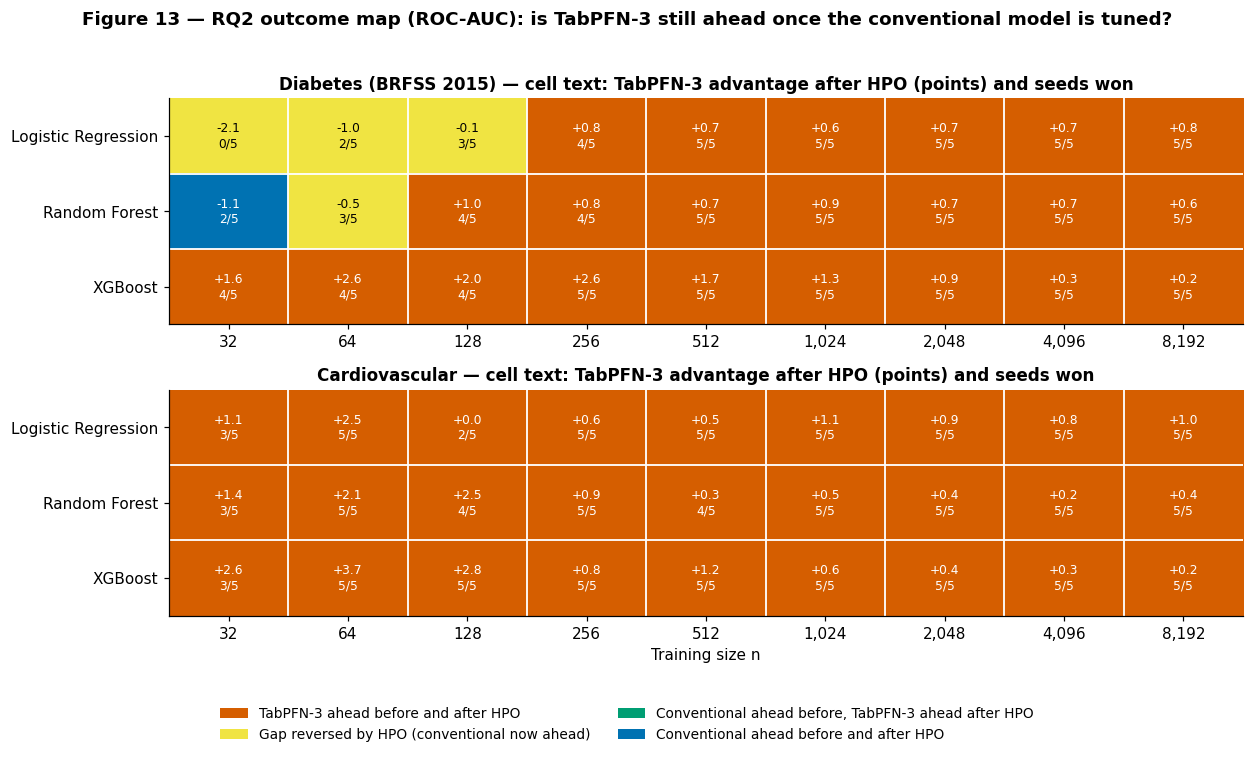

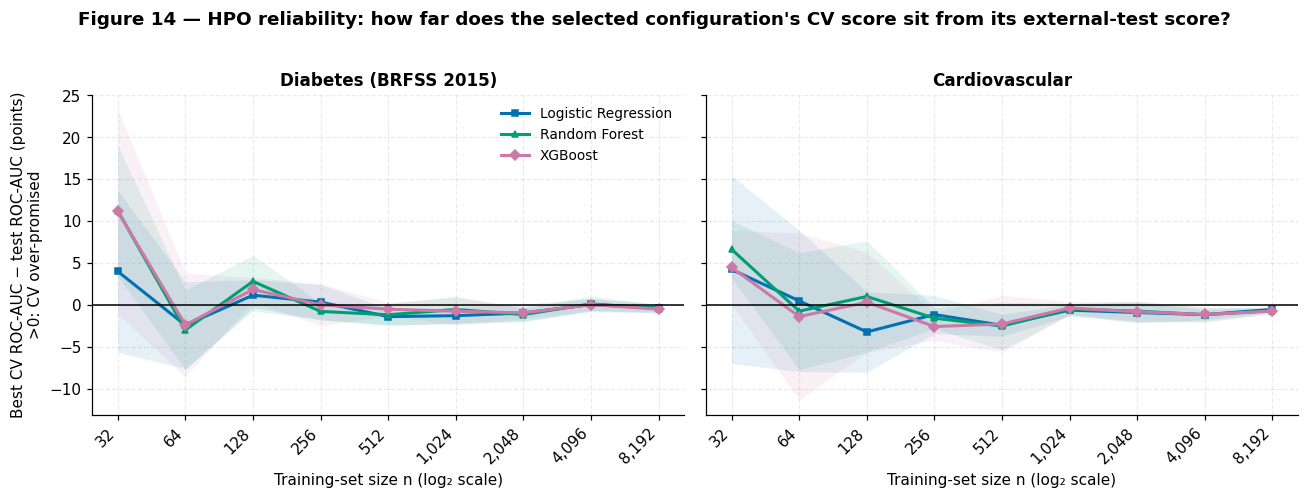

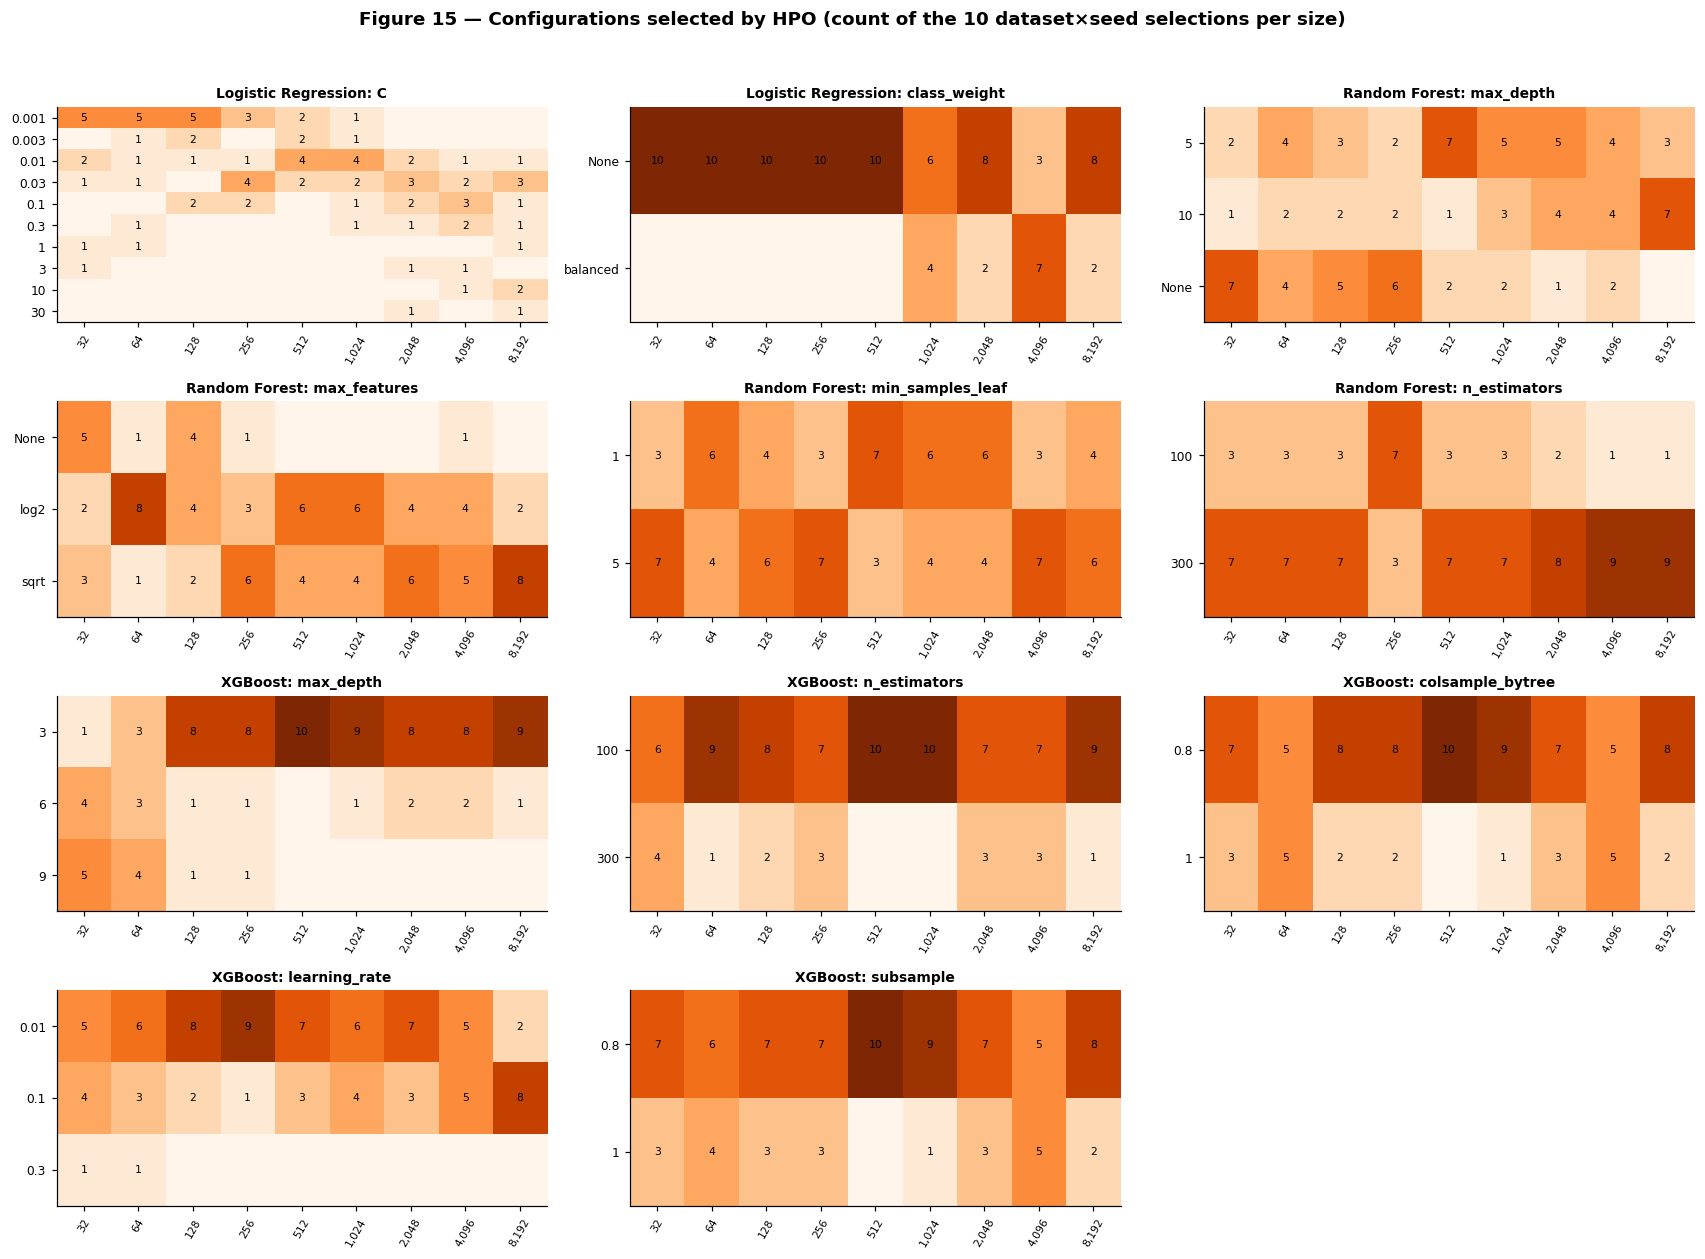

In [18]:
# ============================================================
# Cell 16 - RQ2 Outcome Classification, Gap Closure, and HPO Reliability
# ============================================================

# ------------------------------------------------------------
# Outcome classification: TabPFN-3 advantage before vs. after HPO
# ------------------------------------------------------------

# Compute the seed-mean ROC-AUC gap between TabPFN-3 and the conventional
# model at the common HPO training sizes, before and after HPO.
adv_d = summarize_delta(
    pairs_default[
        (pairs_default.metric == "roc_auc") &
        pairs_default.training_size.isin(SIZES_HPO)
    ],
    ["dataset", "trad_model", "training_size"],
)

adv_h = summarize_delta(
    pairs_hpo[pairs_hpo.metric == "roc_auc"],
    ["dataset", "trad_model", "training_size"],
)

# Match the default and HPO gaps for each dataset, model, and size.
outcome = adv_d.merge(
    adv_h,
    on=["dataset", "trad_model", "training_size"],
    suffixes=("_def", "_hpo"),
)

# Positive hpo_gain means that the TabPFN-3 advantage decreased after HPO;
# negative values mean that the advantage increased.
outcome["hpo_gain"] = (
    outcome["mean_def"] - outcome["mean_hpo"]
)

# Determine whether TabPFN-3 has a positive mean gap before and after HPO.
d_pos = outcome["mean_def"] > 0
h_pos = outcome["mean_hpo"] > 0

OUTCOME_LABELS = [
    "TabPFN-3 ahead before and after HPO",
    "Gap reversed by HPO (conventional now ahead)",
    "Conventional ahead before, TabPFN-3 ahead after HPO",
    "Conventional ahead before and after HPO",
]

# Assign each dataset × size × model cell to one of the four
# possible sign combinations.
outcome["outcome_id"] = np.select(
    [
        d_pos & h_pos,
        d_pos & ~h_pos,
        ~d_pos & h_pos,
    ],
    [0, 1, 2],
    default=3,
)

outcome["outcome"] = outcome["outcome_id"].map(
    dict(enumerate(OUTCOME_LABELS))
)

# Express the HPO-induced change as a fraction of the original
# TabPFN-3 advantage. Only calculate this when the initial advantage
# is at least 0.5 percentage points to avoid unstable ratios near zero.
outcome["share_closed"] = np.where(
    outcome["mean_def"] >= 0.005,
    outcome["hpo_gain"] / outcome["mean_def"],
    np.nan,
)

outcome.to_csv(
    TABLES_DIR / "rq2_outcome_classification.csv",
    index=False,
)

print(
    "Outcome classification counts "
    "(dataset × size × model cells, on seed-mean ROC-AUC):"
)

display(
    outcome
    .groupby(["dataset", "trad_model", "outcome"])
    .size()
    .unstack("outcome", fill_value=0)
)


# ------------------------------------------------------------
# Gap closure by training-data regime
# ------------------------------------------------------------

# Aggregate the default advantage, post-HPO advantage, HPO-induced change,
# and median gap-closure share within each predefined training regime.
closure_regime = (
    outcome
    .assign(regime=outcome["training_size"].map(regime_of))
    .groupby(["dataset", "trad_model", "regime"])
    .agg(
        mean_default_advantage=("mean_def", "mean"),
        mean_hpo_advantage=("mean_hpo", "mean"),
        mean_hpo_gain=("hpo_gain", "mean"),
        median_share_closed=("share_closed", "median"),
    )
    .reset_index()
)

# Preserve the predefined regime order in tables and plots.
closure_regime["regime"] = pd.Categorical(
    closure_regime["regime"],
    categories=REGIME_ORDER,
    ordered=True,
)

closure_regime = closure_regime.sort_values(
    ["dataset", "trad_model", "regime"]
)

closure_regime.to_csv(
    TABLES_DIR / "rq2_closure_by_regime.csv",
    index=False,
)

print(
    "\nGap closure by regime "
    "(advantages and HPO gain in ROC-AUC units; "
    "share closed = median HPO gain / default advantage):"
)

display(closure_regime)


# ------------------------------------------------------------
# Figure 13 — Outcome map
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11.5, 6.2),
)

# Each colour represents one of the four possible sign combinations
# of the TabPFN-3 gap before and after HPO.
cmap_out = ListedColormap([
    "#D55E00",
    "#F0E442",
    "#009E73",
    "#0072B2",
])

for ax, ds in zip(axes, EXPECTED_DATASETS):
    o = outcome[outcome.dataset == ds]

    # Matrix of categorical outcome IDs: rows = conventional models,
    # columns = HPO training sizes.
    ids = (
        o.pivot(
            index="trad_model",
            columns="training_size",
            values="outcome_id",
        )
        .loc[list(TRADITIONAL_MODELS), list(SIZES_HPO)]
    )

    # Matrix of post-HPO TabPFN-3 gaps and seed-level wins.
    adv = (
        o.pivot(
            index="trad_model",
            columns="training_size",
            values="mean_hpo",
        )
        .loc[list(TRADITIONAL_MODELS), list(SIZES_HPO)]
    )

    wins = (
        o.pivot(
            index="trad_model",
            columns="training_size",
            values="wins_hpo",
        )
        .loc[list(TRADITIONAL_MODELS), list(SIZES_HPO)]
    )

    ax.imshow(
        ids.to_numpy(),
        cmap=cmap_out,
        vmin=-0.5,
        vmax=3.5,
        aspect="auto",
    )

    ax.grid(False)
    cell_grid(ax, 3, len(SIZES_HPO))

    ax.set_xticks(range(len(SIZES_HPO)))
    ax.set_xticklabels([f"{n:,}" for n in SIZES_HPO])

    ax.set_yticks(range(3))
    ax.set_yticklabels(
        [MODEL_LABELS[m] for m in TRADITIONAL_MODELS]
    )

    # Annotate each cell with the post-HPO mean gap and number
    # of subset seeds where TabPFN-3 has the higher ROC-AUC.
    for i in range(3):
        for j in range(len(SIZES_HPO)):
            ax.text(
                j,
                i,
                f"{adv.iat[i, j] * 100:+.1f}\n"
                f"{int(wins.iat[i, j])}/{N_SEEDS}",
                ha="center",
                va="center",
                fontsize=8,
                color=(
                    "white"
                    if ids.iat[i, j] in (0, 3)
                    else "black"
                ),
            )

    ax.set_title(
        f"{DATASET_LABELS[ds]} — cell text: "
        "TabPFN-3 advantage after HPO (points) and seeds won"
    )

axes[-1].set_xlabel("Training size n")

fig.legend(
    handles=[
        Patch(
            facecolor=cmap_out(i / 3),
            label=label,
        )
        for i, label in enumerate(OUTCOME_LABELS)
    ],
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.09),
)

fig.suptitle(
    "Figure 13 — RQ2 outcome map (ROC-AUC): "
    "is TabPFN-3 still ahead once the conventional model is tuned?",
    fontweight="bold",
    y=1.0,
)

fig.tight_layout(rect=[0, 0.02, 1, 0.98])
save_fig(fig, "fig13_rq2_outcome_map")


# ------------------------------------------------------------
# HPO reliability: CV optimism
# ------------------------------------------------------------

# Compare the best CV ROC-AUC selected during HPO with the corresponding
# external-test ROC-AUC. Positive values indicate higher CV than test score.
hpo_meta["cv_optimism"] = (
    hpo_meta["best_cv_score"] -
    hpo_meta["roc_auc"]
)

# Summarize CV-to-test differences across subset seeds.
opt = (
    hpo_meta
    .groupby(["dataset", "model", "training_size"])
    .agg(
        mean=("cv_optimism", "mean"),
        sd=("cv_optimism", "std"),
        worst=("cv_optimism", "max"),
    )
    .reset_index()
)

opt.to_csv(
    TABLES_DIR / "rq2_cv_optimism.csv",
    index=False,
)


# Plot mean CV optimism with ±1 SD across subset seeds.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.4),
    sharey=True,
)

for ax, ds in zip(axes, EXPECTED_DATASETS):
    for model in TRADITIONAL_MODELS:
        g = opt[
            (opt.dataset == ds) &
            (opt.model == model)
        ].sort_values("training_size")

        ax.plot(
            g.training_size,
            g["mean"] * 100,
            color=COLORS[model],
            marker=MARKERS[model],
            ms=4.5,
            lw=2,
            label=MODEL_LABELS[model],
        )

        ax.fill_between(
            g.training_size,
            (g["mean"] - g["sd"]) * 100,
            (g["mean"] + g["sd"]) * 100,
            color=COLORS[model],
            alpha=0.10,
            lw=0,
        )

    # Zero indicates equal CV and external-test ROC-AUC.
    ax.axhline(0, color="black", lw=1)

    ax.set_title(DATASET_LABELS[ds])
    size_axis(ax, SIZES_HPO)

axes[0].set_ylabel(
    "Best CV ROC-AUC − test ROC-AUC (points)\n"
    ">0: CV over-promised"
)

axes[0].legend()

fig.suptitle(
    "Figure 14 — HPO reliability: how far does the selected "
    "configuration's CV score sit from its external-test score?",
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()
save_fig(fig, "fig14_rq2_cv_optimism")


# ------------------------------------------------------------
# Hyperparameters selected by HPO
# ------------------------------------------------------------

import ast


def parse_params(value):
    """Convert stored hyperparameters into a dictionary when possible."""
    if isinstance(value, dict):
        d = value
    else:
        try:
            d = json.loads(value)
        except Exception:
            try:
                d = ast.literal_eval(value)
            except Exception:
                return {}

    # Remove pipeline prefixes such as "model__" from parameter names.
    return {
        str(k).split("__")[-1]: v
        for k, v in d.items()
    }


selected_params = None

# best_params may not be present in all exported HPO result tables.
if "best_params" in hpo_meta.columns:
    parsed = hpo_meta["best_params"].map(parse_params)

    # Only continue if every HPO row contains at least one parsable parameter.
    if parsed.map(len).gt(0).all():
        selected_params = pd.concat(
            [
                hpo_meta[KEY].reset_index(drop=True),
                pd.DataFrame(list(parsed)),
            ],
            axis=1,
        )

        selected_params.to_csv(
            TABLES_DIR / "rq2_selected_hyperparameters.csv",
            index=False,
        )


if selected_params is None:
    print(
        "best_params not available/parsable in the HPO CSV — "
        "hyper-parameter selection figure skipped."
    )

else:
    panels = []

    # Build one panel for every non-constant hyperparameter that varies
    # across HPO selections for a conventional model.
    for model in TRADITIONAL_MODELS:
        sub = (
            selected_params[selected_params.model == model]
            .dropna(axis=1, how="all")
        )

        for col in [
            c for c in sub.columns
            if c not in KEY
        ]:
            # Constant parameters do not provide useful information
            # about how HPO selections vary across runs.
            if sub[col].astype(str).nunique() > 1:
                panels.append(
                    (model, col, sub[[*KEY, col]])
                )

    ncols = 3
    nrows = int(np.ceil(len(panels) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5.2 * ncols, 2.7 * nrows + 0.6),
    )

    axes = np.atleast_1d(axes).ravel()

    for ax, (model, col, sub) in zip(axes, panels):

        def _label(v):
            # Represent None explicitly and avoid unnecessary ".0"
            # formatting for integer-valued floating-point values.
            if v is None or (
                isinstance(v, float) and np.isnan(v)
            ):
                return "None"

            if isinstance(v, (float, np.floating)) and float(v).is_integer():
                return str(int(v))

            return str(v)

        vals = sub[col].map(_label)

        def _sort_key(s):
            # Sort numeric-looking categories numerically first,
            # followed by text categories alphabetically.
            try:
                return (0, float(s), s)
            except ValueError:
                return (1, 0.0, s)

        order = sorted(
            vals.unique(),
            key=_sort_key,
        )

        # Count how often each selected value occurs at each HPO size.
        share = (
            pd.crosstab(
                vals,
                sub["training_size"],
            )
            .reindex(
                index=order,
                columns=list(SIZES_HPO),
                fill_value=0,
            )
        )

        # Convert counts into within-size selection proportions.
        share_frac = (
            share /
            share.sum(axis=0)
        )

        ax.imshow(
            share_frac.to_numpy(),
            cmap="Oranges",
            vmin=0,
            vmax=1,
            aspect="auto",
        )

        ax.grid(False)

        ax.set_xticks(range(len(SIZES_HPO)))
        ax.set_xticklabels(
            [f"{n:,}" for n in SIZES_HPO],
            rotation=60,
            fontsize=7,
        )

        ax.set_yticks(range(len(order)))
        ax.set_yticklabels(order, fontsize=8)

        # Display the raw selection count in each non-empty cell.
        for i in range(share.shape[0]):
            for j in range(share.shape[1]):
                if share.iat[i, j]:
                    ax.text(
                        j,
                        i,
                        int(share.iat[i, j]),
                        ha="center",
                        va="center",
                        fontsize=7,
                    )

        ax.set_title(
            f"{MODEL_LABELS[model]}: {col}",
            fontsize=9,
        )

    # Hide unused axes when the number of parameter panels is not
    # an exact multiple of the number of columns.
    for ax in axes[len(panels):]:
        ax.axis("off")

    fig.suptitle(
        f"Figure 15 — Configurations selected by HPO "
        f"(count of the {len(EXPECTED_DATASETS) * N_SEEDS} "
        "dataset×seed selections per size)",
        fontweight="bold",
        y=1.0,
    )

    fig.tight_layout(
        rect=[0, 0, 1, 0.98]
    )

    save_fig(
        fig,
        "fig15_rq2_selected_hyperparameters",
    )

In [19]:
# ============================================================
# Cell 17 — RQ2 auto-generated findings
# ============================================================
def rq2_findings():
    lines = ["### RQ2 — computed findings (sizes 32–8,192)"]
    e = hpo_effect["roc_auc"]
    for ds in EXPECTED_DATASETS:
        lines.append(f"\n**{DATASET_LABELS[ds]}**")
        for model in TRADITIONAL_MODELS:
            t = e[(e.dataset == ds) & (e.trad_model == model)]
            o = outcome[(outcome.dataset == ds) & (outcome.trad_model == model)]
            best = t.loc[t["mean"].idxmax()]
            cnt = o["outcome_id"].value_counts().to_dict()
            share = o["share_closed"].median()
            lines.append(
                f"- **{MODEL_LABELS[model]}**: HPO changes ROC-AUC by {fmt_pts(t['mean'].mean())} on average (largest {fmt_pts(best['mean'])} at n = {int(best['training_size']):,}; "
                f"improved on the seed-mean in {int((t['mean'] > 0).sum())}/{len(t)} sizes). TabPFN-3 stays ahead after HPO in {cnt.get(0, 0)}/{len(o)} sizes, "
                f"is overtaken in {cnt.get(1, 0)}, and the conventional model is ahead in both settings in {cnt.get(3, 0)}"
                + (f"; median share of the default advantage closed: {share:.0%}." if np.isfinite(share) else ".")
            )
    lg = outcome[outcome.training_size == max(SIZES_HPO)]
    lines.append(f"\n**At n = {max(SIZES_HPO):,} after HPO** (ROC-AUC advantage of TabPFN-3, seeds won): " + "; ".join(
        f"{DATASET_LABELS[r.dataset]} vs {MODEL_LABELS[r.trad_model]} {fmt_pts(r.mean_hpo)} ({int(r.wins_hpo)}/{N_SEEDS})" for r in lg.itertuples()) + ".")
    o = opt[opt.training_size == min(SIZES_HPO)]
    lines.append(f"\n**CV optimism at n = {min(SIZES_HPO)}** (best CV − test ROC-AUC): " + "; ".join(
        f"{DATASET_LABELS[r.dataset]} {MODEL_LABELS[r.model]} {fmt_pts(r.mean)}" for r in o.itertuples()) + ".")
    return "\n".join(lines)


rq2_text = rq2_findings()
display(Markdown(rq2_text))

### RQ2 — computed findings (sizes 32–8,192)

**Diabetes (BRFSS 2015)**
- **Logistic Regression**: HPO changes ROC-AUC by +1.2 pts on average (largest +4.9 pts at n = 64; improved on the seed-mean in 8/9 sizes). TabPFN-3 stays ahead after HPO in 6/9 sizes, is overtaken in 3, and the conventional model is ahead in both settings in 0; median share of the default advantage closed: 32%.
- **Random Forest**: HPO changes ROC-AUC by +1.3 pts on average (largest +1.8 pts at n = 512; improved on the seed-mean in 9/9 sizes). TabPFN-3 stays ahead after HPO in 7/9 sizes, is overtaken in 1, and the conventional model is ahead in both settings in 1; median share of the default advantage closed: 67%.
- **XGBoost**: HPO changes ROC-AUC by +2.7 pts on average (largest +4.0 pts at n = 1,024; improved on the seed-mean in 9/9 sizes). TabPFN-3 stays ahead after HPO in 9/9 sizes, is overtaken in 0, and the conventional model is ahead in both settings in 0; median share of the default advantage closed: 67%.

**Cardiovascular**
- **Logistic Regression**: HPO changes ROC-AUC by +0.9 pts on average (largest +3.6 pts at n = 32; improved on the seed-mean in 8/9 sizes). TabPFN-3 stays ahead after HPO in 9/9 sizes, is overtaken in 0, and the conventional model is ahead in both settings in 0; median share of the default advantage closed: 14%.
- **Random Forest**: HPO changes ROC-AUC by +1.9 pts on average (largest +2.8 pts at n = 512; improved on the seed-mean in 8/9 sizes). TabPFN-3 stays ahead after HPO in 9/9 sizes, is overtaken in 0, and the conventional model is ahead in both settings in 0; median share of the default advantage closed: 85%.
- **XGBoost**: HPO changes ROC-AUC by +4.0 pts on average (largest +5.8 pts at n = 256; improved on the seed-mean in 9/9 sizes). TabPFN-3 stays ahead after HPO in 9/9 sizes, is overtaken in 0, and the conventional model is ahead in both settings in 0; median share of the default advantage closed: 88%.

**At n = 8,192 after HPO** (ROC-AUC advantage of TabPFN-3, seeds won): Cardiovascular vs Logistic Regression +1.0 pts (5/5); Cardiovascular vs Random Forest +0.4 pts (5/5); Cardiovascular vs XGBoost +0.2 pts (5/5); Diabetes (BRFSS 2015) vs Logistic Regression +0.8 pts (5/5); Diabetes (BRFSS 2015) vs Random Forest +0.6 pts (5/5); Diabetes (BRFSS 2015) vs XGBoost +0.2 pts (5/5).

**CV optimism at n = 32** (best CV − test ROC-AUC): Cardiovascular Logistic Regression +4.3 pts; Cardiovascular Random Forest +6.7 pts; Cardiovascular XGBoost +4.5 pts; Diabetes (BRFSS 2015) Logistic Regression +4.0 pts; Diabetes (BRFSS 2015) Random Forest +11.2 pts; Diabetes (BRFSS 2015) XGBoost +11.2 pts.

## 4 · RQ3 — Training-set size, performance and seed-level stability

**Operational definition (unchanged from the exposé):** *seed-level stability* = sample SD of ROC-AUC across the five subset seeds at a
fixed `dataset × condition × model × training size`. Because `model_seed`, `cv_seed` and `hpo_seed` are fixed, this SD isolates variation
induced by **which training rows were drawn**.

Two cautions shape the analysis below:

* An SD from **five** observations has a relative standard error of roughly 35 %. Single-size SD comparisons are therefore noisy; conclusions
  are drawn from *patterns across sizes* (pooled SD by regime, sign counts), not from any one cell.
* Because all models share each subset, part of the SD is *common* to the models (§1). §4.2 (Figure 19) measures this shared component directly: it is large at several small sizes (about 0.6–0.8 at n = 8, 16, 32 and 64) and close to zero at n = 2,048–4,096, but it does not decline monotonically with n.

In the HPO condition TabPFN-3 is again the unchanged comparator (restricted to the HPO sizes).

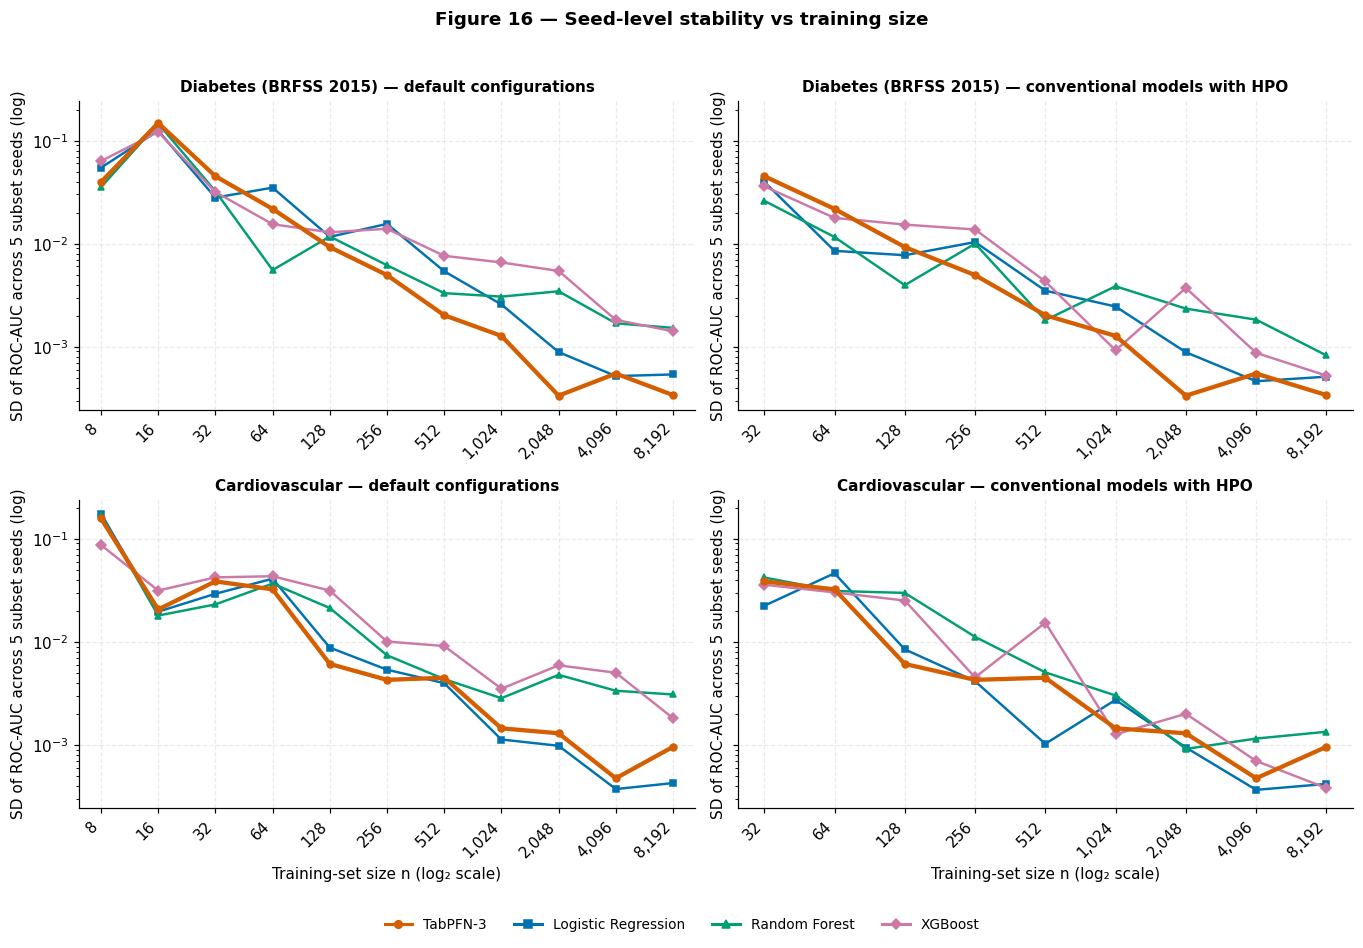

Pooled SD by regime (√ mean variance over sizes) and ratio conventional / TabPFN-3 (>1: TabPFN-3 more stable):


,condition,dataset,regime,model,pooled_sd,sizes,tabpfn_pooled_sd,sd_ratio_conventional_over_tabpfn,sizes_tabpfn_more_stable
0,default,cardiovascular,tiny (8–16),logistic_regression,0.1250,2,0.1123,1.1135,1
1,default,cardiovascular,small (32–128),logistic_regression,0.0295,3,0.0293,1.0077,2
2,default,cardiovascular,"medium (256–1,024)",logistic_regression,0.0039,3,0.0037,1.0644,1
3,default,cardiovascular,"large (2,048–8,192)",logistic_regression,0.0007,3,0.0010,0.6741,0
4,default,cardiovascular,tiny (8–16),random_forest,0.1197,2,0.1123,1.0665,1
5,default,cardiovascular,small (32–128),random_forest,0.0279,3,0.0293,0.9527,2
6,default,cardiovascular,"medium (256–1,024)",random_forest,0.0052,3,0.0037,1.4212,2
7,default,cardiovascular,"large (2,048–8,192)",random_forest,0.0038,3,0.0010,3.9321,3
8,default,cardiovascular,tiny (8–16),xgboost,0.0655,2,0.1123,0.5836,1
9,default,cardiovascular,small (32–128),xgboost,0.0393,3,0.0293,1.3437,3


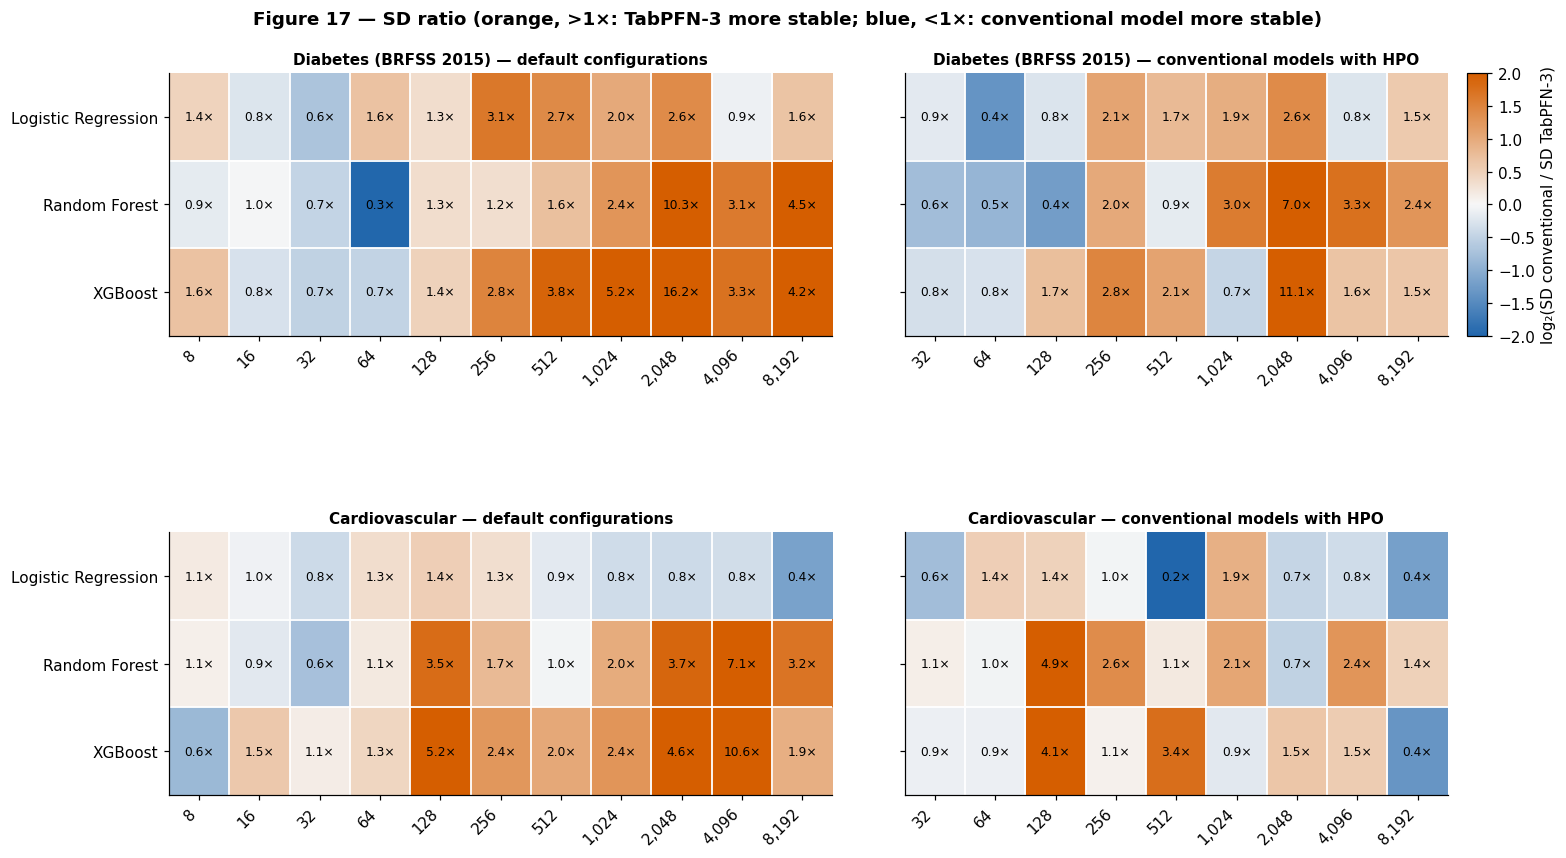

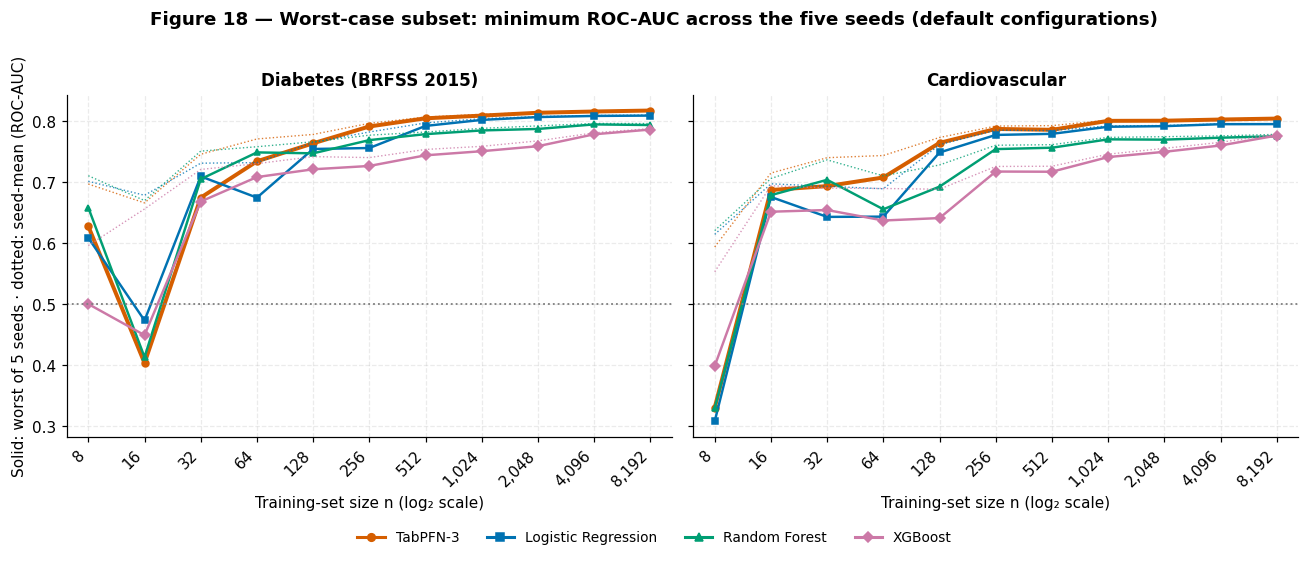

In [20]:
# ============================================================
# Cell 18 - RQ3 Stability Curves, SD Ratios, and Worst-Case Seeds
# ============================================================

# Compute per-dataset, model, and training-size ROC-AUC statistics
# across the five subset seeds for each analysis condition.
STAB = {
    cond: cell_stats(PANEL[cond], "roc_auc")
    for cond in PANEL
}

# Combine condition-specific summaries into one exportable table.
stab_long = pd.concat(
    [
        v.assign(condition=k)
        for k, v in STAB.items()
    ],
    ignore_index=True,
)

stab_long.to_csv(
    TABLES_DIR / "rq3_cell_statistics.csv",
    index=False,
)

# Human-readable labels and training-size sets for each condition.
COND_TITLE = {
    "default": "default configurations",
    "hpo": "conventional models with HPO",
}

COND_SIZES = {
    "default": SIZES_ALL,
    "hpo": SIZES_HPO,
}


# ------------------------------------------------------------
# Figure 16 — SD versus training size
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12.5, 8.4),
    sharey=True,
)

for r, ds in enumerate(EXPECTED_DATASETS):
    for c, cond in enumerate(("default", "hpo")):
        ax = axes[r, c]

        for model in MODELS4:
            g = STAB[cond][
                (STAB[cond].dataset == ds) &
                (STAB[cond].model == model)
            ].sort_values("training_size")

            # Plot the standard deviation of ROC-AUC across the five
            # subset seeds. TabPFN-3 is visually emphasized.
            ax.plot(
                g.training_size,
                g["sd"],
                color=COLORS[model],
                marker=MARKERS[model],
                ms=4.5,
                lw=2.8 if model == "tabpfn" else 1.6,
                zorder=5 if model == "tabpfn" else 3,
            )

        # A logarithmic y-axis makes differences in small SD values
        # easier to compare across training sizes.
        ax.set_yscale("log")
        ax.set_title(
            f"{DATASET_LABELS[ds]} — {COND_TITLE[cond]}",
            fontsize=10,
        )
        ax.set_ylabel(
            "SD of ROC-AUC across 5 subset seeds (log)"
        )
        size_axis(ax, COND_SIZES[cond])

fig.legend(
    handles=model_handles(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.01),
)

fig.suptitle(
    "Figure 16 — Seed-level stability vs training size",
    fontweight="bold",
    y=1.0,
)

fig.tight_layout(
    rect=[0, 0.04, 1, 0.98]
)

save_fig(fig, "fig16_rq3_stability_curves")


# ------------------------------------------------------------
# SD ratio: conventional model / TabPFN-3
# ------------------------------------------------------------

# Reshape SD values so each conventional model can be compared directly
# with TabPFN-3 at the same dataset, condition, and training size.
sd_wide = stab_long.pivot_table(
    index=["condition", "dataset", "training_size"],
    columns="model",
    values="sd",
)

sd_ratio = pd.concat(
    {
        m: sd_wide[m] / sd_wide["tabpfn"]
        for m in TRADITIONAL_MODELS
    },
    axis=1,
).reset_index()

sd_ratio.to_csv(
    TABLES_DIR / "rq3_sd_ratio_by_size.csv",
    index=False,
)


# ------------------------------------------------------------
# Pooled SD ratio by training regime
# ------------------------------------------------------------

# Pool variance across training sizes within each regime by taking
# the square root of the mean per-size variance.
tmp = stab_long.assign(
    regime=stab_long.training_size.map(regime_of),
    var=stab_long["sd"] ** 2,
)

pooled = (
    tmp
    .groupby(
        ["condition", "dataset", "regime", "model"]
    )
    .agg(
        pooled_sd=(
            "var",
            lambda v: float(np.sqrt(np.mean(v))),
        ),
        sizes=("training_size", "count"),
    )
    .reset_index()
)

# Extract the corresponding pooled TabPFN-3 SD for each regime.
tp_pooled = (
    pooled[pooled.model == "tabpfn"]
    .rename(columns={"pooled_sd": "tabpfn_pooled_sd"})[
        ["condition", "dataset", "regime", "tabpfn_pooled_sd"]
    ]
)

# Compare each conventional model's pooled SD with TabPFN-3.
pooled_ratio = (
    pooled[pooled.model != "tabpfn"]
    .merge(
        tp_pooled,
        on=["condition", "dataset", "regime"],
    )
)

pooled_ratio["sd_ratio_conventional_over_tabpfn"] = (
    pooled_ratio["pooled_sd"] /
    pooled_ratio["tabpfn_pooled_sd"]
)


# Count training sizes within each regime where TabPFN-3 has
# the lower SD, i.e. conventional SD / TabPFN SD > 1.
per_size_flag = sd_ratio.melt(
    id_vars=["condition", "dataset", "training_size"],
    var_name="model",
    value_name="ratio",
)

per_size_flag["regime"] = (
    per_size_flag["training_size"].map(regime_of)
)

lower = (
    per_size_flag
    .assign(
        tabpfn_lower=per_size_flag["ratio"] > 1
    )
    .groupby(
        ["condition", "dataset", "regime", "model"]
    )
    .agg(
        sizes_tabpfn_more_stable=("tabpfn_lower", "sum")
    )
    .reset_index()
)

pooled_ratio = pooled_ratio.merge(
    lower,
    on=["condition", "dataset", "regime", "model"],
)

# Keep regimes in the predefined order.
pooled_ratio["regime"] = pd.Categorical(
    pooled_ratio["regime"],
    categories=REGIME_ORDER,
    ordered=True,
)

pooled_ratio = (
    pooled_ratio
    .sort_values(
        ["condition", "dataset", "model", "regime"]
    )
    .reset_index(drop=True)
)

pooled_ratio.to_csv(
    TABLES_DIR / "rq3_pooled_sd_by_regime.csv",
    index=False,
)

print(
    "Pooled SD by regime (√ mean variance over sizes) and "
    "ratio conventional / TabPFN-3 (>1: TabPFN-3 more stable):"
)

display(pooled_ratio)


# ------------------------------------------------------------
# Figure 17 — SD-ratio heat maps
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 8.2),
    gridspec_kw={
        "width_ratios": [11, 9],
        "hspace": 0.75,
        "wspace": 0.12,
    },
)

fig.subplots_adjust(
    right=0.9,
    top=0.9,
    bottom=0.1,
)

# Symmetric limits are applied to log2(SD ratio):
# 0 = equal stability, positive = TabPFN-3 has lower SD.
vmax_log = 2.0

for r, ds in enumerate(EXPECTED_DATASETS):
    for c, cond in enumerate(("default", "hpo")):
        ax = axes[r, c]
        sizes = COND_SIZES[cond]

        s = (
            sd_ratio[
                (sd_ratio.condition == cond) &
                (sd_ratio.dataset == ds)
            ]
            .set_index("training_size")
            .loc[
                list(sizes),
                list(TRADITIONAL_MODELS),
            ]
            .T
        )

        # Log-transform the ratio so values above and below 1 are
        # represented symmetrically around zero.
        im = ax.imshow(
            np.log2(s.to_numpy()),
            cmap=GAP_CMAP,
            norm=TwoSlopeNorm(
                vcenter=0,
                vmin=-vmax_log,
                vmax=vmax_log,
            ),
            aspect="auto",
        )

        ax.grid(False)
        cell_grid(ax, 3, len(sizes))

        ax.set_xticks(range(len(sizes)))
        ax.set_xticklabels(
            [f"{n:,}" for n in sizes],
            rotation=45,
            ha="right",
        )

        ax.set_yticks(range(3))
        ax.set_yticklabels(
            [
                MODEL_LABELS[m]
                for m in TRADITIONAL_MODELS
            ]
            if c == 0
            else []
        )

        # Show the original SD ratio rather than the transformed log2 value.
        for i in range(3):
            for j in range(len(sizes)):
                ax.text(
                    j,
                    i,
                    f"{s.iat[i, j]:.1f}×",
                    ha="center",
                    va="center",
                    fontsize=8,
                )

        ax.set_title(
            f"{DATASET_LABELS[ds]} — {COND_TITLE[cond]}",
            fontsize=10,
        )

side_cbar(
    fig,
    axes[0, 1],
    im,
    "log₂(SD conventional / SD TabPFN-3)",
    width=0.012,
)

fig.suptitle(
    "Figure 17 — SD ratio "
    "(orange, >1×: TabPFN-3 more stable; "
    "blue, <1×: conventional model more stable)",
    fontweight="bold",
    y=0.97,
)

save_fig(
    fig,
    "fig17_rq3_sd_ratio_heatmaps",
)


# ------------------------------------------------------------
# Figure 18 — Worst-case subset seed
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.6),
    sharey=True,
)

for ax, ds in zip(axes, EXPECTED_DATASETS):
    for model in MODELS4:
        g = STAB["default"][
            (STAB["default"].dataset == ds) &
            (STAB["default"].model == model)
        ].sort_values("training_size")

        # Solid line: minimum ROC-AUC among the five subset seeds.
        ax.plot(
            g.training_size,
            g["min"],
            color=COLORS[model],
            marker=MARKERS[model],
            ms=4.5,
            lw=2.6 if model == "tabpfn" else 1.6,
        )

        # Dotted line: mean ROC-AUC across the same five seeds.
        ax.plot(
            g.training_size,
            g["mean"],
            color=COLORS[model],
            lw=0.9,
            ls=":",
            alpha=0.8,
        )

    # ROC-AUC chance level for reference.
    ax.axhline(
        0.5,
        color="grey",
        ls=":",
        lw=1.2,
    )

    ax.set_title(DATASET_LABELS[ds])
    size_axis(ax, SIZES_ALL)

axes[0].set_ylabel(
    "Solid: worst of 5 seeds · "
    "dotted: seed-mean (ROC-AUC)"
)

fig.legend(
    handles=model_handles(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.06),
)

fig.suptitle(
    "Figure 18 — Worst-case subset: minimum ROC-AUC across "
    "the five seeds (default configurations)",
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()
save_fig(fig, "fig18_rq3_worst_case")

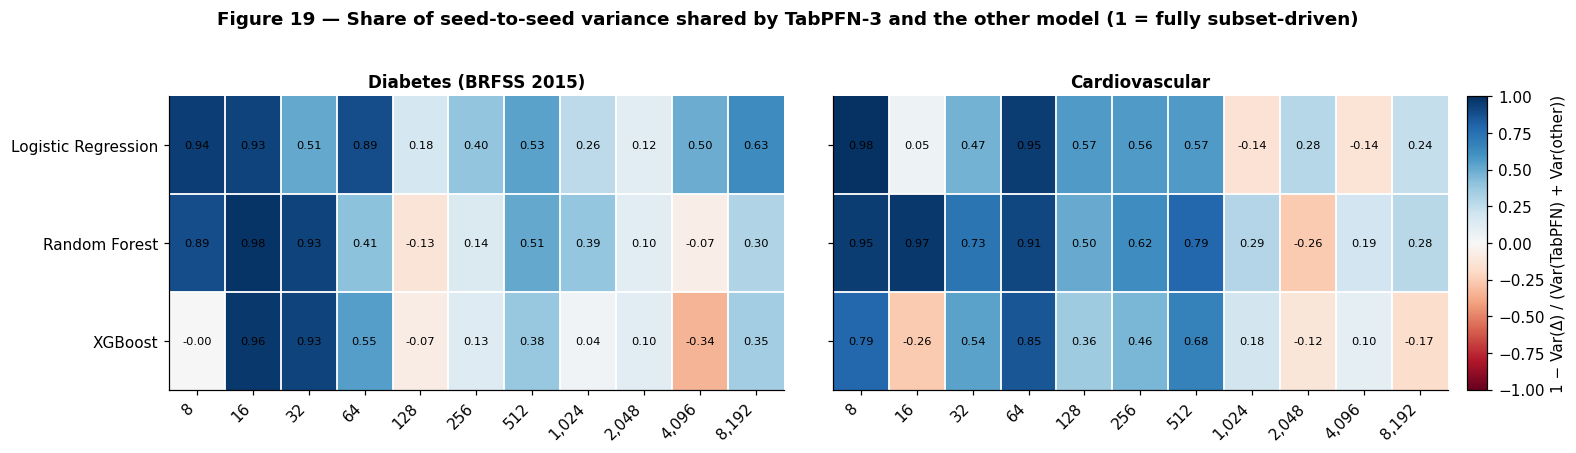

Median SD ratio HPO / default (<1: HPO made results MORE stable across subsets), by dataset and model:


median    min    max
dataset        model                                    
cardiovascular logistic_regression  0.9619 0.2579 2.4262
               random_forest        1.0626 0.1911 1.8248
               xgboost              0.4490 0.1394 1.6849
diabetes       logistic_regression  0.8915 0.2437 1.4243
               random_forest        0.8075 0.3369 2.0918
               xgboost              0.6837 0.1405 1.1876


SD-vs-n trend: slope of log₂(SD) per doubling of n (−0.5 ≈ the 1/√n rate); Spearman is descriptive only:


,condition,dataset,model,spearman_sd_vs_log2n,log2_sd_slope_per_doubling,sd_at_smallest_n,sd_at_largest_n
0,default,diabetes,tabpfn,-0.9455,-0.8928,0.0395,0.0003
1,default,diabetes,logistic_regression,-0.9636,-0.8048,0.0545,0.0005
2,default,diabetes,random_forest,-0.9364,-0.5603,0.0353,0.0015
3,default,diabetes,xgboost,-0.9818,-0.5682,0.0631,0.0014
4,default,cardiovascular,tabpfn,-0.9545,-0.7514,0.1574,0.0010
5,default,cardiovascular,logistic_regression,-0.9545,-0.8409,0.1757,0.0004
6,default,cardiovascular,random_forest,-0.8636,-0.5002,0.1684,0.0031
7,default,cardiovascular,xgboost,-0.9364,-0.5096,0.0872,0.0018
8,hpo,diabetes,tabpfn,-0.9500,-0.9279,0.0451,0.0003
9,hpo,diabetes,logistic_regression,-0.9333,-0.7677,0.0398,0.0005


In [21]:
# ============================================================
# Cell 19 - Shared Subset Effect, HPO Effect on Stability, Trend Diagnostics
# ============================================================

# Use seed-level paired ROC-AUC results to examine whether TabPFN-3
# and conventional models respond similarly to the same training subset.
roc_pairs = pairs_default[pairs_default.metric == "roc_auc"]

shared = (
    roc_pairs
    .groupby(["dataset", "trad_model", "training_size"])
    .agg(
        var_tabpfn=("tabpfn", "var"),
        var_trad=("trad", "var"),
        var_delta=("delta", "var"),
    )
    .reset_index()
)

# Pearson correlation across the five subset seeds.
# With only five observations per cell, this is descriptive rather
# than a formal estimate of population-level correlation.
corr_rows = []
for (ds, model, n), g in roc_pairs.groupby(
    ["dataset", "trad_model", "training_size"]
):
    corr_rows.append(
        np.corrcoef(g["tabpfn"], g["trad"])[0, 1]
        if g["tabpfn"].std() > 0 and g["trad"].std() > 0
        else np.nan
    )

shared["corr"] = corr_rows

# Approximate the proportion of the combined seed-level variance
# that is shared between the two models through their paired delta.
shared["shared_variance_share"] = (
    1 - shared["var_delta"] / (shared["var_tabpfn"] + shared["var_trad"])
)

shared.to_csv(
    TABLES_DIR / "rq3_shared_subset_effect.csv",
    index=False,
)


# ------------------------------------------------------------
# Figure 19: Shared subset effect
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 4.6),
    gridspec_kw={"wspace": 0.08},
)
fig.subplots_adjust(right=0.9, top=0.8, bottom=0.22)

for k, (ax, ds) in enumerate(zip(axes, EXPECTED_DATASETS)):
    # Arrange the shared-variance statistic as model × training-size
    # matrix for direct heat-map comparison.
    m = (
        shared[shared.dataset == ds]
        .pivot(
            index="trad_model",
            columns="training_size",
            values="shared_variance_share",
        )
        .loc[list(TRADITIONAL_MODELS), list(SIZES_ALL)]
    )

    im = ax.imshow(
        m.to_numpy(),
        cmap="RdBu",
        norm=TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1),
        aspect="auto",
    )

    ax.grid(False)
    cell_grid(ax, 3, len(SIZES_ALL))
    ax.set_xticks(range(len(SIZES_ALL)))
    ax.set_xticklabels(
        [f"{n:,}" for n in SIZES_ALL],
        rotation=45,
        ha="right",
    )
    ax.set_yticks(range(3))
    ax.set_yticklabels(
        [MODEL_LABELS[q] for q in TRADITIONAL_MODELS]
        if k == 0 else []
    )

    # Annotate each cell with the numerical shared-variance estimate.
    for i in range(3):
        for j in range(len(SIZES_ALL)):
            ax.text(
                j,
                i,
                f"{m.iat[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=7.5,
            )

    ax.set_title(DATASET_LABELS[ds])

side_cbar(
    fig,
    axes[1],
    im,
    "1 − Var(Δ) / (Var(TabPFN) + Var(other))",
)

fig.suptitle(
    "Figure 19 — Share of seed-to-seed variance shared by TabPFN-3 "
    "and the other model (1 = fully subset-driven)",
    fontweight="bold",
    y=0.97,
)

save_fig(fig, "fig19_rq3_shared_subset_effect")


# ------------------------------------------------------------
# HPO effect on stability
# ------------------------------------------------------------

# Compare conventional-model SD under HPO with the corresponding
# default SD at the same dataset and training size.
sd_def = STAB["default"][
    STAB["default"].training_size.isin(SIZES_HPO)
    & (STAB["default"].model != "tabpfn")
]

sd_hpo = STAB["hpo"][STAB["hpo"].model != "tabpfn"]

sd_change = sd_def.merge(
    sd_hpo,
    on=["dataset", "model", "training_size"],
    suffixes=("_def", "_hpo"),
)

# Ratio below 1 indicates lower seed-level variability after HPO.
sd_change["sd_ratio_hpo_over_default"] = (
    sd_change["sd_hpo"] / sd_change["sd_def"]
)

sd_change[
    [
        "dataset",
        "model",
        "training_size",
        "sd_def",
        "sd_hpo",
        "sd_ratio_hpo_over_default",
    ]
].to_csv(
    TABLES_DIR / "rq3_hpo_effect_on_sd.csv",
    index=False,
)

print(
    "Median SD ratio HPO / default "
    "(<1: HPO made results MORE stable across subsets), "
    "by dataset and model:"
)

display(
    sd_change
    .groupby(["dataset", "model"])["sd_ratio_hpo_over_default"]
    .agg(["median", "min", "max"])
)


# ------------------------------------------------------------
# Trend diagnostics: SD versus training size
# ------------------------------------------------------------

# Evaluate whether seed-level SD decreases systematically with n.
# These statistics are descriptive because only the studied training
# sizes are included and the number of points per series is small.
trend_rows = []

for cond in PANEL:
    for ds in EXPECTED_DATASETS:
        for model in MODELS4:
            g = (
                STAB[cond][
                    (STAB[cond].dataset == ds)
                    & (STAB[cond].model == model)
                ]
                .sort_values("training_size")
            )

            # Spearman correlation measures the monotonic relationship
            # between training size and seed-level SD.
            rho, _ = stats.spearmanr(
                np.log2(g.training_size),
                g["sd"],
            )

            # Log-log slope describes the change in SD per doubling of n.
            # A slope near -0.5 corresponds to the classical 1/sqrt(n) rate.
            slope = np.polyfit(
                np.log2(g.training_size),
                np.log2(g["sd"]),
                1,
            )[0]

            trend_rows.append(
                {
                    "condition": cond,
                    "dataset": ds,
                    "model": model,
                    "spearman_sd_vs_log2n": rho,
                    "log2_sd_slope_per_doubling": slope,
                    "sd_at_smallest_n": g["sd"].iat[0],
                    "sd_at_largest_n": g["sd"].iat[-1],
                }
            )

sd_trends = pd.DataFrame(trend_rows)

sd_trends.to_csv(
    TABLES_DIR / "rq3_sd_trends.csv",
    index=False,
)

print(
    "\nSD-vs-n trend: slope of log₂(SD) per doubling of n "
    "(−0.5 ≈ the 1/√n rate); Spearman is descriptive only:"
)

display(sd_trends)

Fitted asymptote a, curvature d, rate c (fit on n ≥ 32; 9 points, 3 parameters — descriptive, not inferential).
at_bound = True: the optimiser stopped on a parameter bound, so the asymptote is NOT identified by the data; do not interpret it.


,condition,dataset,model,a,d,c,r2,at_bound,auc_at_largest_n,remaining_gap_to_asymptote
0,default,diabetes,tabpfn,0.8245,0.0791,0.4797,0.9892,False,0.8176,0.0069
1,default,diabetes,logistic_regression,0.8272,0.1047,0.3813,0.9535,False,0.8098,0.0174
2,default,diabetes,random_forest,0.8139,0.0649,0.2524,0.9915,False,0.7958,0.0181
3,default,diabetes,xgboost,0.8176,0.1002,0.1769,0.9487,True,0.7876,0.0300
4,default,cardiovascular,tabpfn,0.8125,0.0786,0.4882,0.9459,False,0.8051,0.0074
5,default,cardiovascular,logistic_regression,0.8050,0.1251,0.6030,0.8867,False,0.7955,0.0095
6,default,cardiovascular,random_forest,0.8081,0.0893,0.2148,0.7706,True,0.7781,0.0300
7,default,cardiovascular,xgboost,0.8085,0.1335,0.2114,0.9049,True,0.7785,0.0300
8,hpo,diabetes,tabpfn,0.8245,0.0791,0.4797,0.9892,False,0.8176,0.0069
9,hpo,diabetes,logistic_regression,0.8258,0.0590,0.2619,0.9604,False,0.8098,0.0160


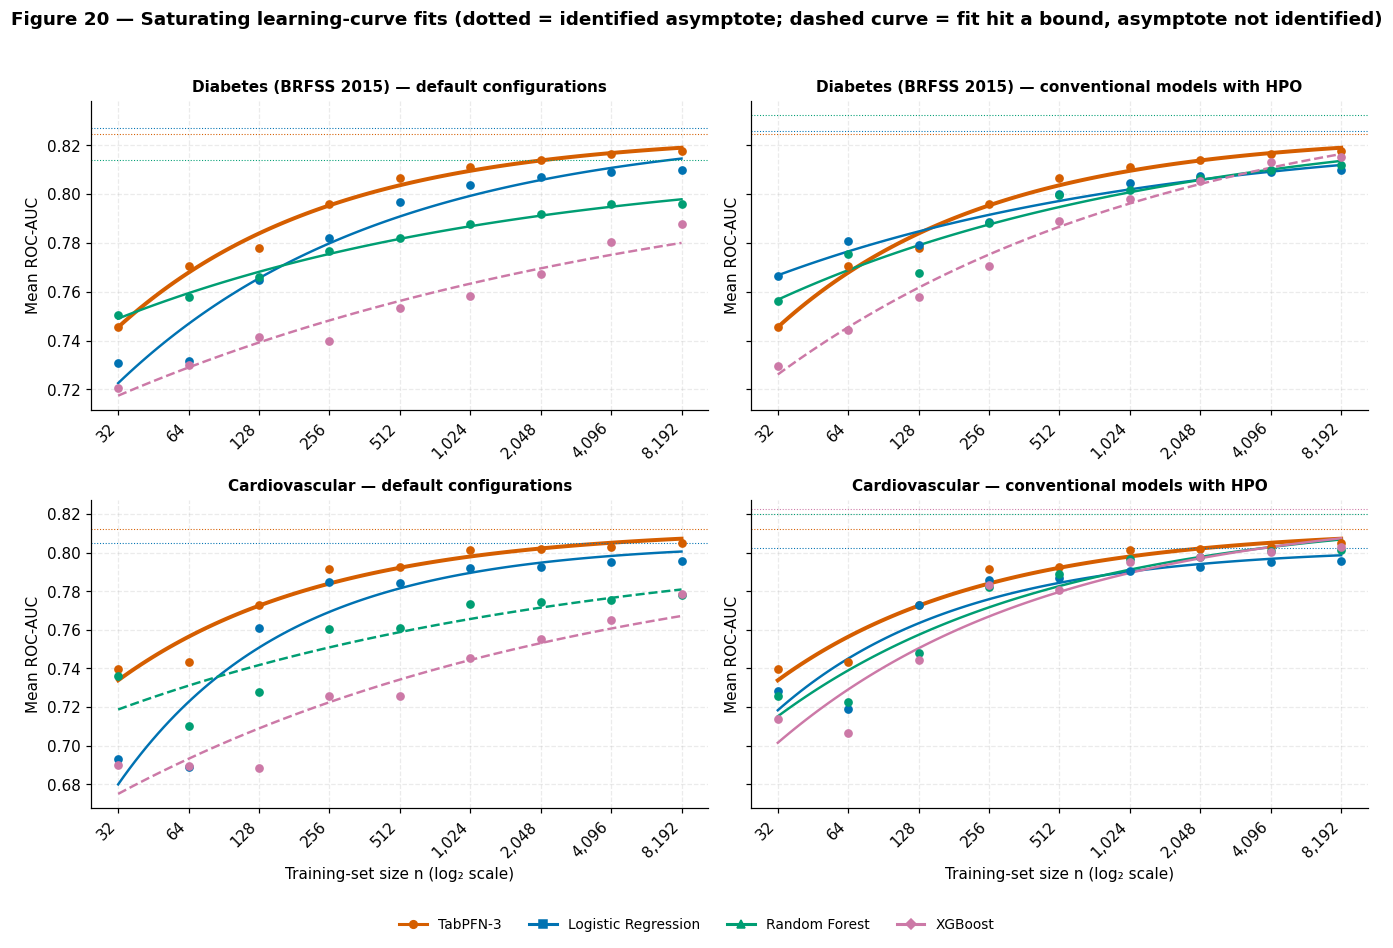

In [22]:
# ============================================================
# Cell 20 - Descriptive Learning-Curve Fits
# ============================================================

# Descriptive power-law model:
# AUC(n) = a - d * (n / 32)^(-c)
#
# a: asymptotic AUC estimate
# d: gap at the reference size n = 32
# c: rate at which the gap decreases with increasing n
def power_law(n, a, d, c):
    return a - d * (np.asarray(n, float) / 32.0) ** (-c)


def fit_learning_curve(sizes, means, min_n=32):
    """Fit the power-law model to mean ROC-AUC values at n >= min_n."""

    sizes = np.asarray(sizes, float)
    means = np.asarray(means, float)

    # Restrict the fit to the larger training sizes to avoid extrapolating
    # the power-law form into the smallest-data region.
    keep = sizes >= min_n
    x, y = sizes[keep], means[keep]

    # Bound the asymptote to at most 0.03 above the best observed mean.
    # This limits unsupported extrapolation beyond the observed range.
    lower, upper = (
        [float(y.max()), 0.0, 0.05],
        [min(1.0, float(y.max()) + 0.03), 0.6, 4.0],
    )

    # Initialize the optimiser near the observed performance range.
    p0 = [
        min(float(y.max()) + 0.01, 1.0),
        max(float(y.max() - y[0]), 0.01),
        0.7,
    ]
    p0 = [
        float(np.clip(v, lo, hi))
        for v, lo, hi in zip(p0, lower, upper)
    ]

    try:
        popt, _ = optimize.curve_fit(
            power_law,
            x,
            y,
            p0=p0,
            bounds=(lower, upper),
            maxfev=20000,
        )
    except Exception:
        # Return missing estimates rather than stopping the full analysis
        # if a particular model/condition cannot be fitted.
        return {
            "a": np.nan,
            "d": np.nan,
            "c": np.nan,
            "r2": np.nan,
            "at_bound": True,
        }

    # Calculate residuals and descriptive R² on the fitted observations.
    resid = y - power_law(x, *popt)
    ss_res = (resid ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    # Flag fits constrained by parameter bounds. In particular, a bound on
    # the asymptote or rate means the data do not identify that parameter well.
    at_bound = bool(
        np.isclose(popt[0], upper[0], atol=1e-4)
        or np.isclose(popt[2], lower[2], atol=1e-3)
        or np.isclose(popt[2], upper[2], atol=1e-3)
    )

    return {
        "a": popt[0],
        "d": popt[1],
        "c": popt[2],
        "r2": r2,
        "at_bound": at_bound,
    }


# ------------------------------------------------------------
# Fit learning curves for every condition, dataset, and model
# ------------------------------------------------------------

fit_rows = []

for cond in PANEL:
    st = cell_stats(PANEL[cond], "roc_auc")

    for ds in EXPECTED_DATASETS:
        for model in MODELS4:
            g = (
                st[
                    (st.dataset == ds)
                    & (st.model == model)
                ]
                .sort_values("training_size")
            )

            f = fit_learning_curve(
                g.training_size,
                g["mean"],
            )

            fit_rows.append(
                {
                    "condition": cond,
                    "dataset": ds,
                    "model": model,
                    **f,
                    "auc_at_largest_n": g["mean"].iat[-1],
                    "remaining_gap_to_asymptote": (
                        f["a"] - g["mean"].iat[-1]
                    ),
                }
            )

lc_fits = pd.DataFrame(fit_rows)

lc_fits.to_csv(
    TABLES_DIR / "rq3_learning_curve_fits.csv",
    index=False,
)

print(
    "Fitted asymptote a, curvature d, rate c "
    "(fit on n ≥ 32; 9 points, 3 parameters — descriptive, not inferential)."
)
print(
    "at_bound = True: the optimiser stopped on a parameter bound, "
    "so the asymptote is NOT identified by the data; do not interpret it."
)

display(lc_fits)


# ------------------------------------------------------------
# Figure 20: Observed learning curves and fitted power laws
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12.5, 8.4),
    sharey="row",
)

# Dense geometric grid for displaying the fitted curves smoothly.
grid = np.geomspace(32, 8192, 100)

for r, ds in enumerate(EXPECTED_DATASETS):
    for c, cond in enumerate(("default", "hpo")):
        ax = axes[r, c]
        st = cell_stats(PANEL[cond], "roc_auc")

        for model in MODELS4:
            # Plot only the observations included in the power-law fit.
            g = (
                st[
                    (st.dataset == ds)
                    & (st.model == model)
                    & (st.training_size >= 32)
                ]
                .sort_values("training_size")
            )

            # Observed seed-mean ROC-AUC values.
            ax.scatter(
                g.training_size,
                g["mean"],
                color=COLORS[model],
                s=22,
                zorder=4,
            )

            # Retrieve the corresponding fitted parameters.
            f = lc_fits[
                (lc_fits.condition == cond)
                & (lc_fits.dataset == ds)
                & (lc_fits.model == model)
            ].iloc[0]

            if np.isfinite(f["a"]):
                # Solid = fit not constrained by a parameter bound.
                # Dashed = fit hit a bound; asymptote should not be interpreted.
                ax.plot(
                    grid,
                    power_law(
                        grid,
                        f["a"],
                        f["d"],
                        f["c"],
                    ),
                    color=COLORS[model],
                    lw=2.6 if model == "tabpfn" else 1.6,
                    ls="--" if f["at_bound"] else "-",
                )

                # Display the fitted asymptote only when it is identified
                # without hitting one of the imposed parameter bounds.
                if not f["at_bound"]:
                    ax.axhline(
                        f["a"],
                        color=COLORS[model],
                        lw=0.7,
                        ls=":",
                    )

        ax.set_title(
            f"{DATASET_LABELS[ds]} — {COND_TITLE[cond]}",
            fontsize=10,
        )
        ax.set_ylabel("Mean ROC-AUC")
        size_axis(ax, SIZES_HPO)


fig.legend(
    handles=model_handles(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.01),
)

fig.suptitle(
    "Figure 20 — Saturating learning-curve fits "
    "(dotted = identified asymptote; dashed curve = fit hit a bound, "
    "asymptote not identified)",
    fontweight="bold",
    y=1.0,
)

fig.tight_layout(rect=[0, 0.04, 1, 0.98])

save_fig(
    fig,
    "fig20_rq3_learning_curve_fits",
)

In [23]:
# ============================================================
# Cell 21 - RQ3 Automatically Generated Findings
# ============================================================

def rq3_findings():
    # Build the findings report directly from the computed RQ3 tables.
    lines = ["### RQ3 — computed findings"]

    # --------------------------------------------------------
    # Pooled stability: conventional SD / TabPFN SD
    # --------------------------------------------------------

    for cond in ("default", "hpo"):
        lines.append(
            f"\n**Pooled seed-level SD ratio "
            f"(conventional ÷ TabPFN-3), {COND_TITLE[cond]}** "
            "(>1 ⇒ TabPFN-3 varies less across subsets)"
        )

        for ds in EXPECTED_DATASETS:
            parts = []

            for name in REGIME_ORDER:
                sub = pooled_ratio[
                    (pooled_ratio.condition == cond)
                    & (pooled_ratio.dataset == ds)
                    & (pooled_ratio.regime == name)
                ]

                if sub.empty:
                    continue

                # Keep the conventional-model order consistent with
                # the rest of the thesis: LR / RF / XGB.
                values = (
                    sub.set_index("model")
                    .loc[
                        list(TRADITIONAL_MODELS),
                        "sd_ratio_conventional_over_tabpfn",
                    ]
                )

                parts.append(
                    f"{name}: "
                    + "/".join(f"{v:.1f}×" for v in values)
                )

            lines.append(
                f"- {DATASET_LABELS[ds]} (LR/RF/XGB): "
                + " · ".join(parts)
            )

    # --------------------------------------------------------
    # Per-cell stability frequency
    # --------------------------------------------------------

    # Fraction of dataset × model × training-size cells where
    # conventional SD / TabPFN SD > 1, meaning TabPFN has the
    # smaller seed-level SD in that cell.
    frac = (
        per_size_flag
        .assign(more=per_size_flag.ratio > 1)
        .groupby(["condition"])["more"]
        .mean()
    )

    lines.append(
        "\nShare of (dataset × model × size) cells in which "
        "TabPFN-3 has the smaller SD: "
        + ", ".join(
            f"{COND_TITLE[c]} {v:.0%}"
            for c, v in frac.items()
        )
        + " (single-cell SDs come from only five seeds)."
    )

    # --------------------------------------------------------
    # Shared subset effect
    # --------------------------------------------------------

    # Average the derived shared-variance statistic across all
    # dataset/model combinations within each training-size regime.
    sh = (
        shared
        .assign(regime=shared.training_size.map(regime_of))
        .groupby("regime")["shared_variance_share"]
        .mean()
        .reindex(REGIME_ORDER)
    )

    lines.append(
        "\nMean shared-variance share between TabPFN-3 and "
        "the other models by regime: "
        + ", ".join(
            f"{k} {v:.2f}"
            for k, v in sh.items()
        )
        + "."
    )

    # --------------------------------------------------------
    # SD trend with increasing training size
    # --------------------------------------------------------

    # Average the fitted log-log slopes across datasets for each model.
    tr = (
        sd_trends[sd_trends.condition == "default"]
        .groupby("model")["log2_sd_slope_per_doubling"]
        .mean()
    )

    lines.append(
        "Mean slope of log₂(SD) per doubling of n (default): "
        + ", ".join(
            f"{MODEL_LABELS[m]} {v:+.2f}"
            for m, v in tr.items()
        )
        + "."
    )

    # --------------------------------------------------------
    # Descriptive learning-curve asymptotes
    # --------------------------------------------------------

    # Report only fits that did not hit a parameter bound.
    # Bound-constrained fits are intentionally excluded because
    # their asymptotes are not identified by the observed data.
    ok = lc_fits[
        (lc_fits.condition == "default")
        & (~lc_fits.at_bound)
    ]

    identified = "; ".join(
        f"{DATASET_LABELS[d]}: "
        + (
            ", ".join(
                f"{MODEL_LABELS[r.model]} {r.a:.3f}"
                for r in g.itertuples()
            )
            or "none"
        )
        for d, g in ok.groupby("dataset")
    )

    default_fits = lc_fits[
        lc_fits.condition == "default"
    ]

    lines.append(
        "Identified ROC-AUC asymptotes "
        "(default, n ≥ 32; fits on a bound are omitted): "
        + identified
        + f". Fits on a bound: "
        + f"{int(default_fits.at_bound.sum())}/{len(default_fits)}."
    )

    return "\n".join(lines)


# Generate and render the findings from the current RQ3 analysis objects.
rq3_text = rq3_findings()
display(Markdown(rq3_text))

### RQ3 — computed findings

**Pooled seed-level SD ratio (conventional ÷ TabPFN-3), default configurations** (>1 ⇒ TabPFN-3 varies less across subsets)
- Diabetes (BRFSS 2015) (LR/RF/XGB): tiny (8–16): 0.9×/1.0×/0.9× · small (32–128): 0.9×/0.7×/0.7× · medium (256–1,024): 3.0×/1.4×/3.1× · large (2,048–8,192): 1.6×/5.7×/8.1×
- Cardiovascular (LR/RF/XGB): tiny (8–16): 1.1×/1.1×/0.6× · small (32–128): 1.0×/1.0×/1.3× · medium (256–1,024): 1.1×/1.4×/2.2× · large (2,048–8,192): 0.7×/3.9×/4.7×

**Pooled seed-level SD ratio (conventional ÷ TabPFN-3), conventional models with HPO** (>1 ⇒ TabPFN-3 varies less across subsets)
- Diabetes (BRFSS 2015) (LR/RF/XGB): small (32–128): 0.8×/0.6×/0.8× · medium (256–1,024): 2.0×/2.0×/2.6× · large (2,048–8,192): 1.5×/4.2×/5.3×
- Cardiovascular (LR/RF/XGB): small (32–128): 1.0×/1.2×/1.0× · medium (256–1,024): 0.8×/2.0×/2.5× · large (2,048–8,192): 0.7×/1.2×/1.3×

Share of (dataset × model × size) cells in which TabPFN-3 has the smaller SD: default configurations 68%, conventional models with HPO 57% (single-cell SDs come from only five seeds).

Mean shared-variance share between TabPFN-3 and the other models by regime: tiny (8–16) 0.68, small (32–128) 0.56, medium (256–1,024) 0.38, large (2,048–8,192) 0.12.
Mean slope of log₂(SD) per doubling of n (default): Logistic Regression -0.82, Random Forest -0.53, TabPFN-3 -0.82, XGBoost -0.54.
Identified ROC-AUC asymptotes (default, n ≥ 32; fits on a bound are omitted): Cardiovascular: TabPFN-3 0.812, Logistic Regression 0.805; Diabetes (BRFSS 2015): TabPFN-3 0.825, Logistic Regression 0.827, Random Forest 0.814. Fits on a bound: 3/8.

## 5 · Synthesis, limitations and hand-off to the thesis text

### Interpretation guide (hypotheses to discuss — *not* tested here)
* **Default XGBoost trails most.** It has the largest average HPO gain (diabetes +2.7 pts, cardiovascular +4.0 pts), peaking at mid training sizes (cardiovascular +5.4 pts for n = 256–1,024). A possible explanation is that library defaults (deep trees, high learning rate) overfit small balanced samples; the HPO gains are consistent with this but do not test it.
* **Logistic Regression is the closest competitor at large n.** At default settings TabPFN-3's advantage over LR at n ≥ 2,048 is +0.7 pts (diabetes) and +0.9 pts (cardiovascular), versus +2.1 to +3.7 pts for Random Forest and XGBoost. HPO changes LR by less than 1 pt at n ≥ 256, so its default is near-optimal from that size, but at n ≤ 128 tuning improves LR by about 1–5 pts, and tuned LR overtakes TabPFN-3 on diabetes at n = 32–128. A possible explanation is that the risk factors in both datasets act largely monotonically, which a regularised linear model captures well.
* **The TabPFN-3 advantage persists at n = 8,192 but is small after tuning.** With tuned conventional models the gap is 0.2–1.0 pts, still in TabPFN-3's favour in all five seeds. At default settings Random Forest and XGBoost remain 2–4 pts behind, so convergence to a common level is observed only after tuning. Whether this level is a ceiling set by the noise in these survey features is not tested here; the fitted asymptotes (§4.3) are identified for only some models.
* **Tiny n (8–16 rows).** The subset draw matters a great deal (Figures 1–2) but not uniformly. Against Logistic Regression and Random Forest there is no consistent winner (TabPFN-3 wins 30–70 % of seeds, mean Δ between −0.9 and −0.1 pts), whereas TabPFN-3 beats default XGBoost in 70–80 % of seeds (+3.1 to +5.5 pts).

### Limitations to state in the thesis
1. **Five subset seeds** → low power; t-intervals (df = 4) are wide, SD estimates are noisy, and *no* significance test is claimed.
2. **One fixed test split** (seed 42) and subsets drawn *independently* per size (not nested) → learning-curve wiggles between adjacent sizes are draw effects.
3. **Uncertainty from test-set sampling and from the training pool is not propagated**; all subsets come from a single 80 % pool.
4. **Asymmetric tuning:** conventional models receive 20-configuration random search on small grids; TabPFN-3 receives none (as in the exposé).
   A tuned TabPFN or a larger search would change RQ2.
5. **Model-side randomness fixed** (`model_seed = 42`): stability here is *subset* stability only; TabPFN-3's ensemble randomness and GPU non-determinism are not varied.
6. **Duplicate removal before splitting** changes the class prevalence (diabetes 13.9 % → 15.3 %) and removes the easiest repeated profiles; results describe the de-duplicated distribution.
7. **Balanced training vs natural test prevalence** shifts every threshold-0.5 metric (§2.7); ROC-/PR-AUC are the primary evidence.
8. **Two health datasets** (survey-based, binary outcomes) — generalisation to other clinical data is not established.
9. **Learning-curve fits and equivalent-n figures are descriptive** (few points, monotone-envelope assumption).

In [24]:
# ============================================================
# Cell 22 — Scorecard across the three research questions
# ============================================================
score_rows = []
for ds in EXPECTED_DATASETS:
    d1 = gap_default["roc_auc"][gap_default["roc_auc"].dataset == ds]
    d1_ge32 = d1[d1.training_size >= 32]
    d2 = outcome[outcome.dataset == ds]
    d3 = per_size_flag[per_size_flag.dataset == ds]
    score_rows.append({
        "dataset": ds,
        "RQ1: cells TabPFN-3 ahead (seed-mean), all n": (d1["mean"] > 0).mean(),
        "RQ1: cells ahead in 5/5 seeds, n ≥ 32": (d1_ge32["wins"] == N_SEEDS).mean(),
        "RQ2: cells still ahead after HPO (seed-mean)": (d2["mean_hpo"] > 0).mean(),
        "RQ2: cells ahead after HPO in 5/5 seeds": (d2["wins_hpo"] == N_SEEDS).mean(),
        "RQ3: cells where TabPFN-3 has the smaller SD": (d3["ratio"] > 1).mean(),
    })
scorecard = pd.DataFrame(score_rows).set_index("dataset")
scorecard.to_csv(TABLES_DIR / "scorecard.csv")
display(scorecard.round(3))

,"RQ1: cells TabPFN-3 ahead (seed-mean), all n","RQ1: cells ahead in 5/5 seeds, n ≥ 32",RQ2: cells still ahead after HPO (seed-mean),RQ2: cells ahead after HPO in 5/5 seeds,RQ3: cells where TabPFN-3 has the smaller SD
dataset,,,,,
diabetes,0.8480,0.8150,0.8150,0.5930,0.6500
cardiovascular,0.9390,0.9260,1.0000,0.7780,0.6170


In [25]:
# ============================================================
# Cell 23 — Export tables, findings, manifest; final audit
# ============================================================
seed_results.to_csv(TABLES_DIR / "seed_results_long.csv", index=False)
pairs.to_csv(TABLES_DIR / "paired_differences_long.csv", index=False)
(ANALYSIS_DIR / "findings.md").write_text("\n\n".join([rq1_text, rq2_text, rq3_text]), encoding="utf-8")


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


manifest_out = {
    "protocol_version": PROTOCOL_VERSION,
    "tabpfn_model_version": TABPFN_MODEL_VERSION,
    "inputs": {k: {"path": str(p), "sha256": sha256(p), "rows": int(len(raw_results[k]))} for k, p in RESULT_PATHS.items()},
    "environment": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                    "matplotlib": mpl.__version__, "scipy": __import__("scipy").__version__},
    "design": {"datasets": list(EXPECTED_DATASETS), "training_sizes": list(SIZES_ALL), "hpo_training_sizes": list(SIZES_HPO),
               "subset_seeds": list(SUBSET_SEEDS), "test_size": TEST_SIZE, "test_seed": TEST_SEED, "model_seed": MODEL_SEED,
               "cv_seed": CV_SEED, "hpo_seed": HPO_SEED, "classification_threshold": CLASSIFICATION_THRESHOLD},
    "test_prevalence": {"values": PREVALENCE, "source": PREVALENCE_SOURCE},
    "statistics": {"interval": "t-based 95% CI over 5 subset seeds (df=4) on paired differences",
                   "stability": "sample SD (ddof=1) of ROC-AUC across subset seeds; pooled by regime as sqrt(mean variance)",
                   "significance_tests": "none (5 seeds); win counts and CIs are descriptive"},
    "timing_columns": "dropped: runs were not executed on a unified hardware setup",
    "figures": FIGURE_LOG,
    "tables": sorted(p.name for p in TABLES_DIR.glob("*.csv")),
}
(ANALYSIS_DIR / "analysis_manifest.json").write_text(json.dumps(manifest_out, indent=2, default=str), encoding="utf-8")

# ---- audit ----
assert len(pairs_default) == expected_baseline_runs() * len(PAIR_METRICS)
assert len(pairs_hpo) == expected_hpo_runs() * len(PAIR_METRICS)
assert len(direct) == expected_hpo_runs()
assert all((FIGURES_DIR / f"{stem}.png").exists() and (FIGURES_DIR / f"{stem}.pdf").exists() for stem in FIGURE_LOG)
for cond, panel in PANEL.items():
    assert (cell_stats(panel, "roc_auc")["n"] == N_SEEDS).all()
assert np.isfinite(pooled_ratio["sd_ratio_conventional_over_tabpfn"]).all()

print("=" * 72)
print("NOTEBOOK 06 — ANALYSIS COMPLETE")
print("=" * 72)
print(f"✓ Figures: {len(FIGURE_LOG)} (PNG 300 dpi + PDF)  → {FIGURES_DIR}")
print(f"✓ Tables:  {len(list(TABLES_DIR.glob('*.csv')))} CSV files → {TABLES_DIR}")
print(f"✓ Findings text: {ANALYSIS_DIR / 'findings.md'}")
print(f"✓ Manifest with input hashes: {ANALYSIS_DIR / 'analysis_manifest.json'}")

NOTEBOOK 06 — ANALYSIS COMPLETE
✓ Figures: 20 (PNG 300 dpi + PDF)  → /kaggle/working/analysis_nb06/figures
✓ Tables:  36 CSV files → /kaggle/working/analysis_nb06/tables
✓ Findings text: /kaggle/working/analysis_nb06/findings.md
✓ Manifest with input hashes: /kaggle/working/analysis_nb06/analysis_manifest.json
